### Imports and Preprocessing

In [ ]:
pip install umap-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.cross_decomposition import CCA
from umap import UMAP
from sklearn.metrics import f1_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
X = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X.csv')

In [ ]:
y = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/idr0088-screenA-annotation.csv')

In [ ]:
X = X.merge(y, how = 'inner')

In [ ]:
X = X.drop('Cell_ShapeSize_Area.cv', axis = 1)

In [ ]:
X

,Unnamed: 0,Plate,Well,QC_FieldCount,Cell_GFP2RFP_PearsonCor.mean,Cell_GFP2RFP_PearsonCor.median,Cell_GFP_CVInt.mean,Cell_GFP_CVInt.median,Cell_GFP_CVIntBC.mean,Cell_GFP_CVIntBC.median,...,Compound MoA,Compound Name,Compound ID - Artificial,Compound SMILES,Compound InChIKey,Compound PubChem CID,Compound PubChem URL,Control Type,Channels,Plate Location
0,0,1013608204,B2,3,0.524380,0.589377,0.537231,0.535792,0.782484,0.604300,...,NaN,DMSO,NaN,NaN,NaN,NaN,NaN,Negative Control,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): TUB...",p171214PPS130/PpsL05A549TubARelA_PPS130_201712...
1,1,1013608204,B3,3,0.514857,0.573730,0.542103,0.532554,0.760801,0.600998,...,Glycosylase inhibitor,Kifunensine,CPD0575,O=C1N[C@@H]2[C@@H](O)[C@@H](O)[C@H](O)[C@@H](C...,OIURYJWYVIAOCW-PQMKYFCFSA-N,130611.0,https://pubchem.ncbi.nlm.nih.gov/compound/130611,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): TUB...",p171214PPS130/PpsL05A549TubARelA_PPS130_201712...
2,2,1013608204,B4,3,0.539474,0.562932,0.515349,0.516657,0.634557,0.583269,...,Glycosylase inhibitor,Kifunensine,CPD0575,O=C1N[C@@H]2[C@@H](O)[C@@H](O)[C@H](O)[C@@H](C...,OIURYJWYVIAOCW-PQMKYFCFSA-N,130611.0,https://pubchem.ncbi.nlm.nih.gov/compound/130611,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): TUB...",p171214PPS130/PpsL05A549TubARelA_PPS130_201712...
3,3,1013608204,B5,3,0.514737,0.567022,0.520418,0.508830,0.713415,0.576769,...,Glycosylase inhibitor,Kifunensine,CPD0575,O=C1N[C@@H]2[C@@H](O)[C@@H](O)[C@H](O)[C@@H](C...,OIURYJWYVIAOCW-PQMKYFCFSA-N,130611.0,https://pubchem.ncbi.nlm.nih.gov/compound/130611,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): TUB...",p171214PPS130/PpsL05A549TubARelA_PPS130_201712...
4,4,1013608204,B6,3,0.497873,0.568638,0.524204,0.523279,0.759141,0.595867,...,Glycosylase inhibitor,Kifunensine,CPD0575,O=C1N[C@@H]2[C@@H](O)[C@@H](O)[C@H](O)[C@@H](C...,OIURYJWYVIAOCW-PQMKYFCFSA-N,130611.0,https://pubchem.ncbi.nlm.nih.gov/compound/130611,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): TUB...",p171214PPS130/PpsL05A549TubARelA_PPS130_201712...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313667,275,110000263698,O19,2,0.309275,0.306187,1.109961,1.130673,2.345188,2.221014,...,Hyperpolarization-activated cyclic nucleotide-...,ZD-7288,CPD1165,CCN(c1ccccc1)c2cc(NC)[n+](C)c(C)n2,JABSKGQQWUDVRU-UHFFFAOYSA-O,3938007.0,https://pubchem.ncbi.nlm.nih.gov/compound/3938007,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): GM1...",p180317PPS149/PpsL05WPMY1Gm130Sqstm1_PPS149_20...
313668,276,110000263698,O20,2,0.288854,0.273649,1.240343,1.265159,2.484865,2.411265,...,Hyperpolarization-activated cyclic nucleotide-...,ZD-7288,CPD1165,CCN(c1ccccc1)c2cc(NC)[n+](C)c(C)n2,JABSKGQQWUDVRU-UHFFFAOYSA-O,3938007.0,https://pubchem.ncbi.nlm.nih.gov/compound/3938007,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): GM1...",p180317PPS149/PpsL05WPMY1Gm130Sqstm1_PPS149_20...
313669,277,110000263698,O21,2,0.283362,0.270510,1.015437,1.043611,2.307389,2.279742,...,Hyperpolarization-activated cyclic nucleotide-...,ZD-7288,CPD1165,CCN(c1ccccc1)c2cc(NC)[n+](C)c(C)n2,JABSKGQQWUDVRU-UHFFFAOYSA-O,3938007.0,https://pubchem.ncbi.nlm.nih.gov/compound/3938007,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): GM1...",p180317PPS149/PpsL05WPMY1Gm130Sqstm1_PPS149_20...
313670,278,110000263698,O22,2,0.334864,0.318578,1.016075,1.077661,2.206084,2.136808,...,Hyperpolarization-activated cyclic nucleotide-...,ZD-7288,CPD1165,CCN(c1ccccc1)c2cc(NC)[n+](C)c(C)n2,JABSKGQQWUDVRU-UHFFFAOYSA-O,3938007.0,https://pubchem.ncbi.nlm.nih.gov/compound/3938007,NaN,"Ch1 (blue): Nuclei/Cytoplasm, Ch2 (green): GM1...",p180317PPS149/PpsL05WPMY1Gm130Sqstm1_PPS149_20...


In [ ]:
X.columns[-20:]

Index(['Ratio_Nuc2Cyto_RFP_TotalIntBC.median', 'Characteristics [Organism]',
       'Term Source 1 REF', 'Term Source 1 Accession',
       'Characteristics [Cell Line]', 'Term Source 2 REF',
       'Term Source 2 Accession', 'Comment [Cell Line with Markers]',
       'Compound Concentration (microMolar)', 'Compound Set', 'Compound MoA',
       'Compound Name', 'Compound ID - Artificial', 'Compound SMILES',
       'Compound InChIKey', 'Compound PubChem CID', 'Compound PubChem URL',
       'Control Type', 'Channels', 'Plate Location'],
      dtype='object')

### Projection Pursuit


In [ ]:
X.sample(25000).to_csv('/content/drive/MyDrive/smallmoleculedata/X_samp.csv')

In [ ]:
X_sample = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_sample_1008.csv')

In [ ]:
X_samp = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_samp_1008.csv')

In [ ]:
X_samp['Projection 1.2'] = X_sample['Projection 1.2']
X_samp['Projection 2.2'] = X_sample['Projection 2.2']
X_samp['Projection 1.1'] = X_sample['Projection 1.1']
X_samp['Projection 2.1'] = X_sample['Projection 2.1']
X_samp['Projection 1'] = X_sample['Projection 1']
X_samp['Projection 2'] = X_sample['Projection 2']

In [ ]:
hermite_df = X_samp[['Projection 1.1','Projection 2.1']]

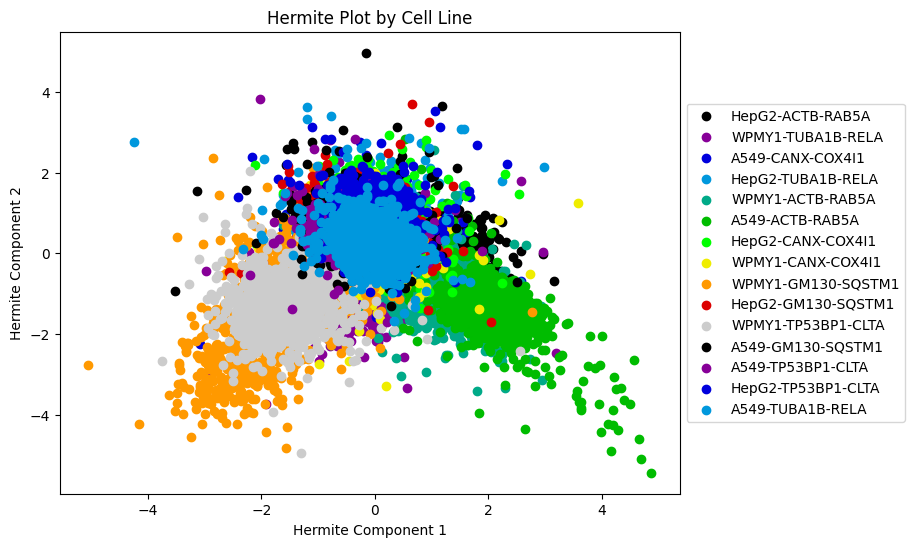

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Hermite Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X_samp['Comment [Cell Line with Markers]'].unique():
  plt.scatter(X_samp[X_samp['Comment [Cell Line with Markers]']==i]['Projection 1.1'], X_samp[X_samp['Comment [Cell Line with Markers]']==i]['Projection 2.1'], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Hermite Component 1')
plt.ylabel('Hermite Component 2')
plt.show()

### Modeling

In [ ]:
# Get list of column names
columns = X.columns.tolist()
# Choose a random column
random_column = random.choice(columns)

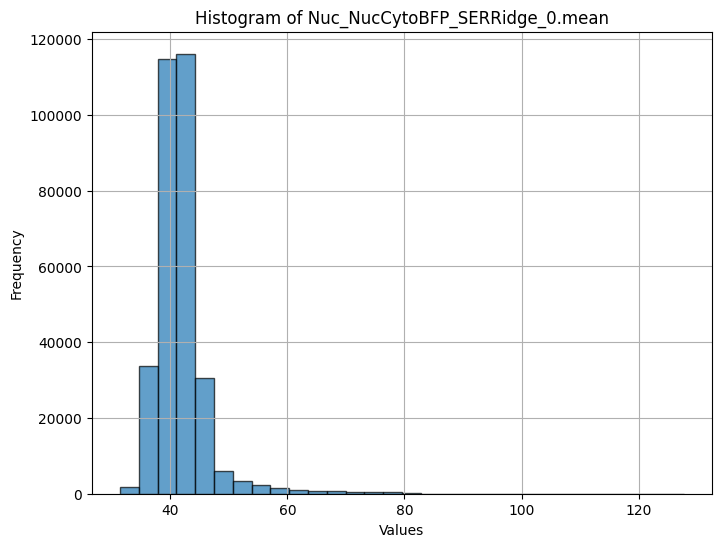

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(X[random_column], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title(f'Histogram of {random_column}')
plt.grid(True)
plt.show()

In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X[X.columns[4:979]])

In [ ]:
pca = PCA(n_components=4)  # Specify the number of principal components to keep
X_pca = pca.fit_transform(Xs)

In [ ]:
df = X_pca

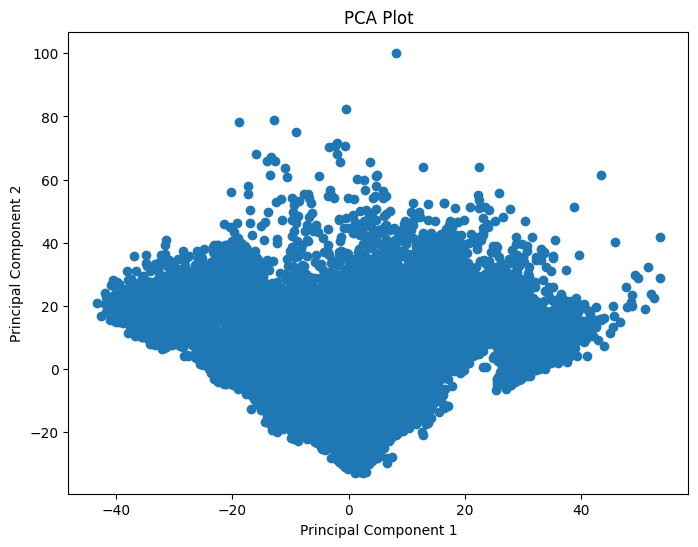

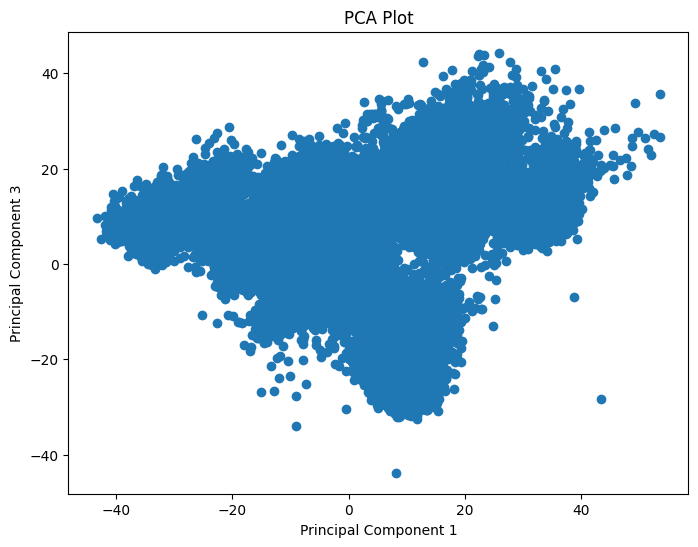

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(df[:,0], df[:,1])
plt.title('PCA Plot')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()
plt.figure(figsize=(8, 6))
plt.scatter(df[:,0], df[:,2])
plt.title('PCA Plot')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 3')
plt.show()

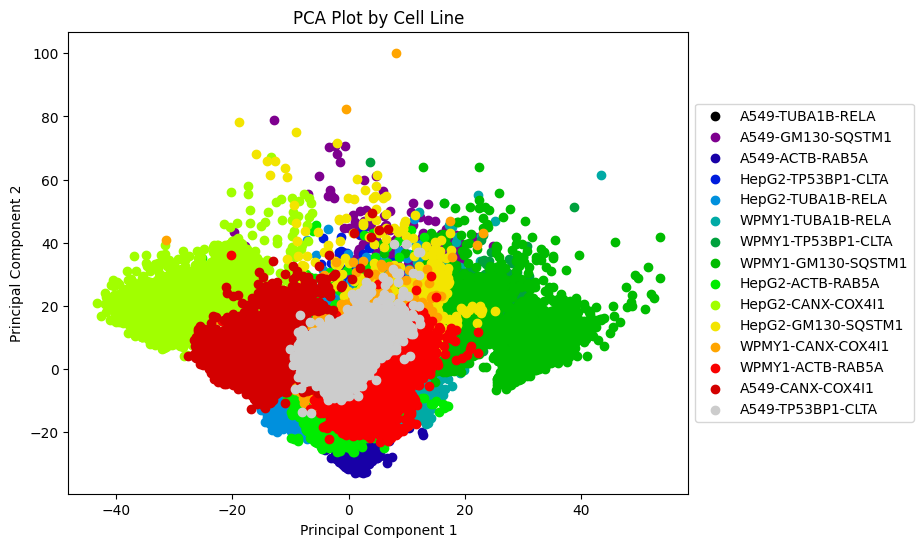

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

In [ ]:
# plate_pca_1_mean = []
# plate_pca_2_mean = []
# for i in X['Compound MoA'].unique():
#   plate_pca_1_mean.append(X_pca[X['Compound MoA']==i,0].mean())
#   plate_pca_2_mean.append(X_pca[X['Compound MoA']==i,1].mean())

In [ ]:
# plt.scatter(plate_pca_1_mean, plate_pca_2_mean)

In [ ]:
# plate_pca_1_mean = []
# plate_pca_2_mean = []
# for i in X['Plate'].unique():
#   plate_pca_1_mean.append(X_pca[X['Plate']==i,0].mean())
#   plate_pca_2_mean.append(X_pca[X['Plate']==i,1].mean())

In [ ]:
# plt.scatter(plate_pca_1_mean, plate_pca_2_mean)

In [ ]:
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
X_tsne_10 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42)
X_tsne_30 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42, perplexity=50)
X_tsne_50 = tsne.fit_transform(Xs)

In [ ]:
X_tsne = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_tsne.csv')

In [ ]:
X_tsne = X_tsne.drop('Unnamed: 0', axis = 1).values

In [ ]:
df = X_tsne_10

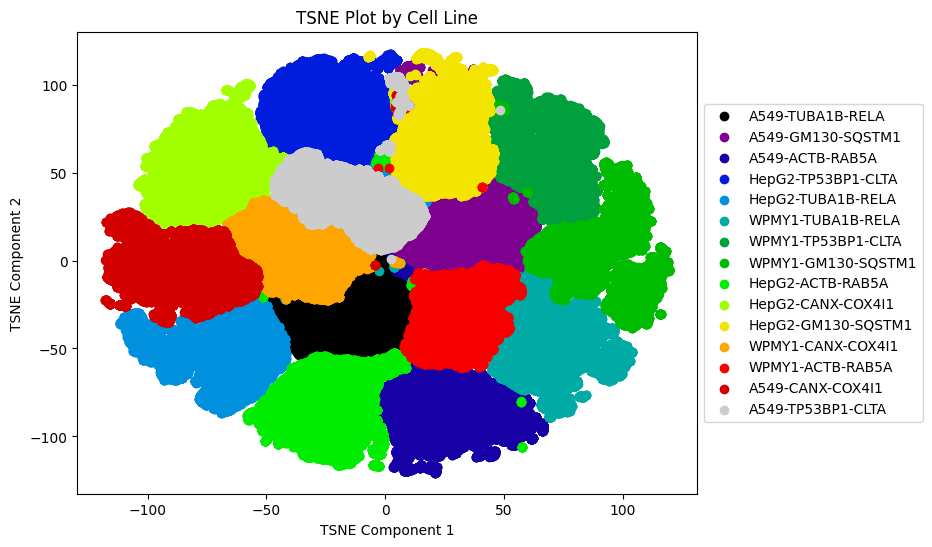

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne

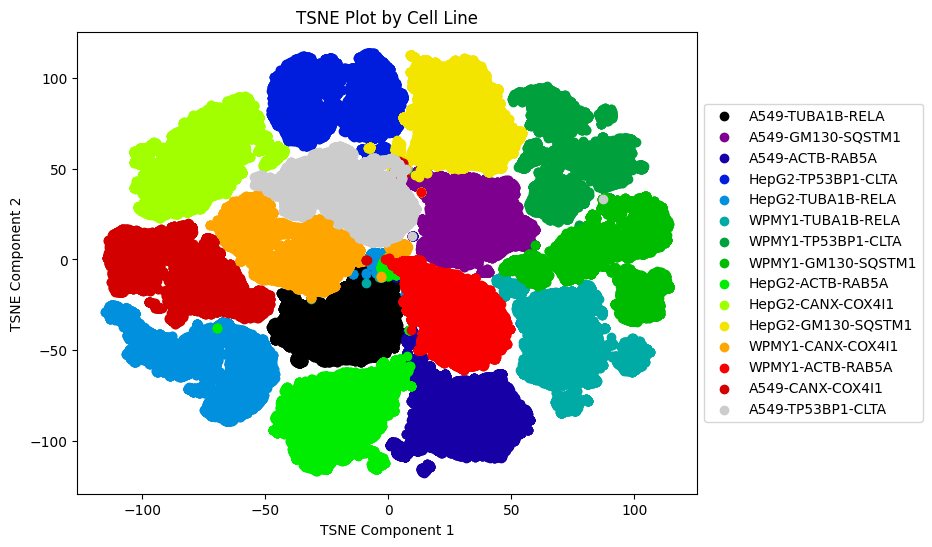

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_50

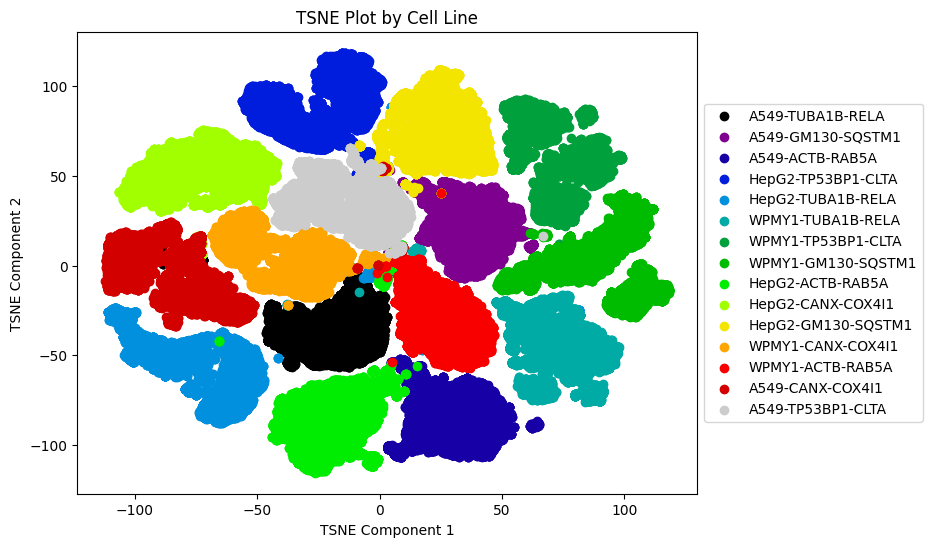

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
# plate_tsne_1_mean = []
# plate_tsne_2_mean = []
# for i in X['Compound MoA'].unique():
#   plate_tsne_1_mean.append(X_tsne[X['Compound MoA']==i,0].mean())
#   plate_tsne_2_mean.append(X_tsne[X['Compound MoA']==i,1].mean())

In [ ]:
# plt.scatter(plate_tsne_1_mean, plate_tsne_2_mean)

In [ ]:
# plate_tsne_1_mean = []
# plate_tsne_2_mean = []
# for i in X['Plate'].unique():
#   plate_tsne_1_mean.append(X_tsne[X['Plate']==i,0].mean())
#   plate_tsne_2_mean.append(X_tsne[X['Plate']==i,1].mean())

In [ ]:
# plt.scatter(plate_tsne_1_mean, plate_tsne_2_mean)

In [ ]:
umap = UMAP(n_components=2, random_state=42, n_neighbors=10)
X_umap_10 = umap.fit_transform(Xs)
umap = UMAP(n_components=2, random_state=42)
X_umap_30 = umap.fit_transform(Xs)
umap = UMAP(n_components=2, random_state=42, n_neighbors=50)
X_umap_50 = umap.fit_transform(Xs)

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [ ]:
# X_umap = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_umap.csv')

In [ ]:
# X_umap = X_umap.drop('Unnamed: 0', axis = 1).values

In [ ]:
df = X_umap_10

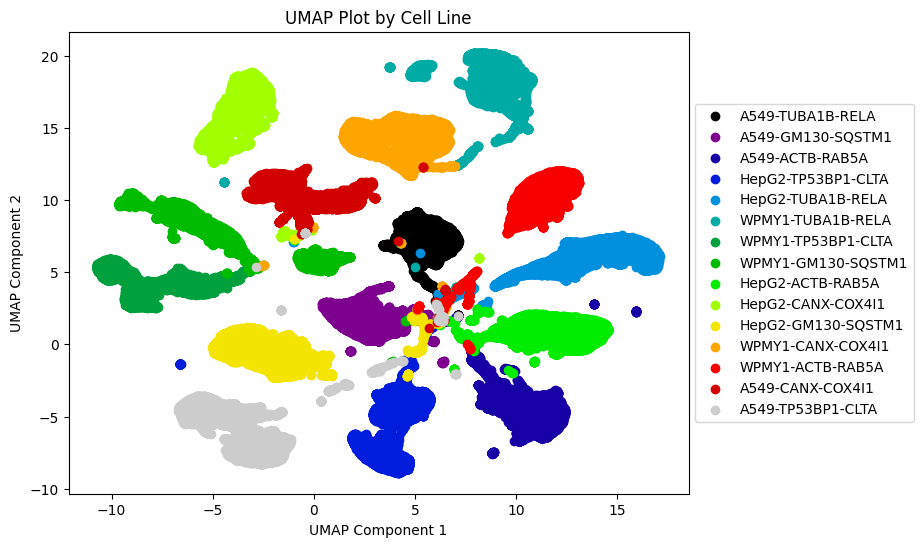

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
# plate_umap_1_mean = []
# plate_umap_2_mean = []
# for i in X['Compound MoA'].unique():
#   plate_umap_1_mean.append(X_umap[X['Compound MoA']==i,0].mean())
#   plate_umap_2_mean.append(X_umap[X['Compound MoA']==i,1].mean())

In [ ]:
# plt.scatter(plate_umap_1_mean, plate_umap_2_mean)

In [ ]:
# plate_umap_1_mean = []
# plate_umap_2_mean = []
# for i in X['Plate'].unique():
#   plate_umap_1_mean.append(X_umap[X['Plate']==i,0].mean())
#   plate_umap_2_mean.append(X_umap[X['Plate']==i,1].mean())

In [ ]:
# plt.scatter(plate_umap_1_mean, plate_umap_2_mean)

In [ ]:
df = X_umap_30

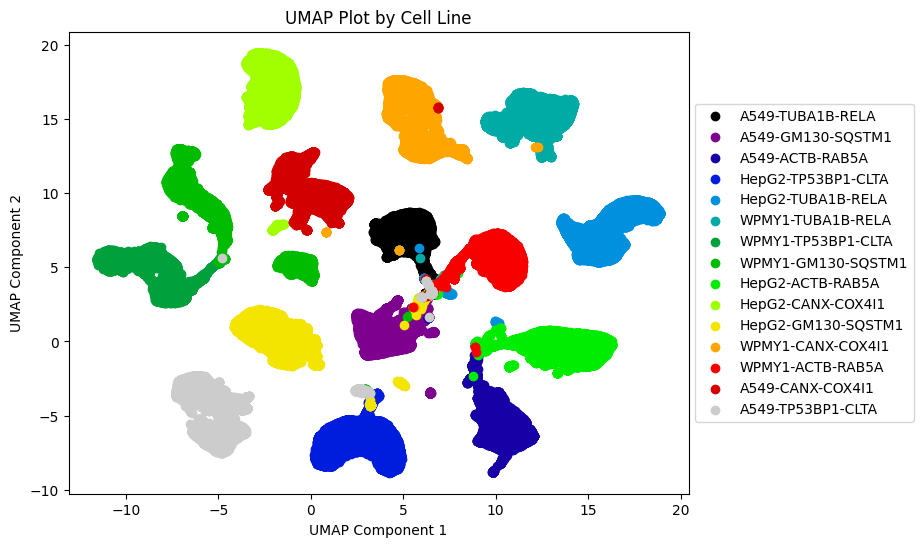

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_50

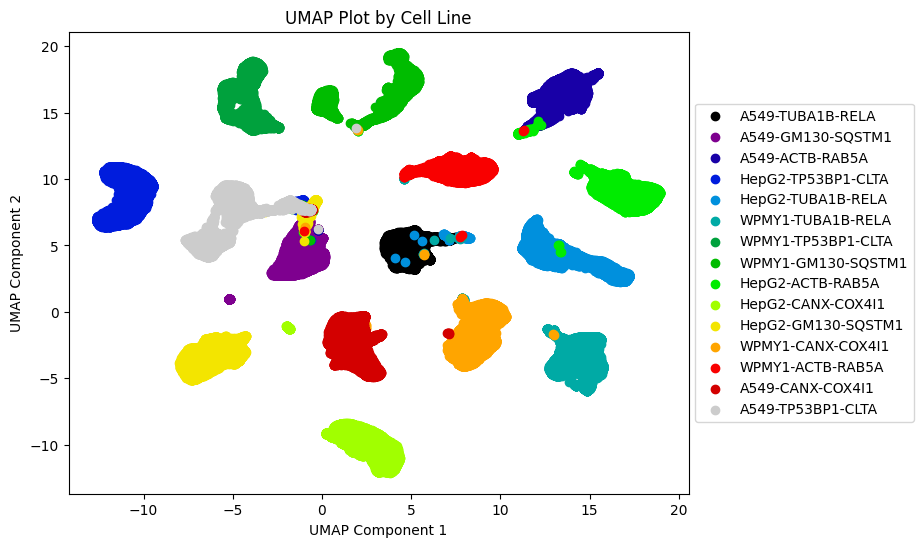

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Cell Line')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 15))
plt.gca().set_prop_cycle('color',colors)
for i in X['Comment [Cell Line with Markers]'].unique():
  plt.scatter(df[X['Comment [Cell Line with Markers]']==i,0], df[X['Comment [Cell Line with Markers]']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

### KNN

In [ ]:
x_df = pd.DataFrame(Xs)
x_df['cell_line'] = X['Comment [Cell Line with Markers]']
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

In [ ]:
X_train, X_test = train_test_split(X_pca[:,:2], test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9062155042899214, test score = 0.8939666852634096


In [ ]:
X_train, X_test = train_test_split(X_tsne_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9991033606044545, test score = 0.9987407348370129


In [ ]:
X_train, X_test = train_test_split(X_tsne, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9989479431092266, test score = 0.9987566749023671


In [ ]:
X_train, X_test = train_test_split(X_tsne_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9989240327253454, test score = 0.99869291464095


In [ ]:
X_train, X_test = train_test_split(X_umap_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9989598983011673, test score = 0.9986769745755958


In [ ]:
X_train, X_test = train_test_split(X_umap_30, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9988443314457414, test score = 0.9985016338566988


In [ ]:
X_train, X_test = train_test_split(X_umap_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9985135711353845, test score = 0.9981350123535506


In [ ]:
x_df = pd.DataFrame(X_samp)
x_df['cell_line'] = X_samp['Comment [Cell Line with Markers]']
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

In [ ]:
X_train, X_test = train_test_split(hermite_df, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.5298, test score = 0.4404


### Autoencoder

In [ ]:
X_train, X_test = train_test_split(Xs, test_size=0.2, random_state=42)

In [ ]:
class Autoencoder(Model):
  def __init__(self, latent_dim, shape):
    super(Autoencoder, self).__init__()
    self.latent_dim = latent_dim
    self.shape = shape
    self.encoder = tf.keras.Sequential([
      layers.Dense(500, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(200, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(latent_dim, activation='tanh'),
    ])
    self.decoder = tf.keras.Sequential([
      layers.Dense(500, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(200, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(tf.math.reduce_prod(shape).numpy(), activation='sigmoid'),
      layers.Reshape(shape)
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded


shape = X_test.shape[1:]
latent_dim = 2
autoencoder = Autoencoder(latent_dim, shape)

In [ ]:
class Autoencoder(Model):
  def __init__(self, latent_dim, shape):
    super(Autoencoder, self).__init__()
    self.latent_dim = latent_dim
    self.shape = shape
    self.encoder = tf.keras.Sequential([
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(latent_dim, activation='tanh'),
    ])
    self.decoder = tf.keras.Sequential([
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(tf.math.reduce_prod(shape).numpy(), activation='sigmoid'),
      layers.Reshape(shape)
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded


shape = X_test.shape[1:]
latent_dim = 2
autoencoder = Autoencoder(latent_dim, shape)

In [ ]:
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

In [ ]:
autoencoder.fit(X_train, X_train,
                epochs=5,
                shuffle=True,
                validation_data=(X_test, X_test))

Epoch 1/5
7842/7842 [==============================] - 72s 9ms/step - loss: 0.6996 - val_loss: 0.6557
Epoch 2/5
7842/7842 [==============================] - 69s 9ms/step - loss: 0.6526 - val_loss: 0.6373
Epoch 3/5
7842/7842 [==============================] - 68s 9ms/step - loss: 0.6421 - val_loss: 0.6270
Epoch 4/5
7842/7842 [==============================] - 69s 9ms/step - loss: 0.6314 - val_loss: 0.6165
Epoch 5/5
7842/7842 [==============================] - 68s 9ms/step - loss: 0.6241 - val_loss: 0.6096


In [ ]:
encoded_imgs = autoencoder.encoder(X_test).numpy()

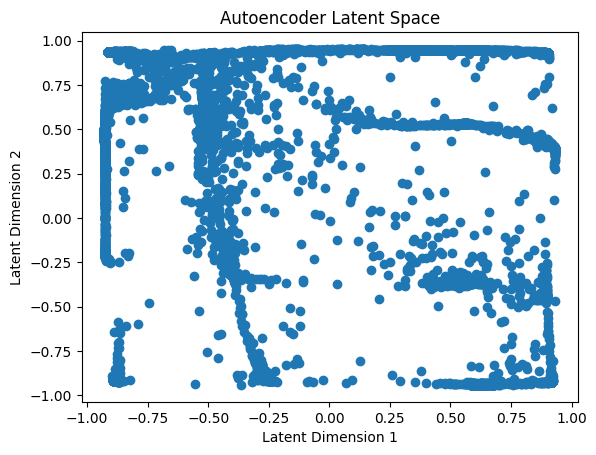

In [ ]:
plt.scatter(encoded_imgs[:, 0], encoded_imgs[:, 1])
plt.title('Autoencoder Latent Space')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

### Cell Line A549-ACTB-RAB5A

In [ ]:
df_A549 = X[X['Comment [Cell Line with Markers]']=='A549-ACTB-RAB5A']

In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(df_A549[df_A549.columns[4:979]])

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50 = umap.fit_transform(Xs)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
tsne = TSNE(n_components=2, random_state=42, metric = "correlation")
X_tsne = tsne.fit_transform(Xs)

In [ ]:
X_tsne = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_tsne_correlation.csv')

In [ ]:
X_tsne = X_tsne.drop('Unnamed: 0', axis = 1).values

In [ ]:
df = X_tsne

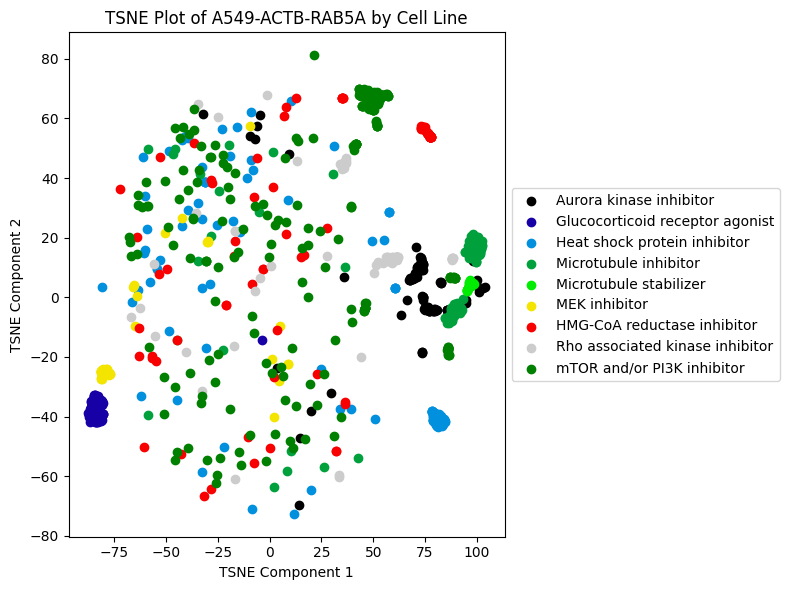

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot of A549-ACTB-RAB5A by Cell Line')

moa_list = [
    'Aurora kinase inhibitor',
    'Glucocorticoid receptor agonist',
    'Heat shock protein inhibitor',
    'Microtubule inhibitor',
    'Microtubule stabilizer',
    'MEK inhibitor',
    'HMG-CoA reductase inhibitor',
    'Rho associated kinase inhibitor'
]

colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, len(moa_list)))
plt.gca().set_prop_cycle('color', colors)

# Plot each MoA separately
for moa in moa_list:
    mask = (df_A549['Compound MoA'] == moa).values
    plt.scatter(df[mask, 0], df[mask, 1], label=moa)

# Plot mTOR and/or PI3K inhibitors once
mtor_mask = df_A549['Compound MoA'].str.contains('mTOR|PI3K', regex=True, na=False).values
plt.scatter(df[mtor_mask, 0], df[mtor_mask, 1],
            label='mTOR and/or PI3K inhibitor', color='green')

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.tight_layout()
plt.show()

In [ ]:
df_A549.loc[:,'Compound MoA'] = df_A549['Compound MoA'].fillna('DMSO')
y_train, y_test = train_test_split(df_A549['Compound MoA'], test_size=0.2, random_state=42)

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
k=50
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.31263831568873734, test score = 0.3066985645933014


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


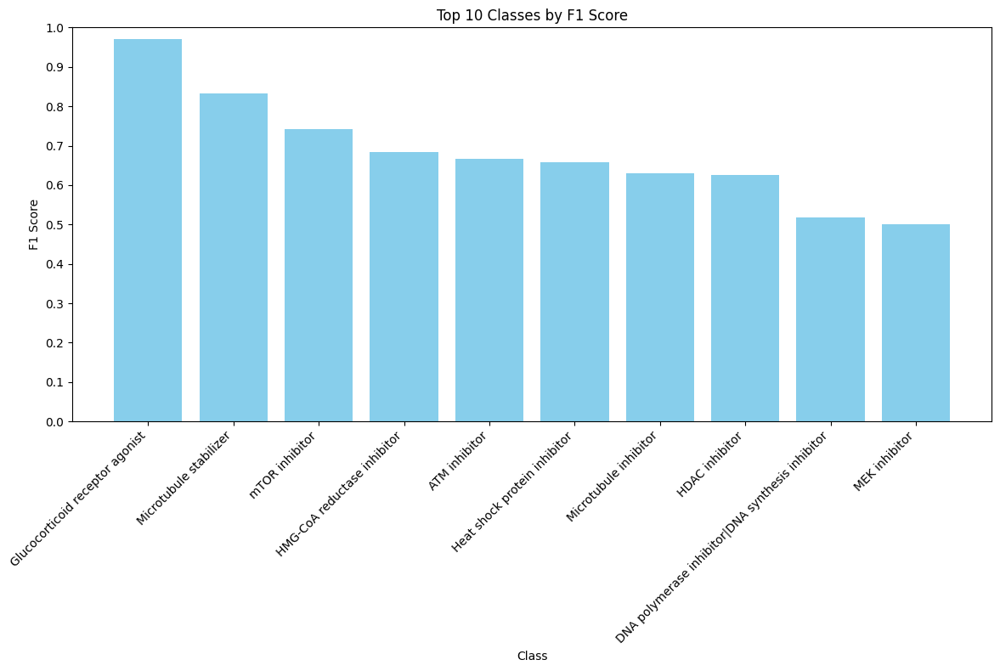

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(df_A549['Compound MoA']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(df_A549['Compound MoA'])[i]: f1_scores[i] for i in range(len(np.unique(df_A549['Compound MoA'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
df = X_pca

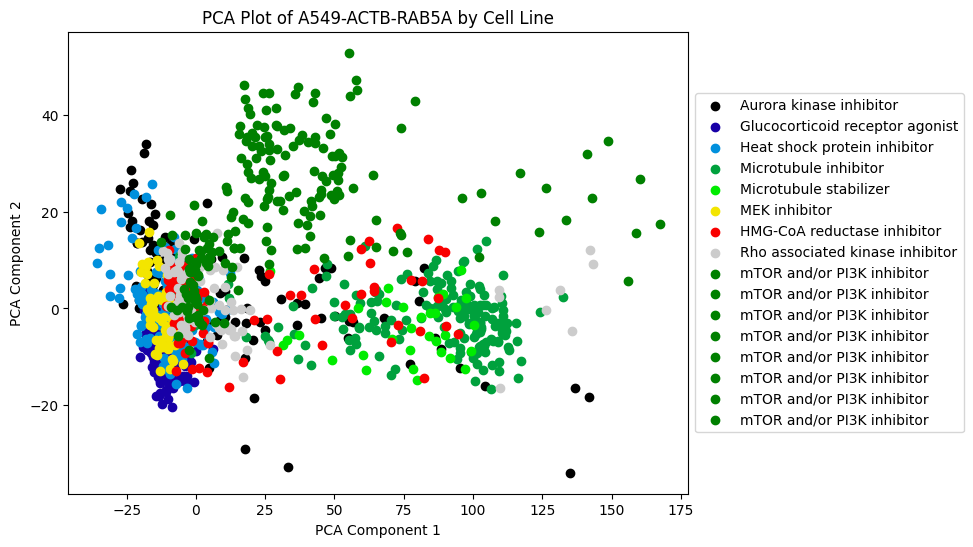

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot of A549-ACTB-RAB5A by Cell Line')
moa_list = ['Aurora kinase inhibitor', 'Glucocorticoid receptor agonist', 'Heat shock protein inhibitor',
         'Microtubule inhibitor', 'Microtubule stabilizer', 'MEK inhibitor', 'HMG-CoA reductase inhibitor',
        'Rho associated kinase inhibitor']
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 8))
plt.gca().set_prop_cycle('color',colors)
for i in moa_list:
  plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = i)
for i in df_A549.dropna(subset = ['Compound MoA'])[df_A549['Compound MoA'].str.contains('mTOR').dropna()]['Compound MoA'].unique():
  plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = 'mTOR and/or PI3K inhibitor', color = 'green')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [ ]:
df_A549.loc[:,'Compound MoA'] = df_A549['Compound MoA'].fillna('DMSO')
y_train, y_test = train_test_split(df_A549['Compound MoA'], test_size=0.2, random_state=42)

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
k=50
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.26006340092110775, test score = 0.25813397129186605


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


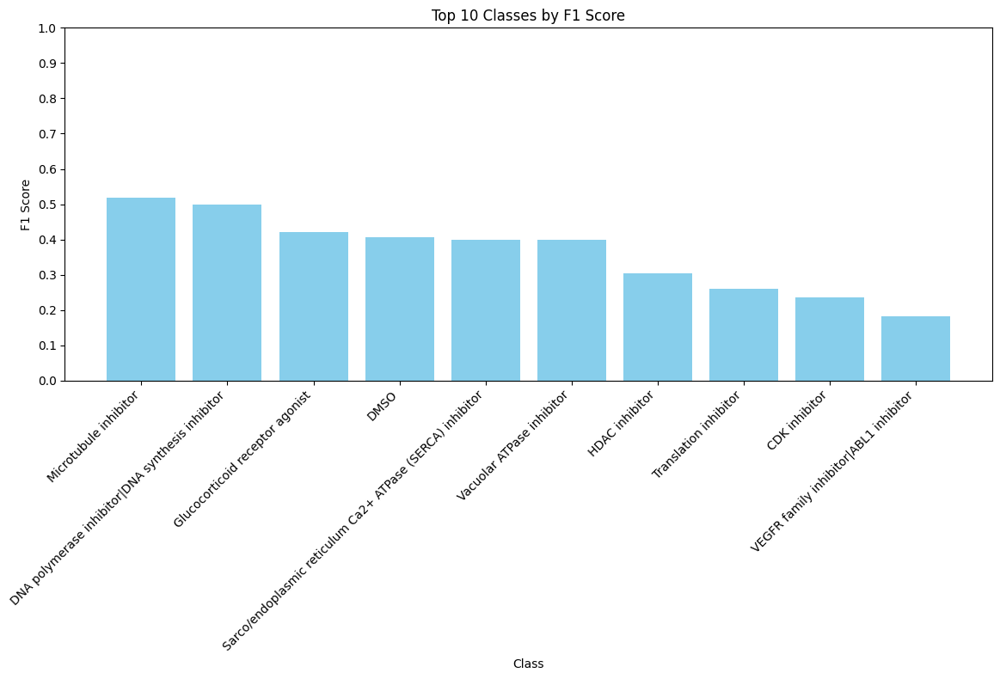

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(df_A549['Compound MoA']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(df_A549['Compound MoA'])[i]: f1_scores[i] for i in range(len(np.unique(df_A549['Compound MoA'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
df = X_umap_50

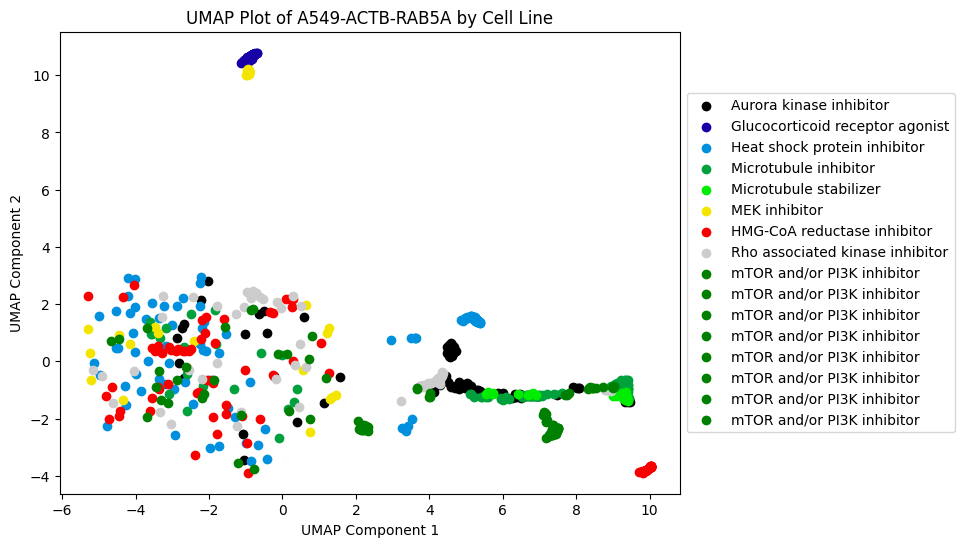

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot of A549-ACTB-RAB5A by Cell Line')
moa_list = ['Aurora kinase inhibitor', 'Glucocorticoid receptor agonist', 'Heat shock protein inhibitor',
         'Microtubule inhibitor', 'Microtubule stabilizer', 'MEK inhibitor', 'HMG-CoA reductase inhibitor',
        'Rho associated kinase inhibitor']
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 8))
plt.gca().set_prop_cycle('color',colors)
for i in moa_list:
  plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = i)
for i in df_A549.dropna(subset = ['Compound MoA'])[df_A549['Compound MoA'].str.contains('mTOR').dropna()]['Compound MoA'].unique():
  plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = 'mTOR and/or PI3K inhibitor', color = 'green')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df_A549.loc[:,'Compound MoA'] = df_A549['Compound MoA'].fillna('DMSO')
y_train, y_test = train_test_split(df_A549['Compound MoA'], test_size=0.2, random_state=42)

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
k=50
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.3016926849691967, test score = 0.29617224880382775


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


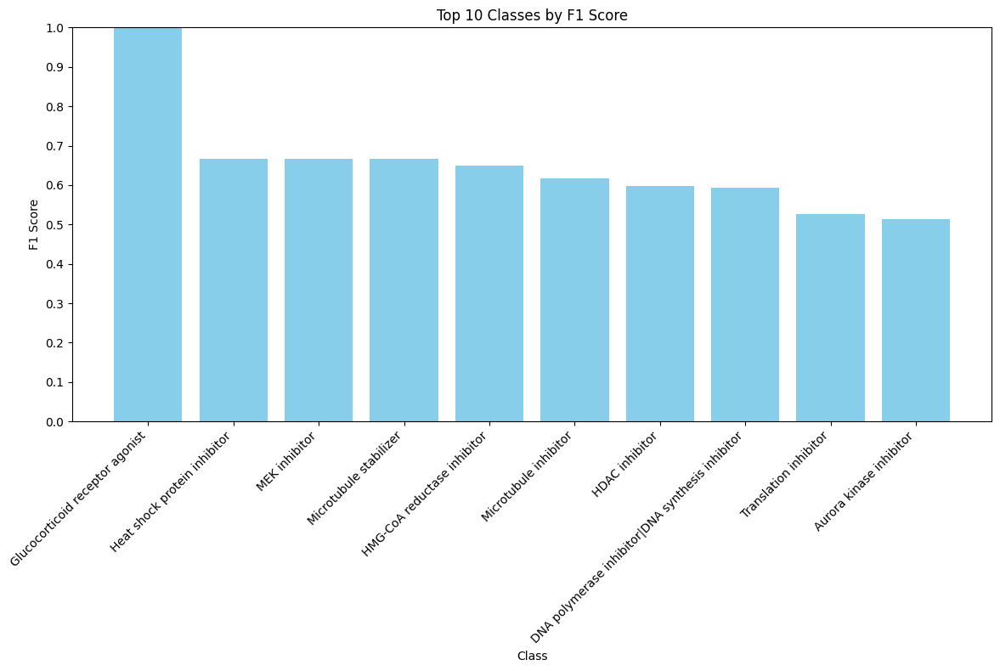

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(df_A549['Compound MoA']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(df_A549['Compound MoA'])[i]: f1_scores[i] for i in range(len(np.unique(df_A549['Compound MoA'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

### Projection Pursuit again

In [ ]:
df_A549.to_csv('/content/drive/MyDrive/smallmoleculedata/df_A549.csv')

In [ ]:
X_sample = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/X_sample_A549.csv')

In [ ]:
X_samp = pd.read_csv('/content/drive/MyDrive/smallmoleculedata/df_A549.csv')

In [ ]:
X_samp['Projection 1.2'] = X_sample['Projection 1.2']
X_samp['Projection 2.2'] = X_sample['Projection 2.2']
X_samp['Projection 1.1'] = X_sample['Projection 1.1']
X_samp['Projection 2.1'] = X_sample['Projection 2.1']
X_samp['Projection 1'] = X_sample['Projection 1']
X_samp['Projection 2'] = X_sample['Projection 2']

In [ ]:
df = X_samp[['Projection 1','Projection 2']]

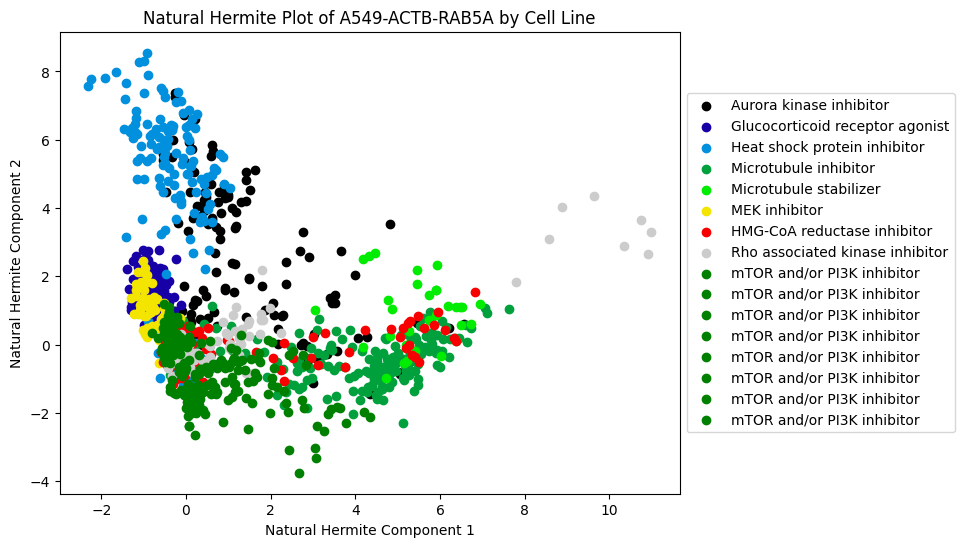

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Natural Hermite Plot of A549-ACTB-RAB5A by Cell Line')
moa_list = ['Aurora kinase inhibitor', 'Glucocorticoid receptor agonist', 'Heat shock protein inhibitor',
         'Microtubule inhibitor', 'Microtubule stabilizer', 'MEK inhibitor', 'HMG-CoA reductase inhibitor',
        'Rho associated kinase inhibitor']
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 8))
plt.gca().set_prop_cycle('color',colors)
for i in moa_list:
  plt.scatter(X_samp[X_samp['Compound MoA']==i]['Projection 1'], X_samp[X_samp['Compound MoA']==i]['Projection 2'], label = i)
for i in df_A549.dropna(subset = ['Compound MoA'])[df_A549['Compound MoA'].str.contains('mTOR').dropna()]['Compound MoA'].unique():
  plt.scatter(X_samp[X_samp['Compound MoA']==i]['Projection 1'], X_samp[X_samp['Compound MoA']==i]['Projection 2'], label = 'mTOR and/or PI3K inhibitor', color = 'green')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Natural Hermite Component 1')
plt.ylabel('Natural Hermite Component 2')
plt.show()

In [ ]:
df_A549.loc[:,'Compound MoA'] = df_A549['Compound MoA'].fillna('DMSO')
y_train, y_test = train_test_split(df_A549['Compound MoA'], test_size=0.2, random_state=42)

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
k=50
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.2636521323045637, test score = 0.26004784688995214


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


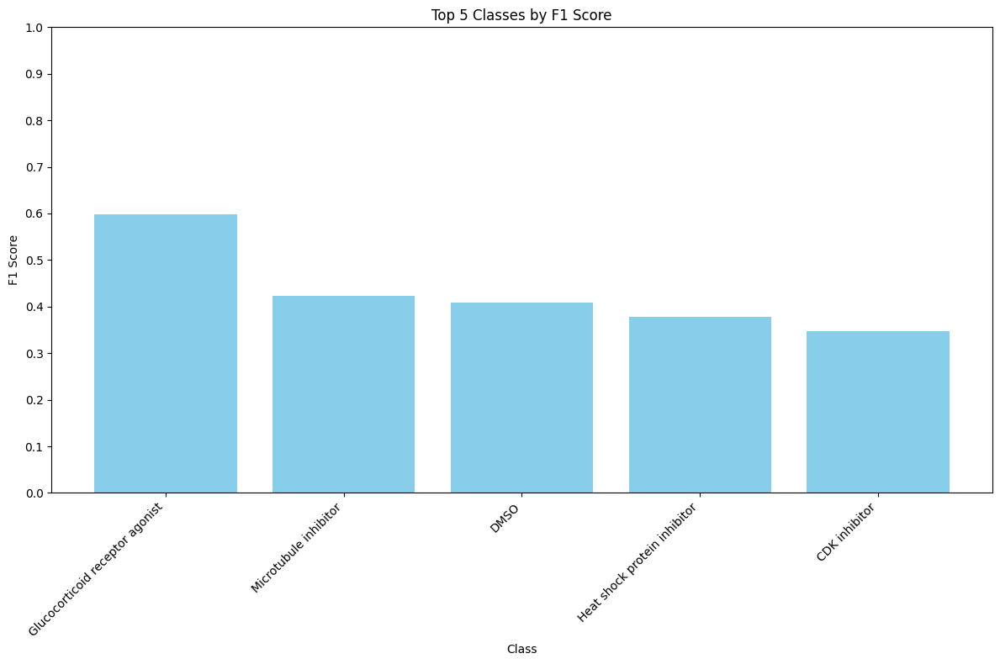

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(df_A549['Compound MoA']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(df_A549['Compound MoA'])[i]: f1_scores[i] for i in range(len(np.unique(df_A549['Compound MoA'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:5]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 5 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

### Plots again

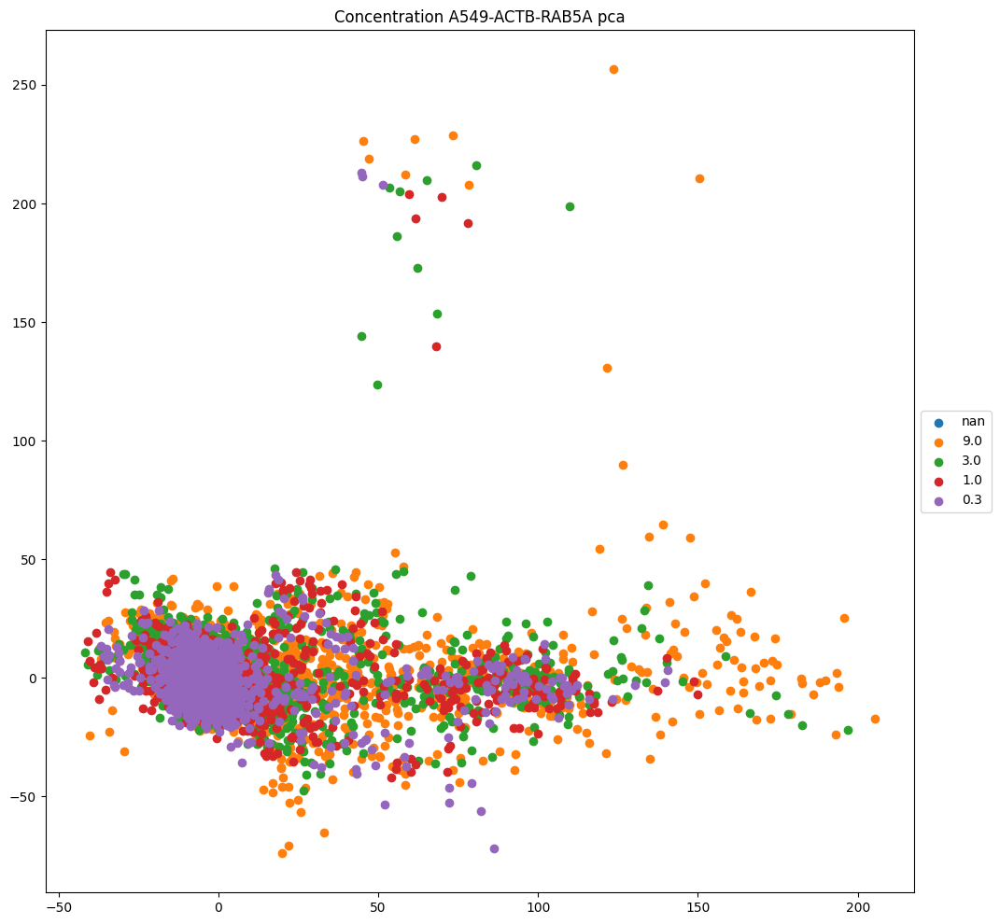

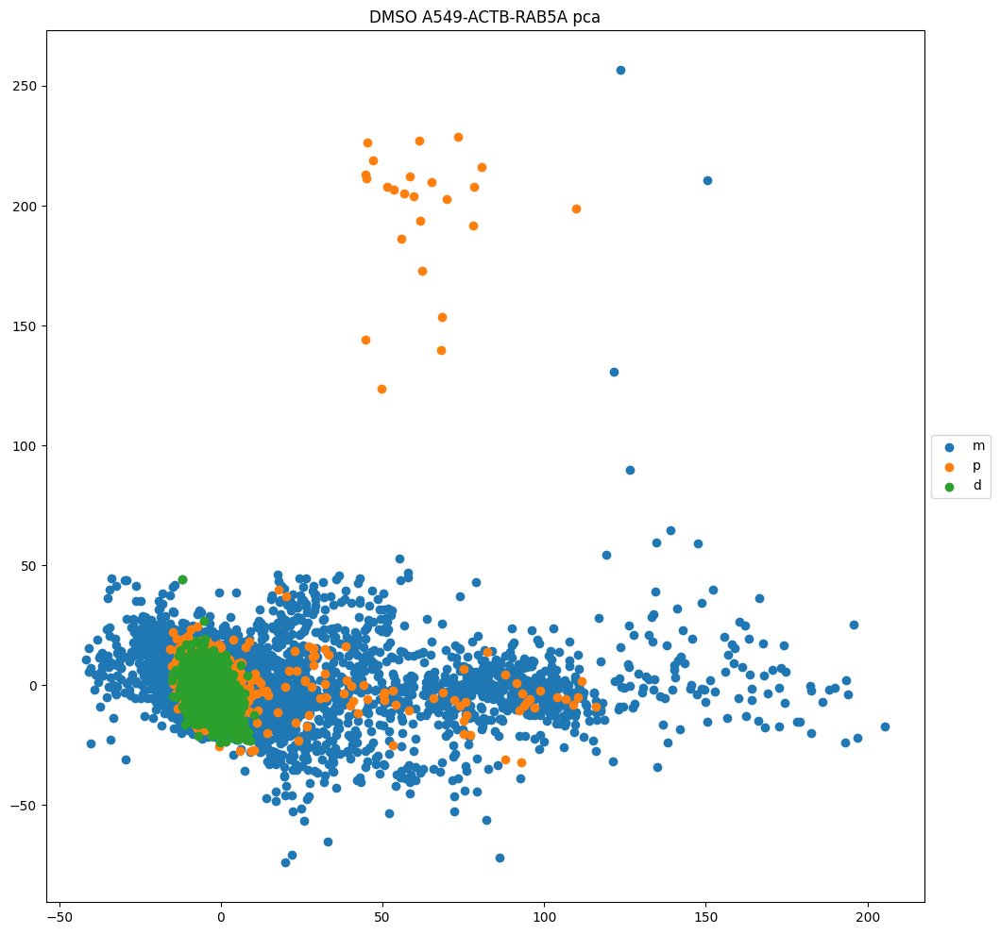

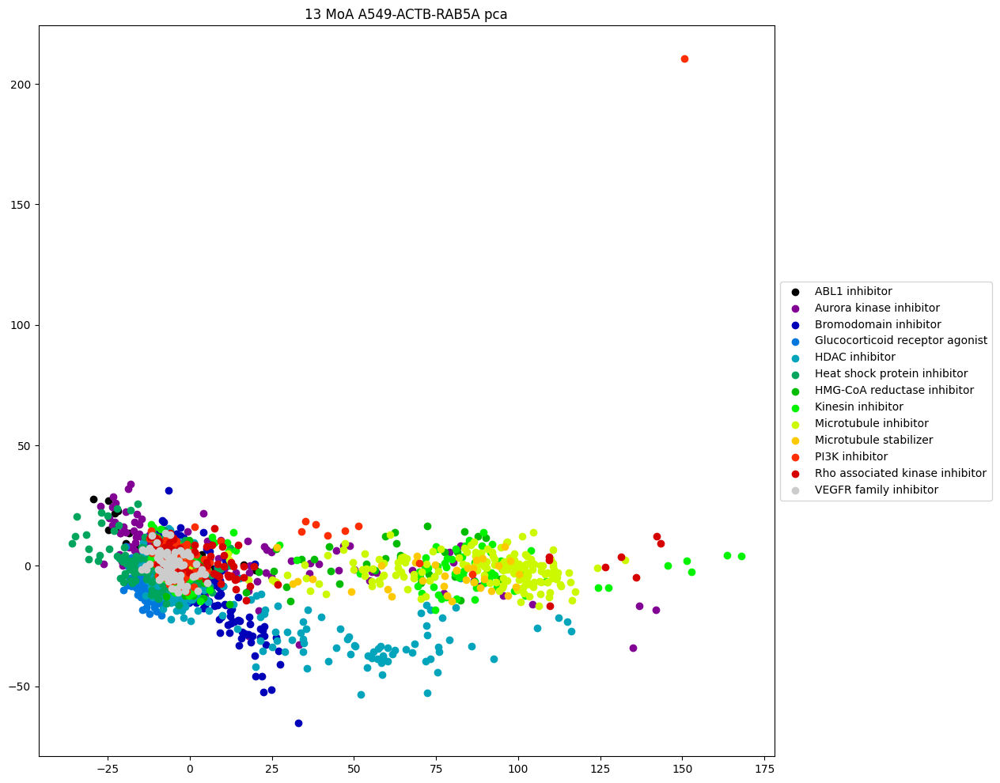

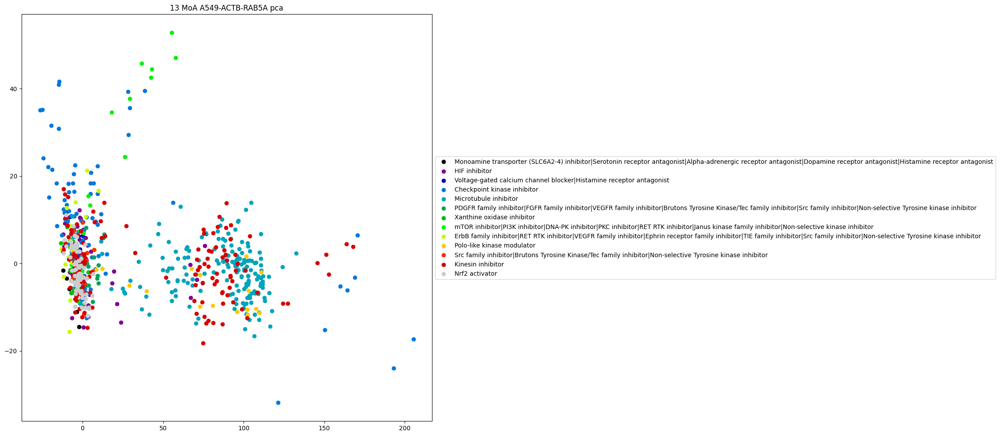

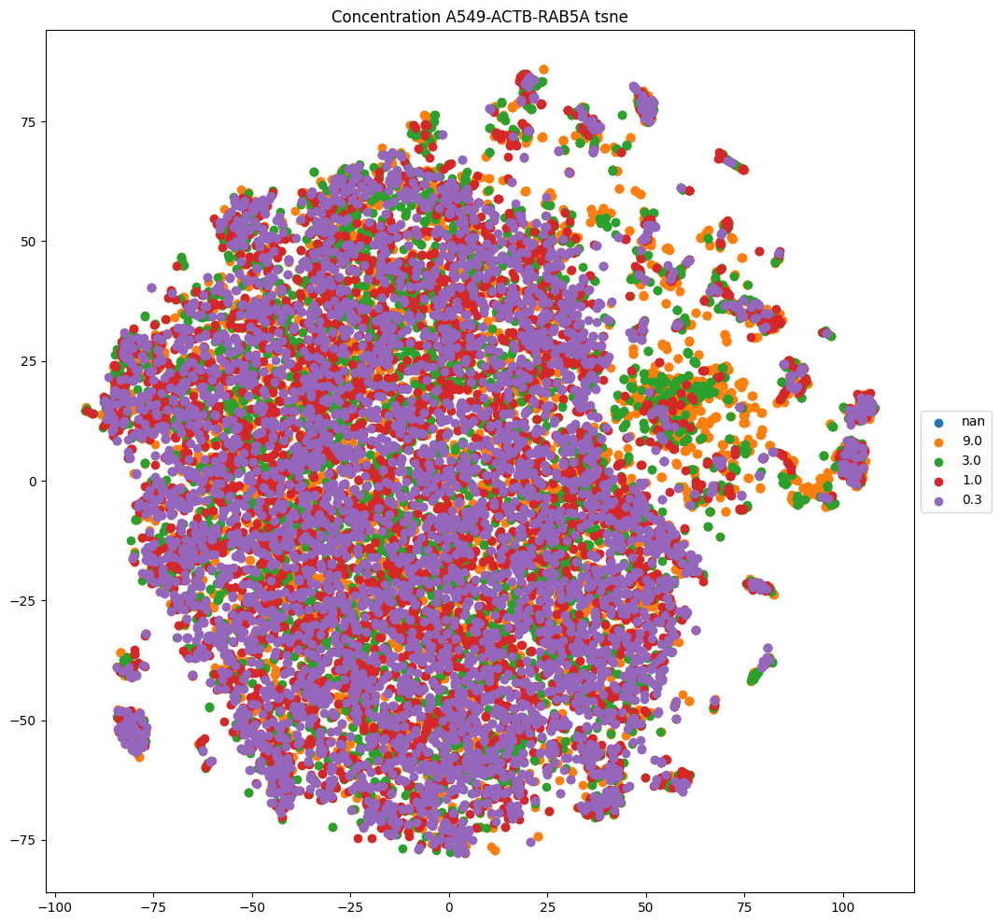

...

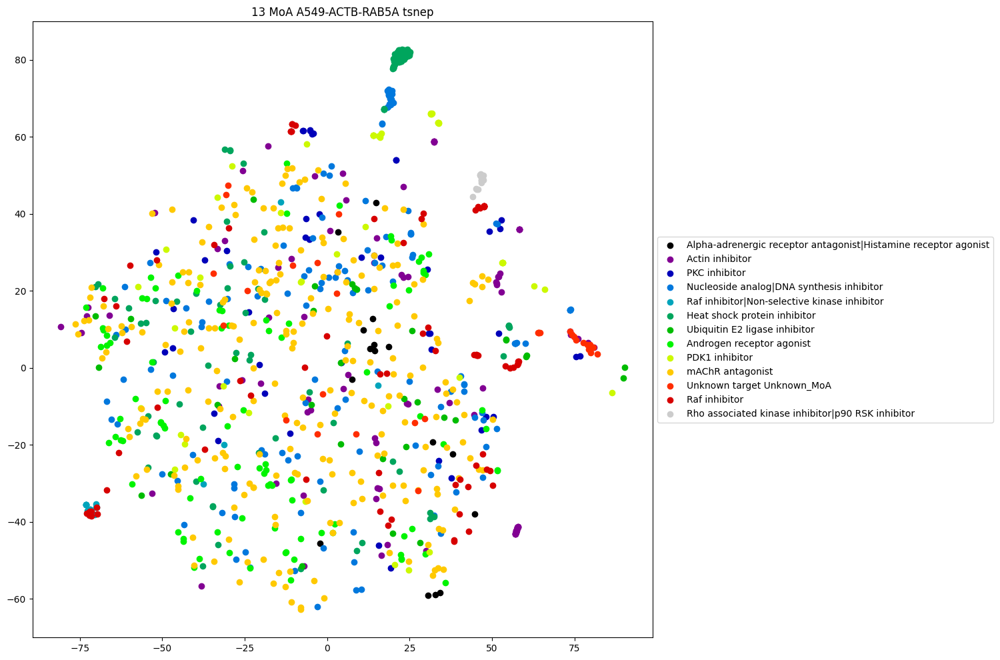

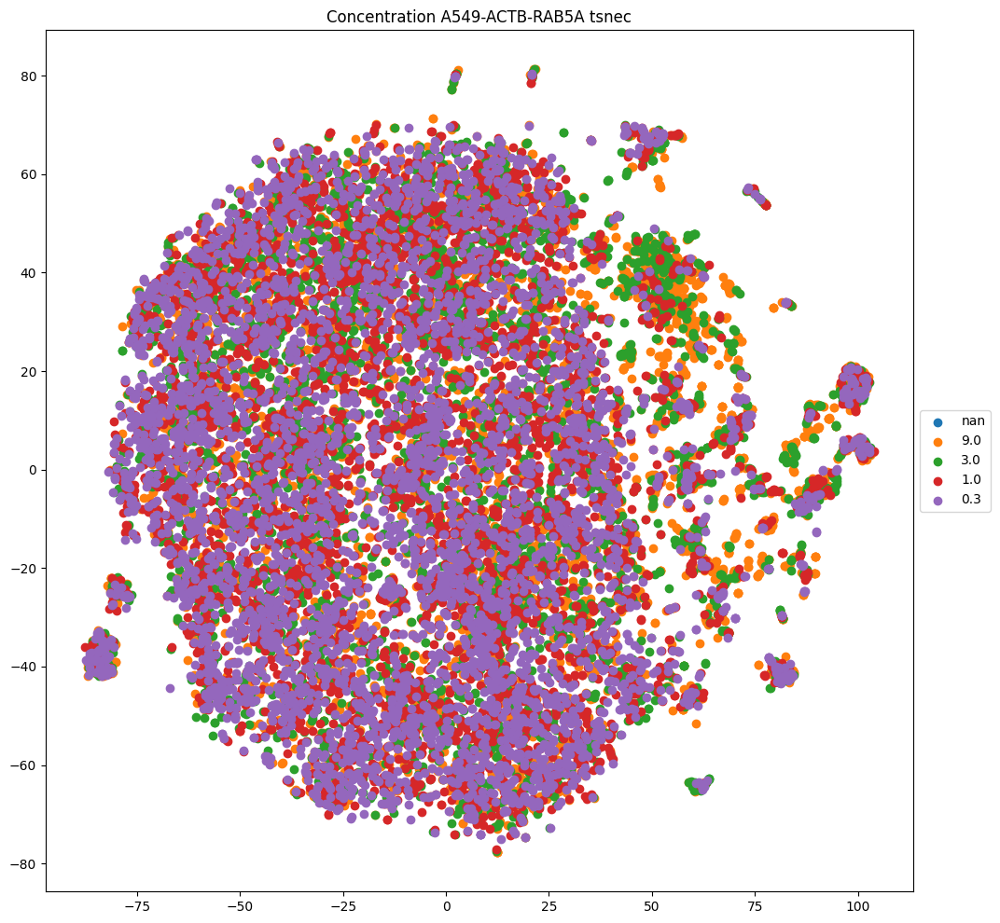

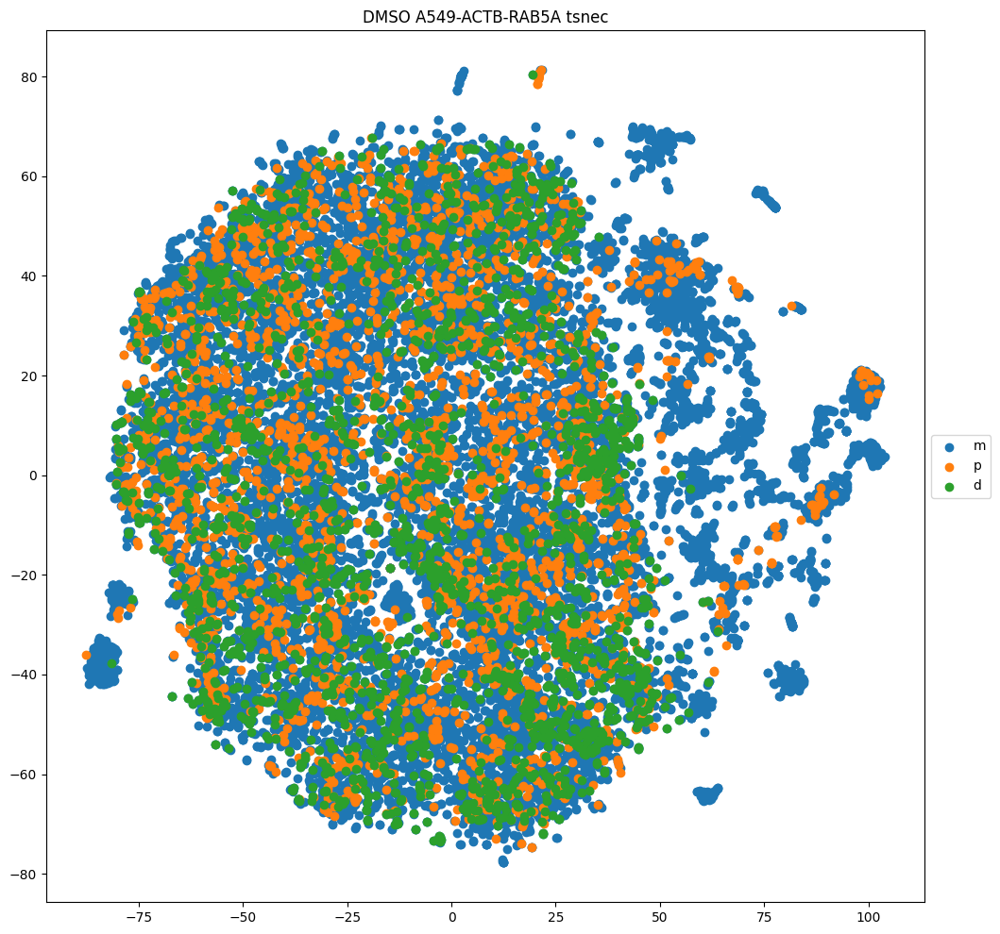

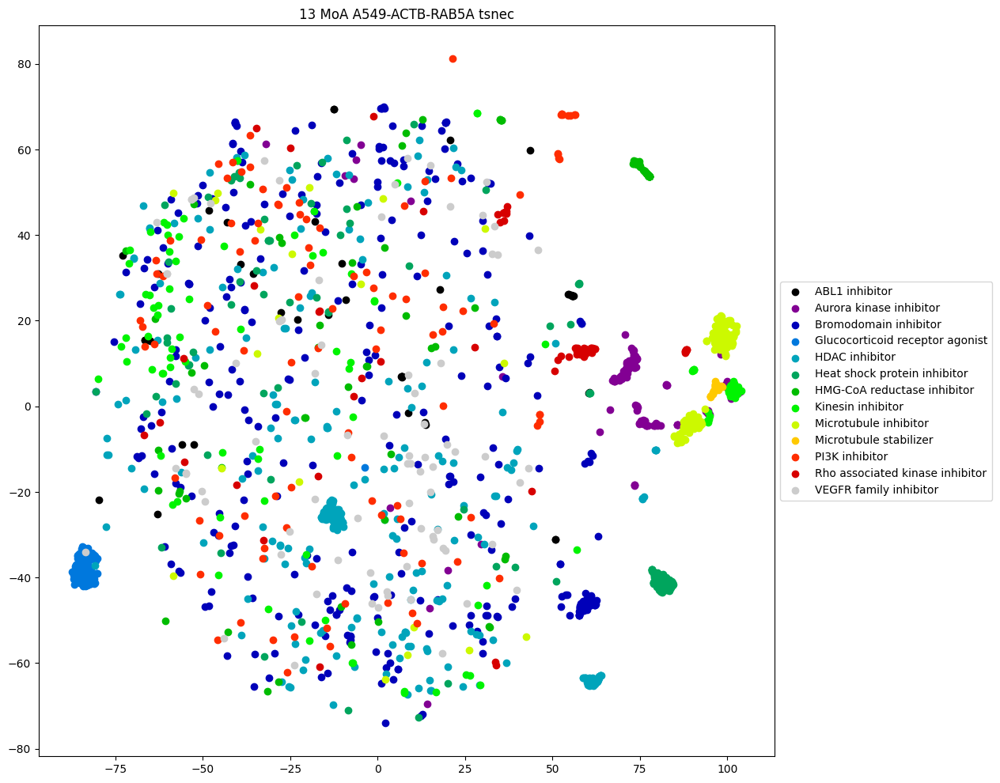

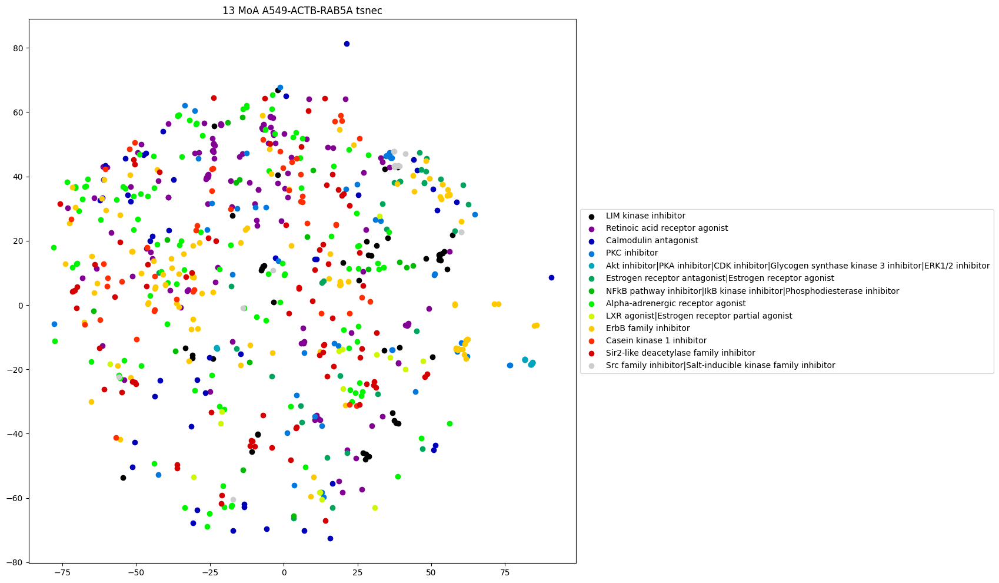

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


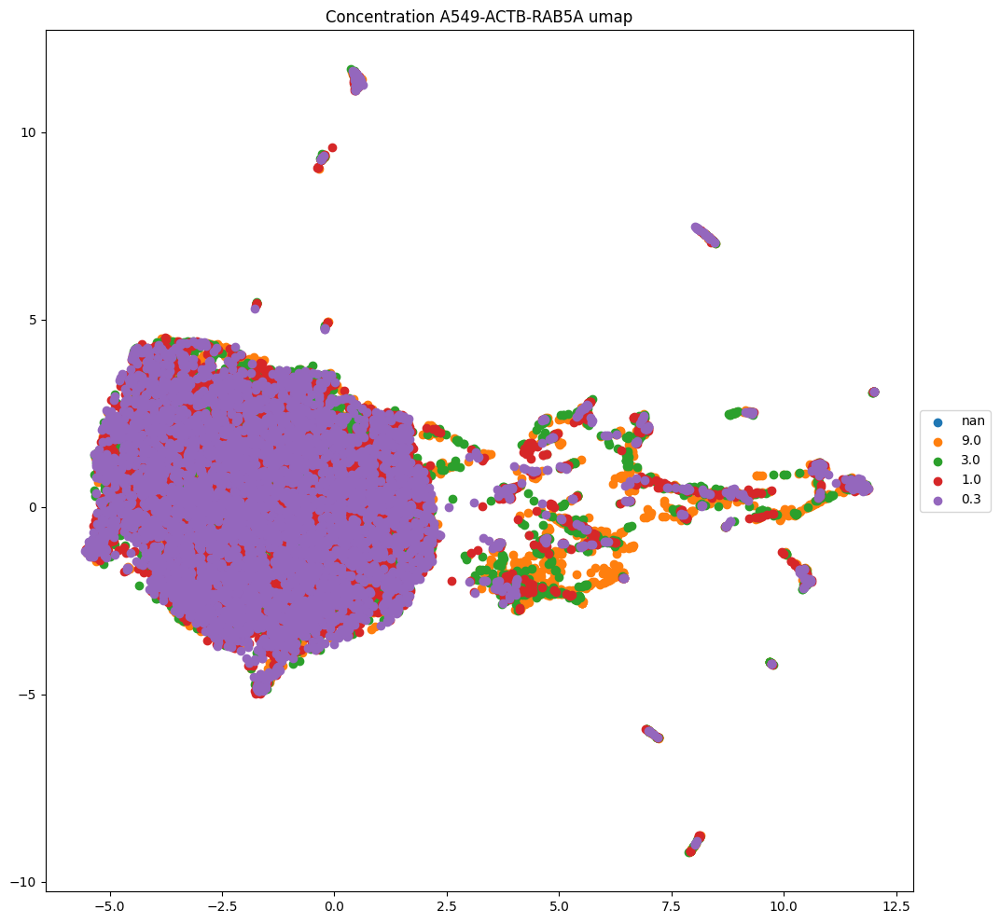

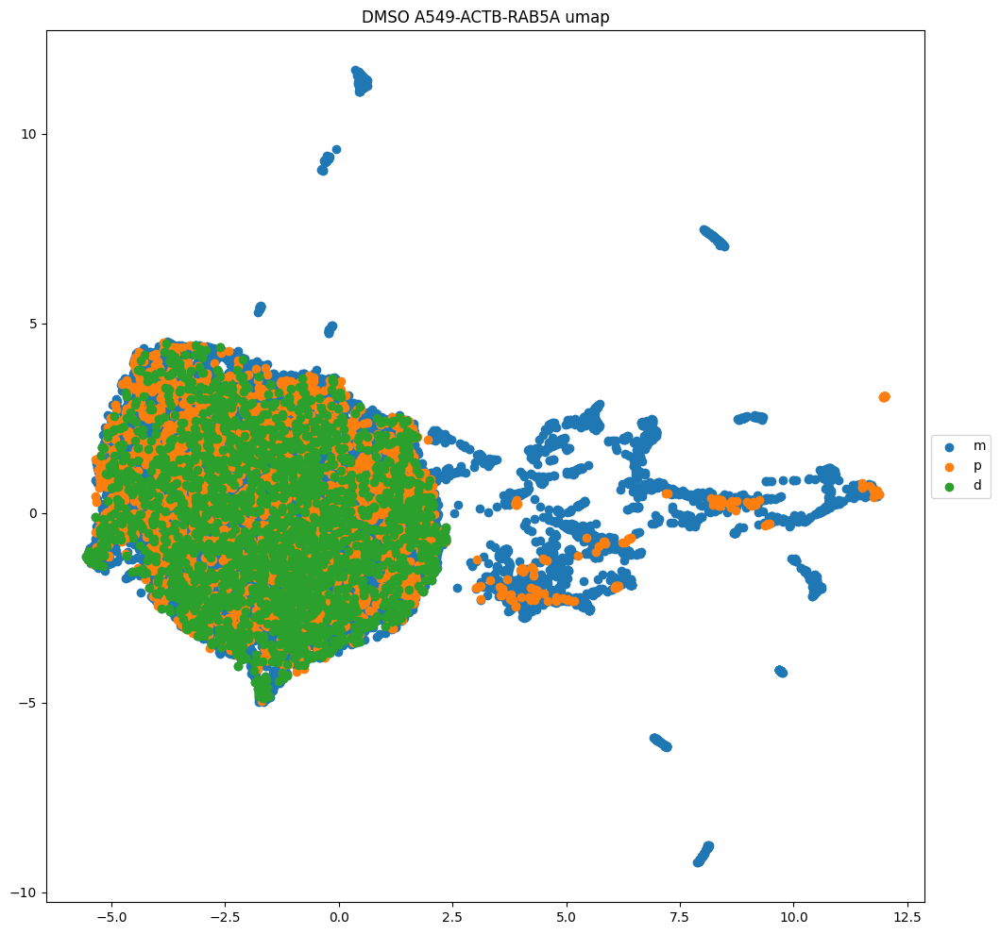

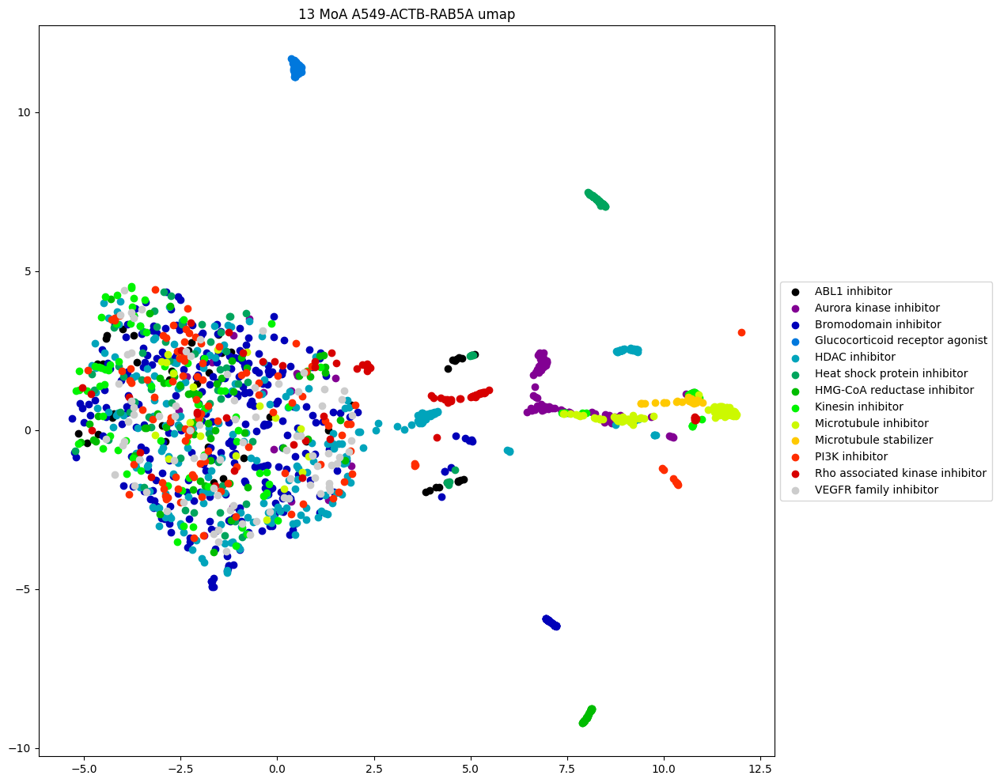

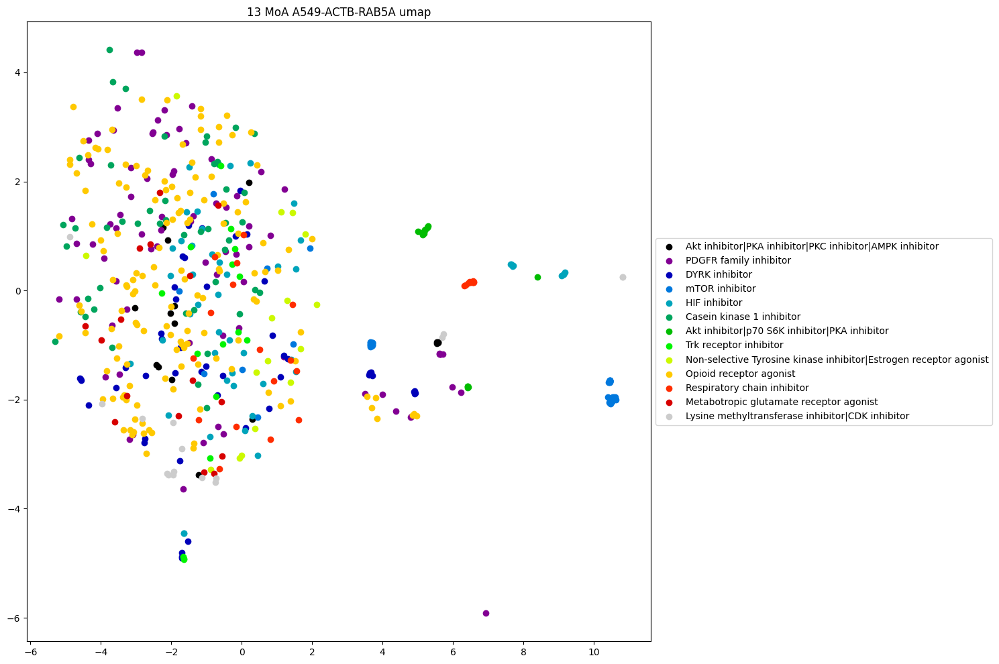

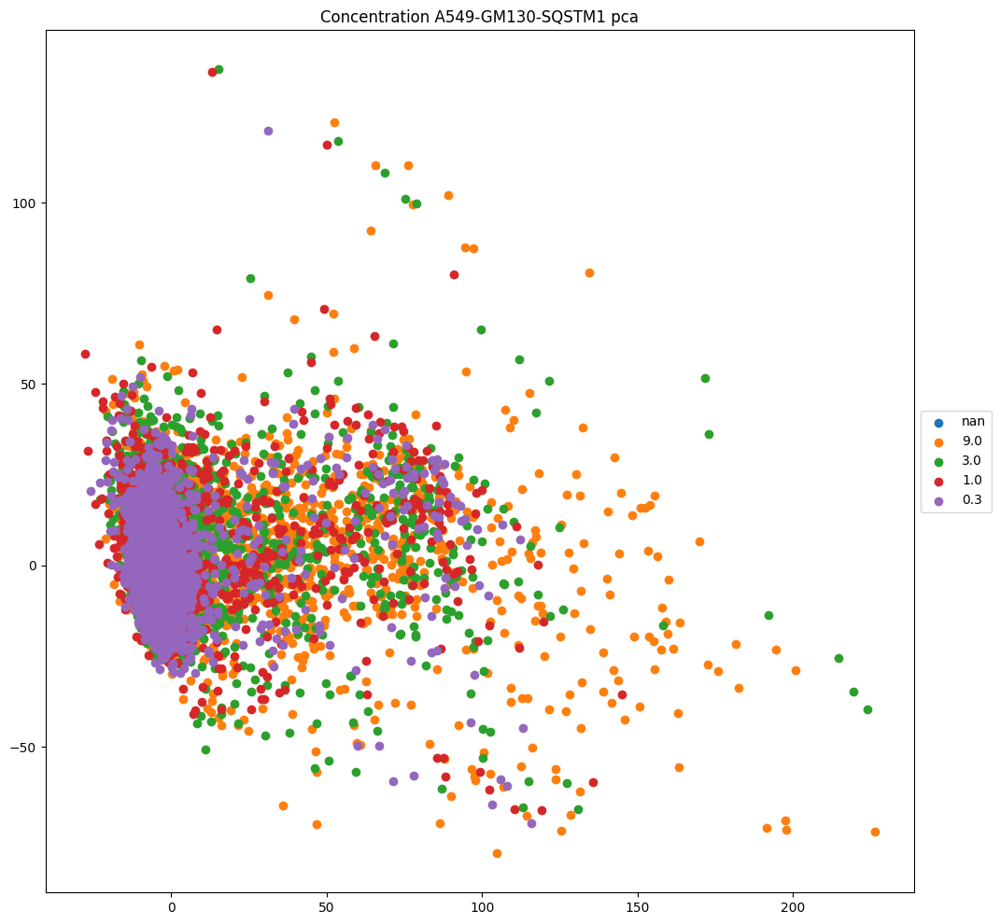

...

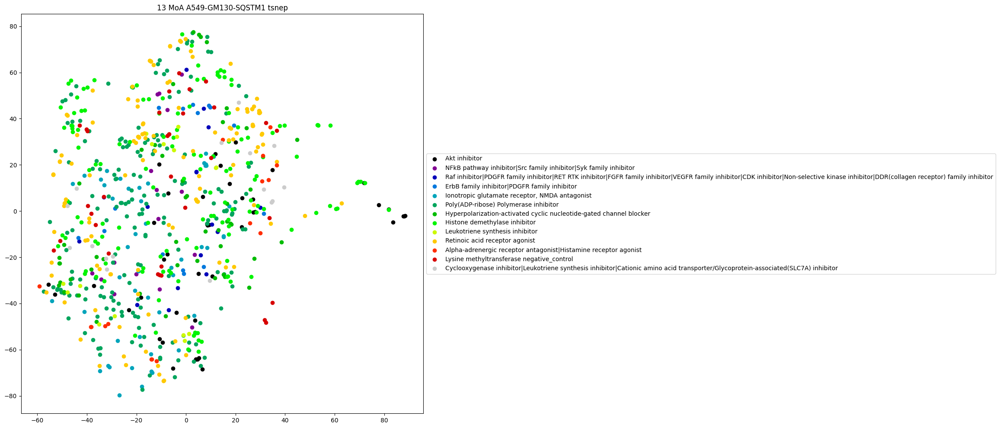

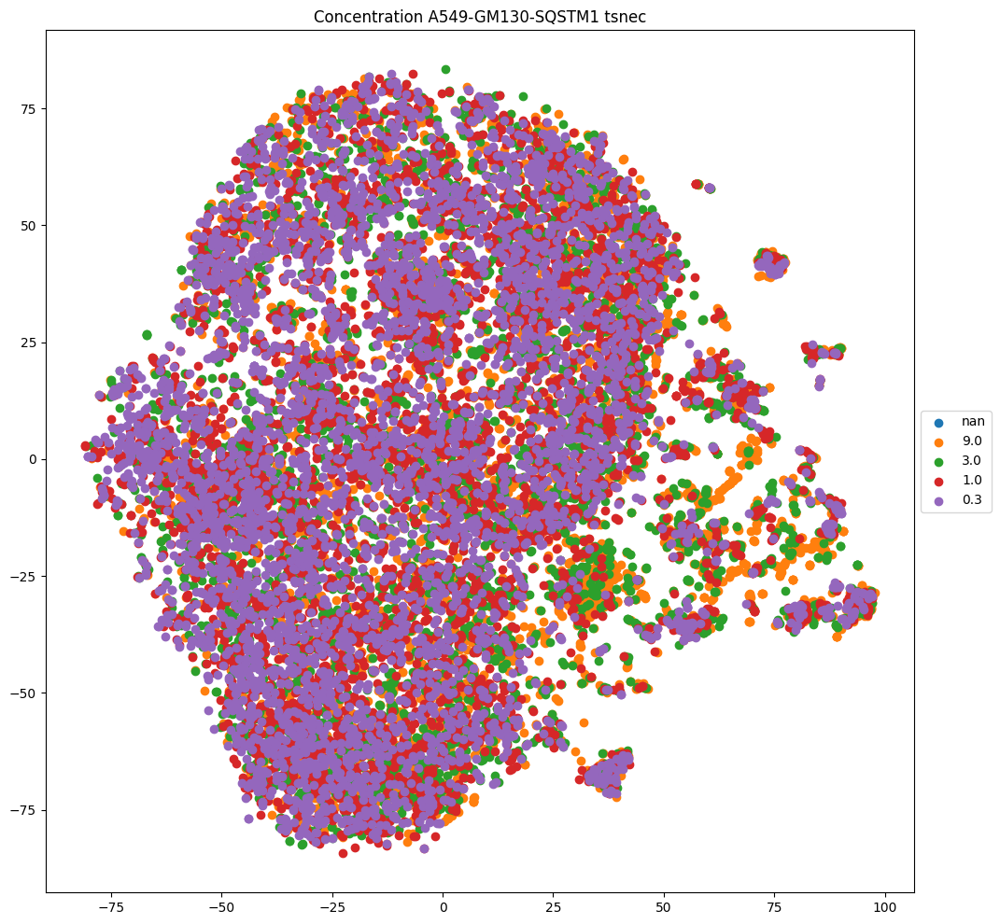

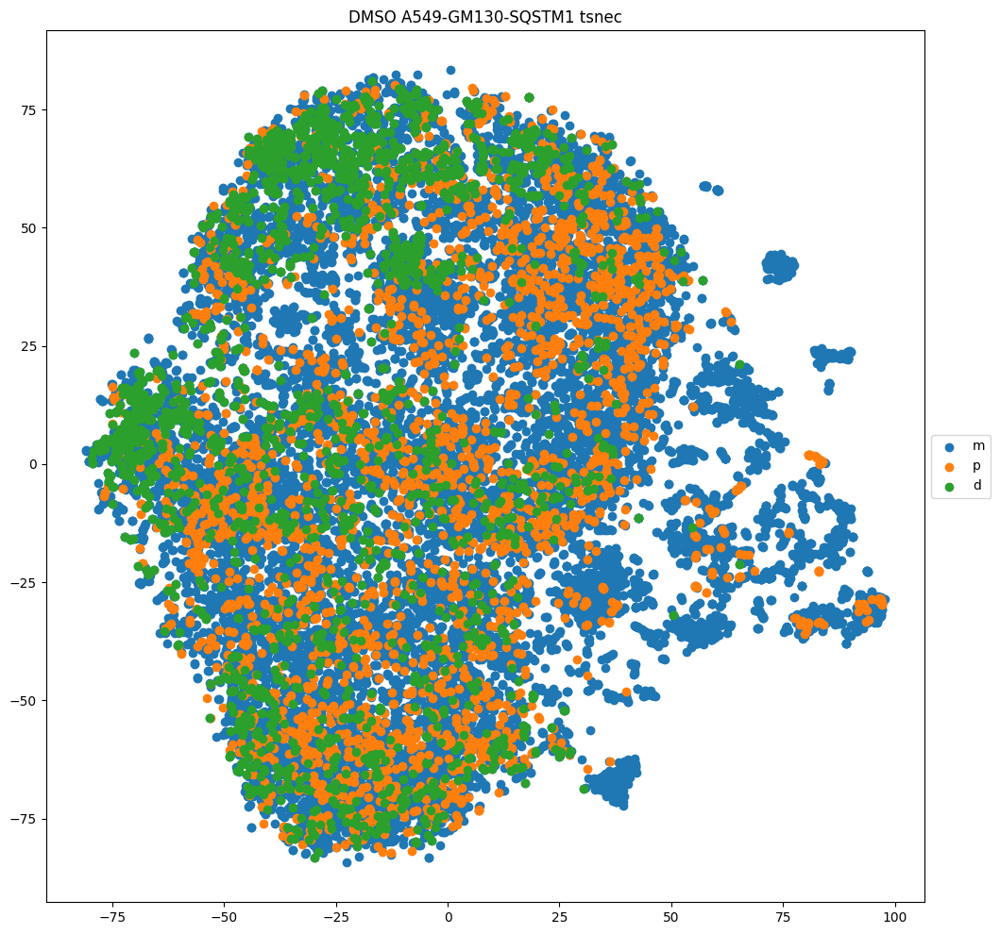

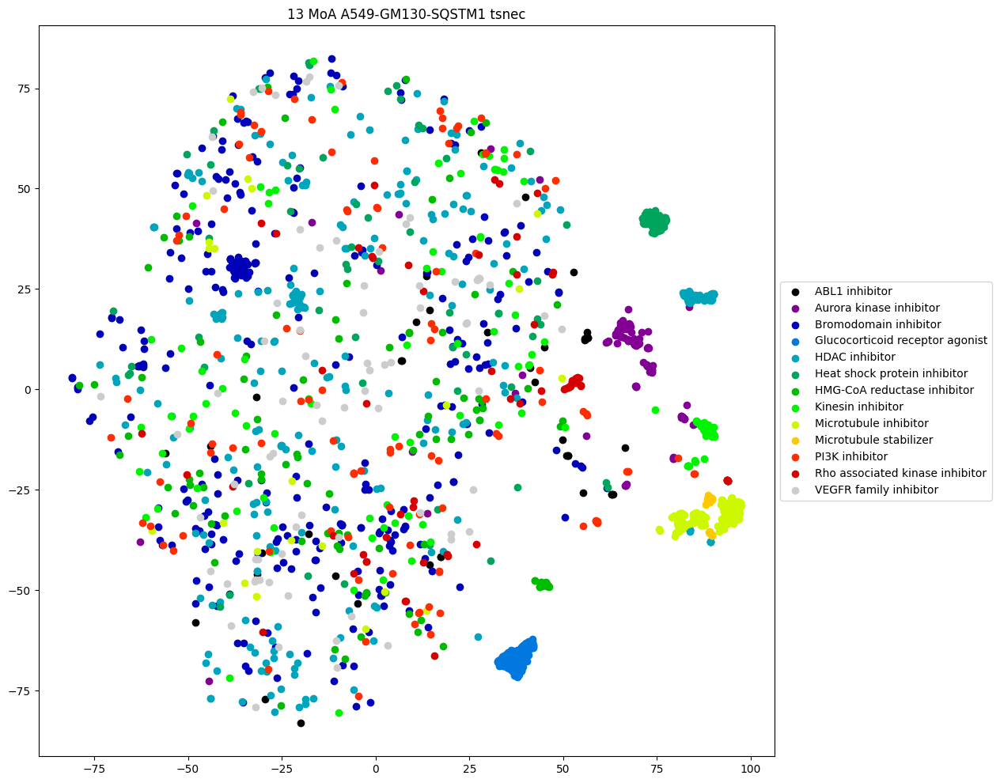

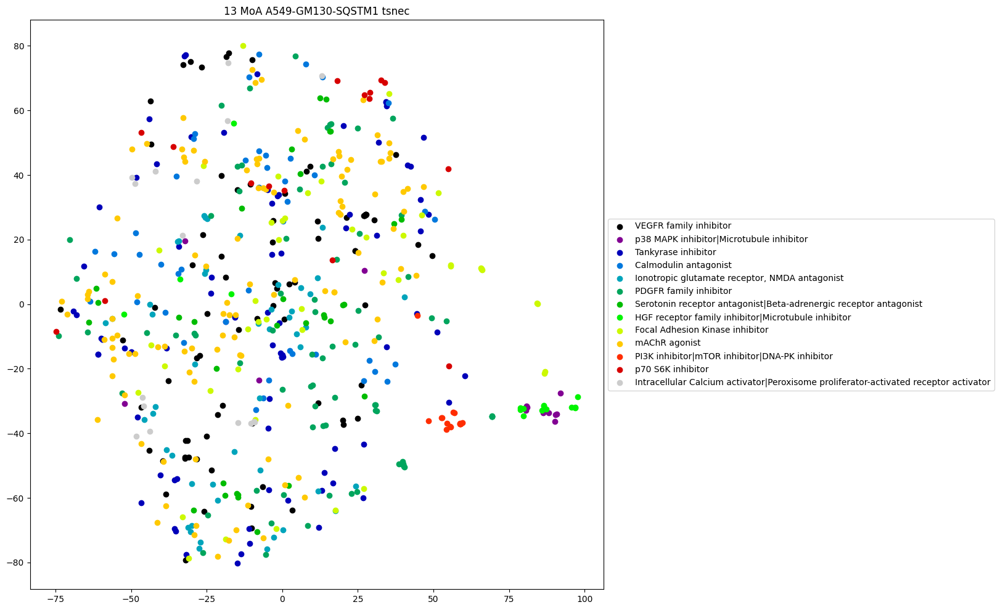

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


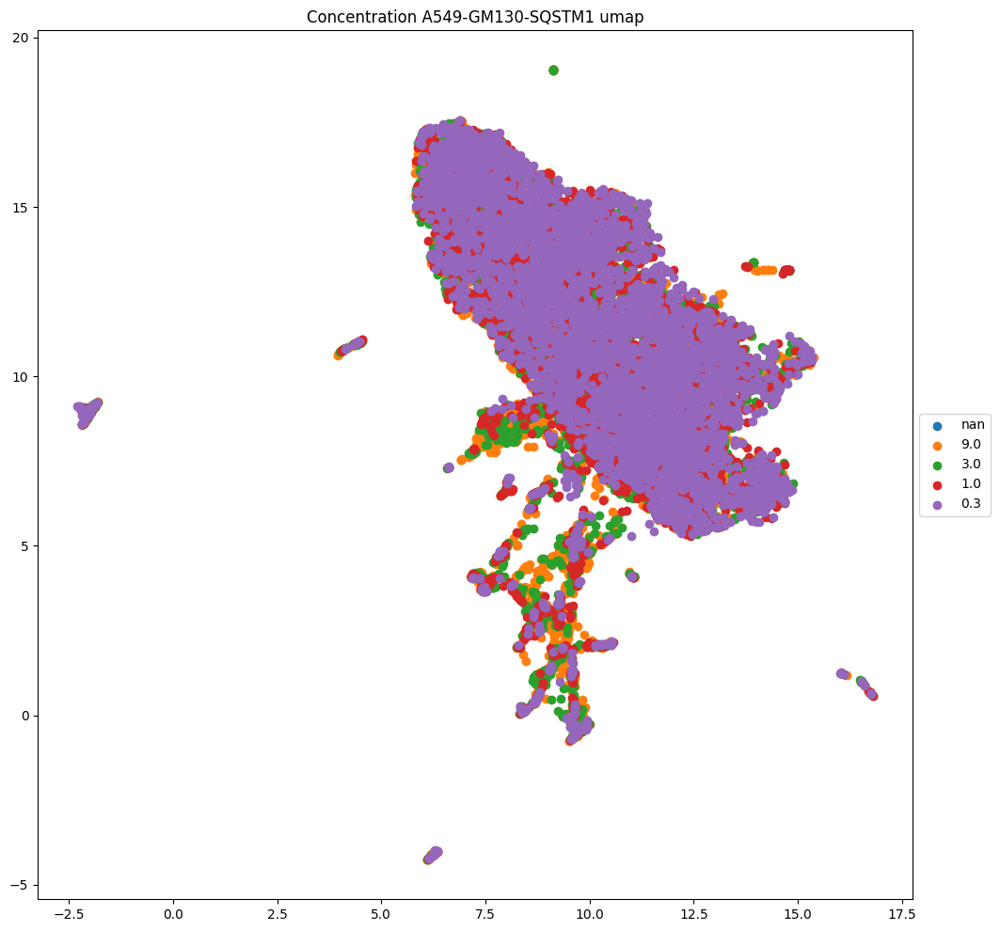

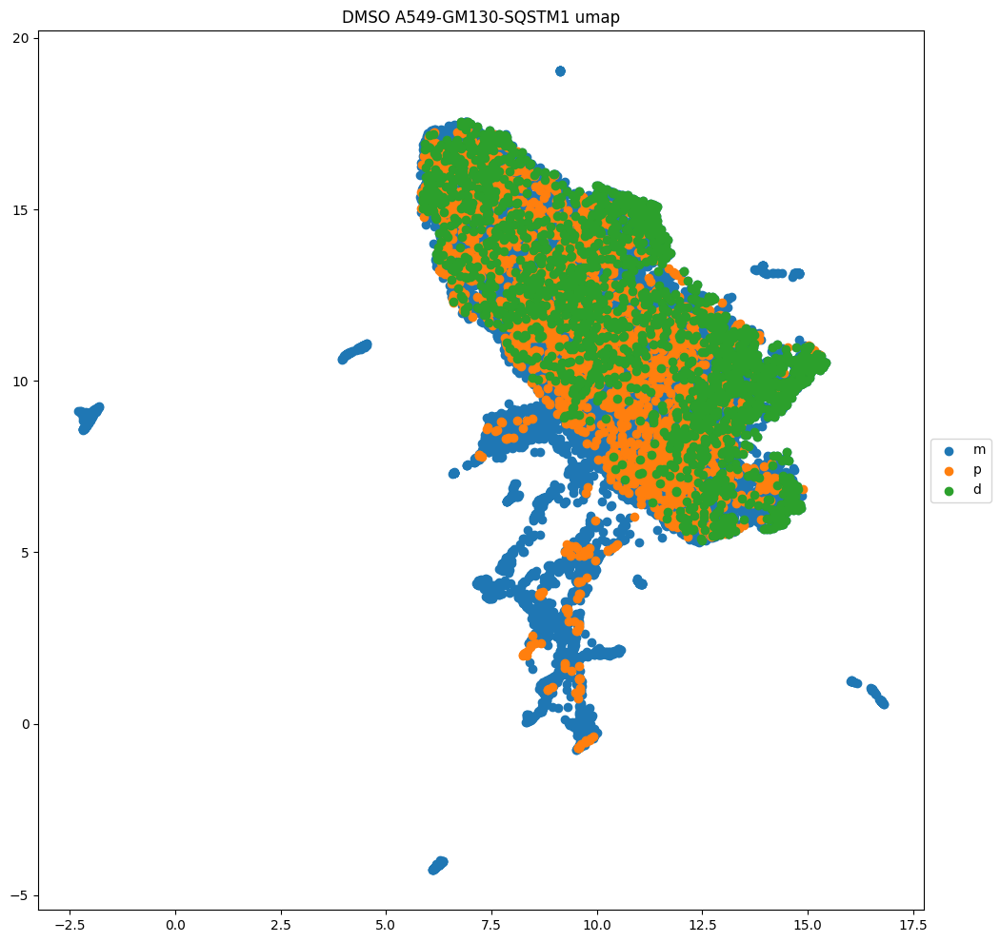

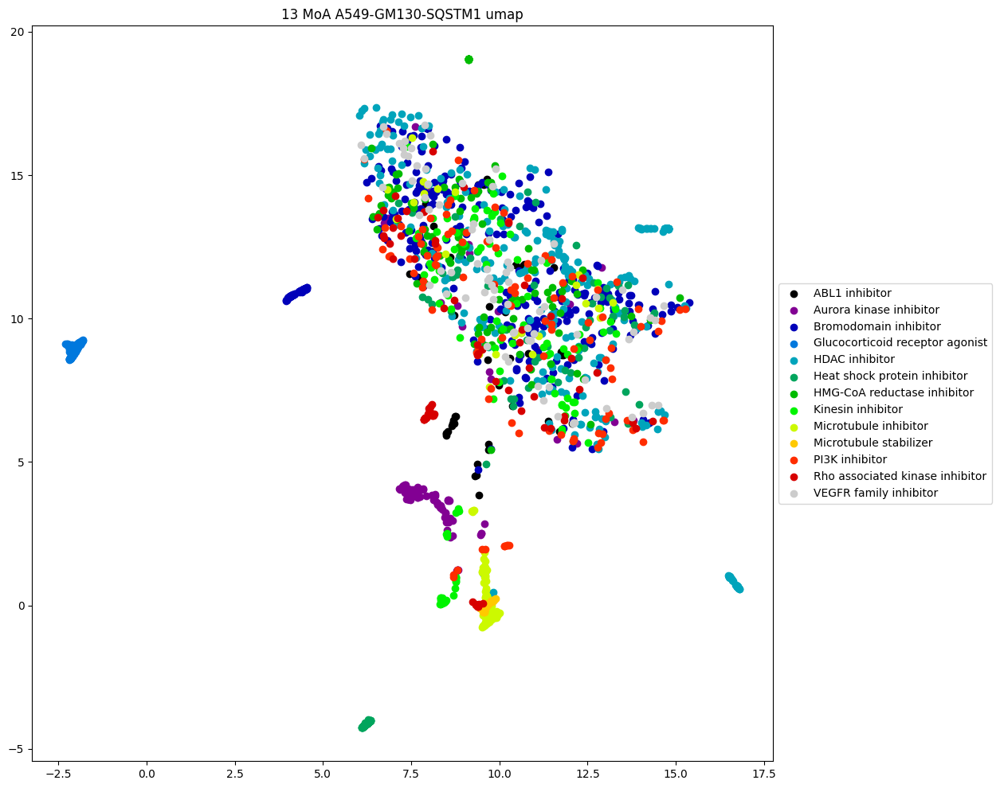

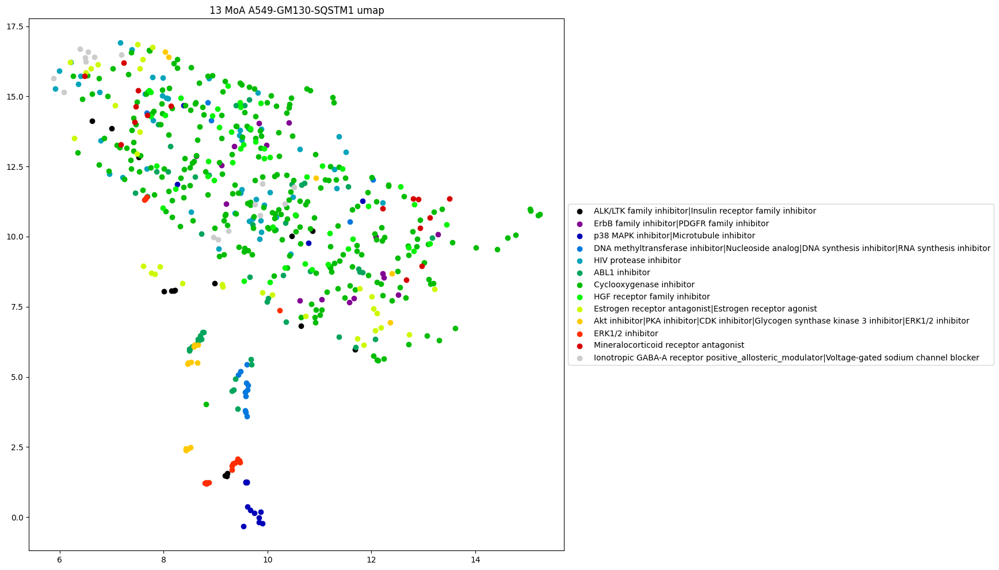

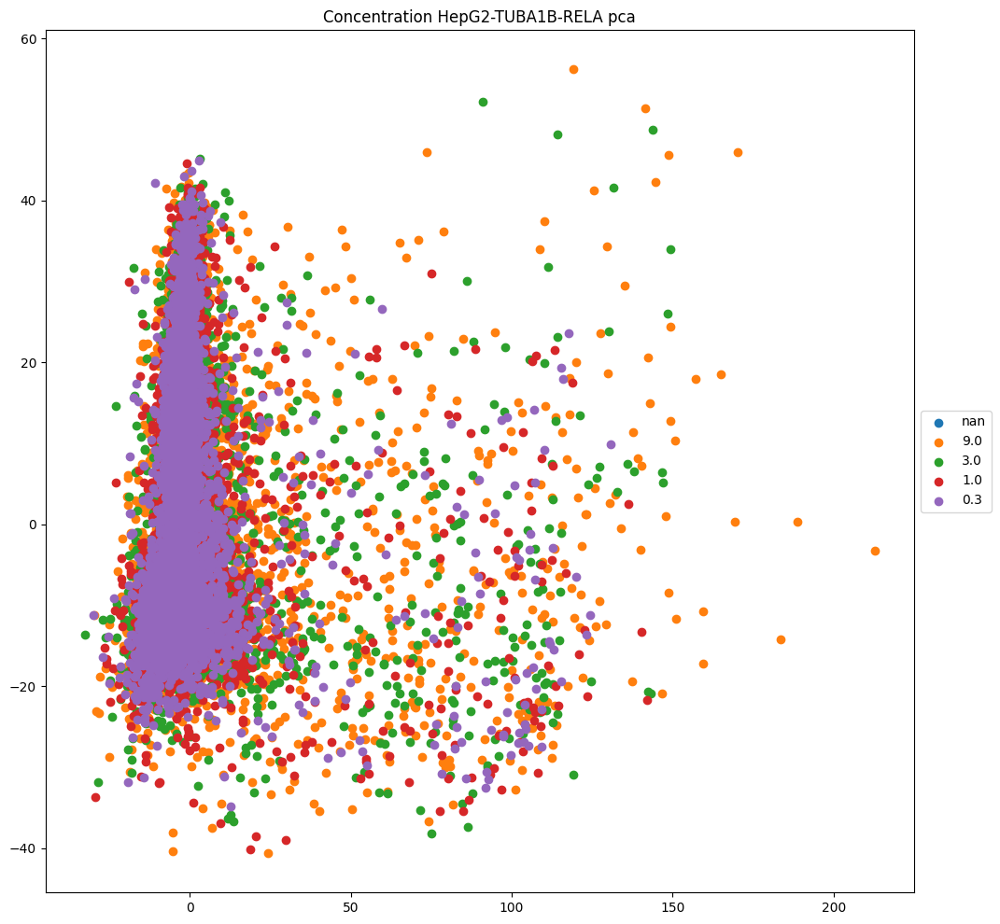

...

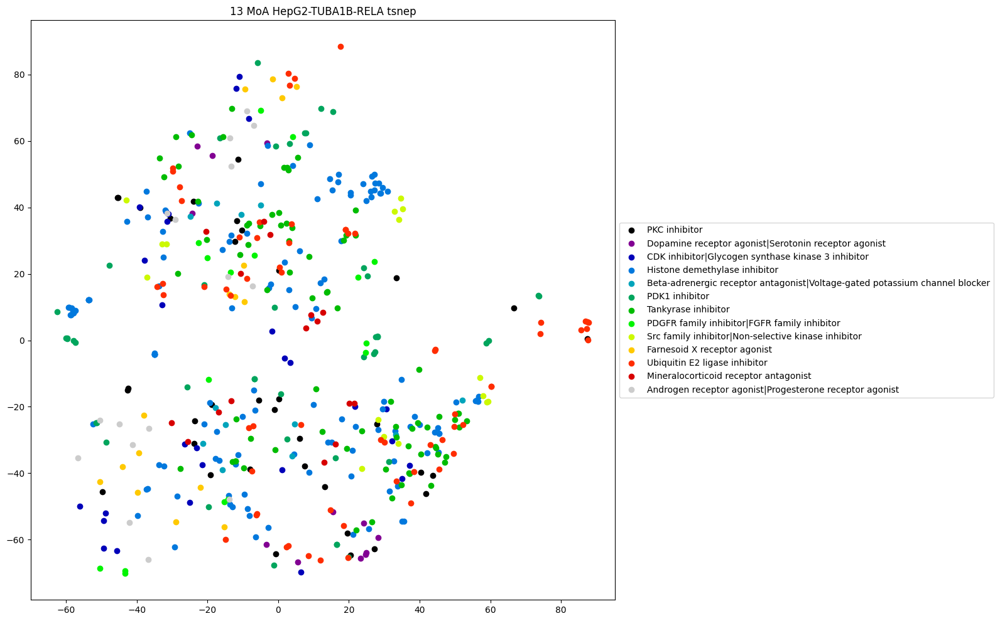

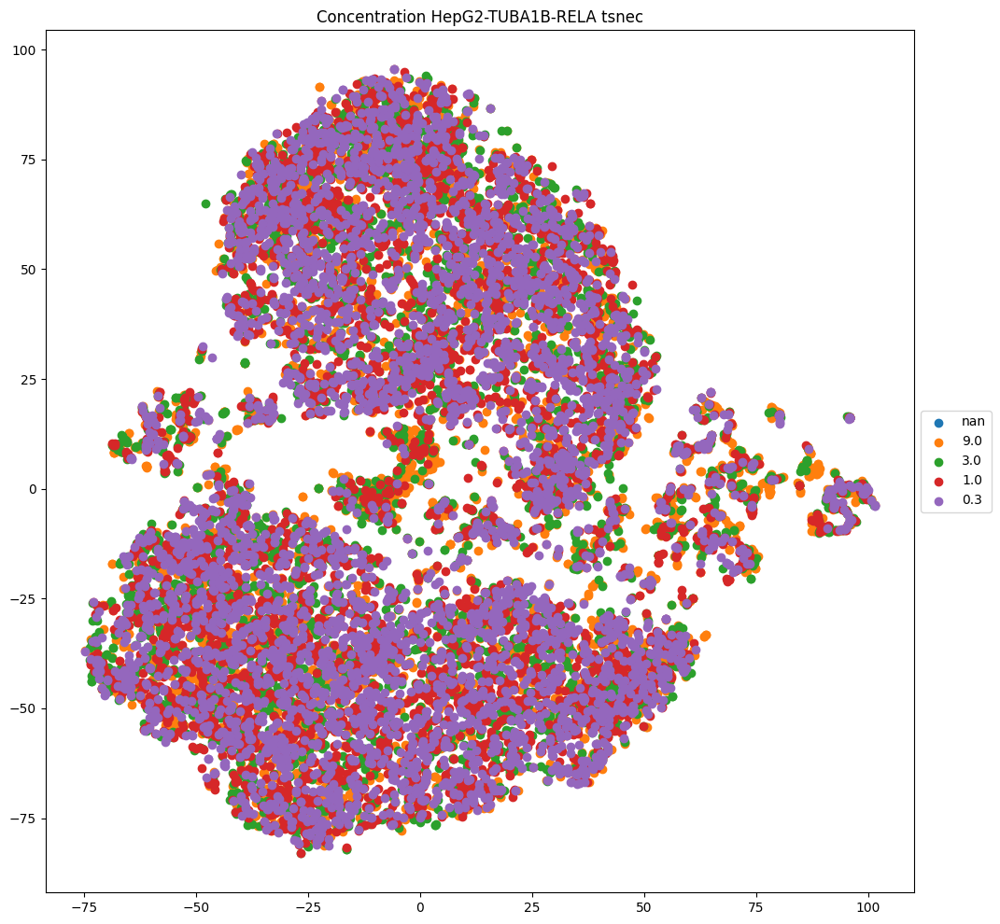

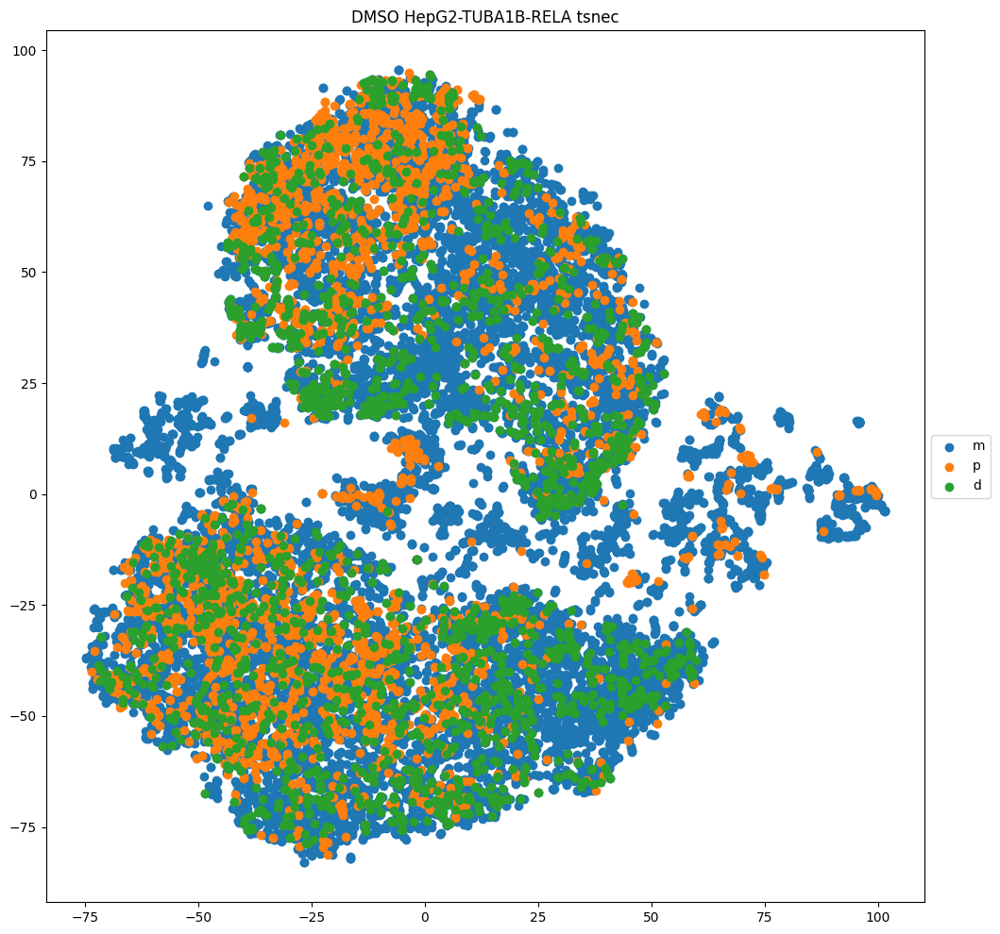

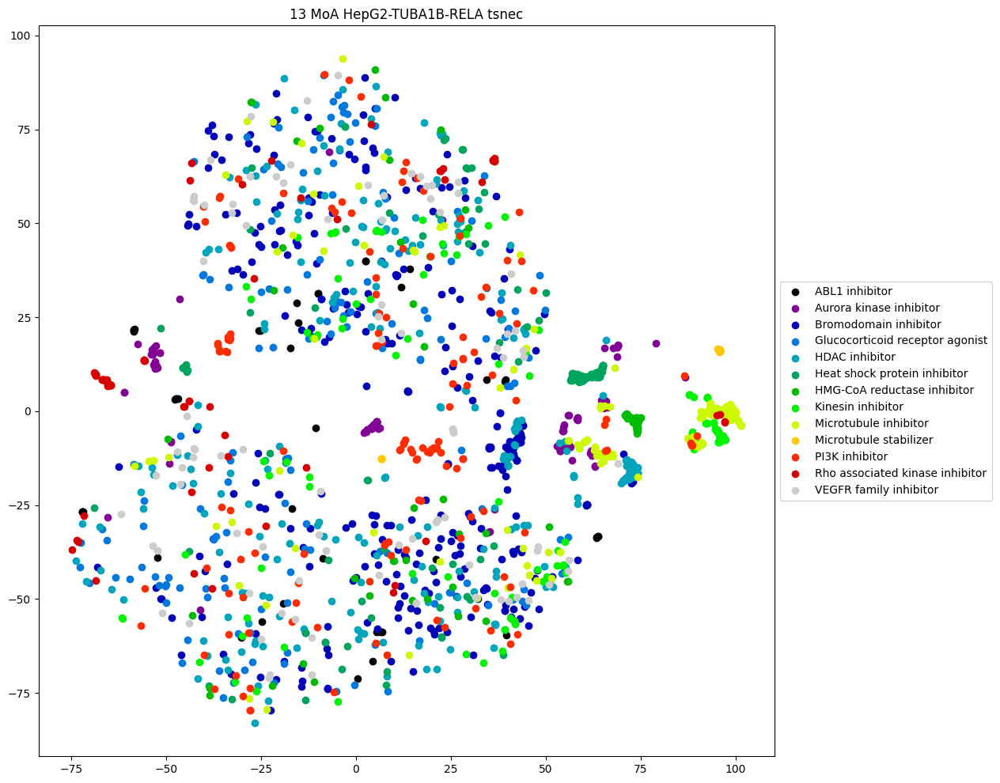

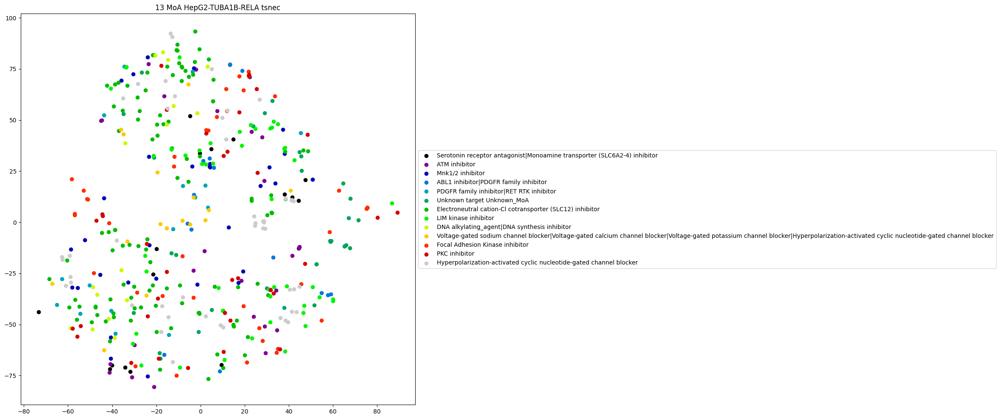

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


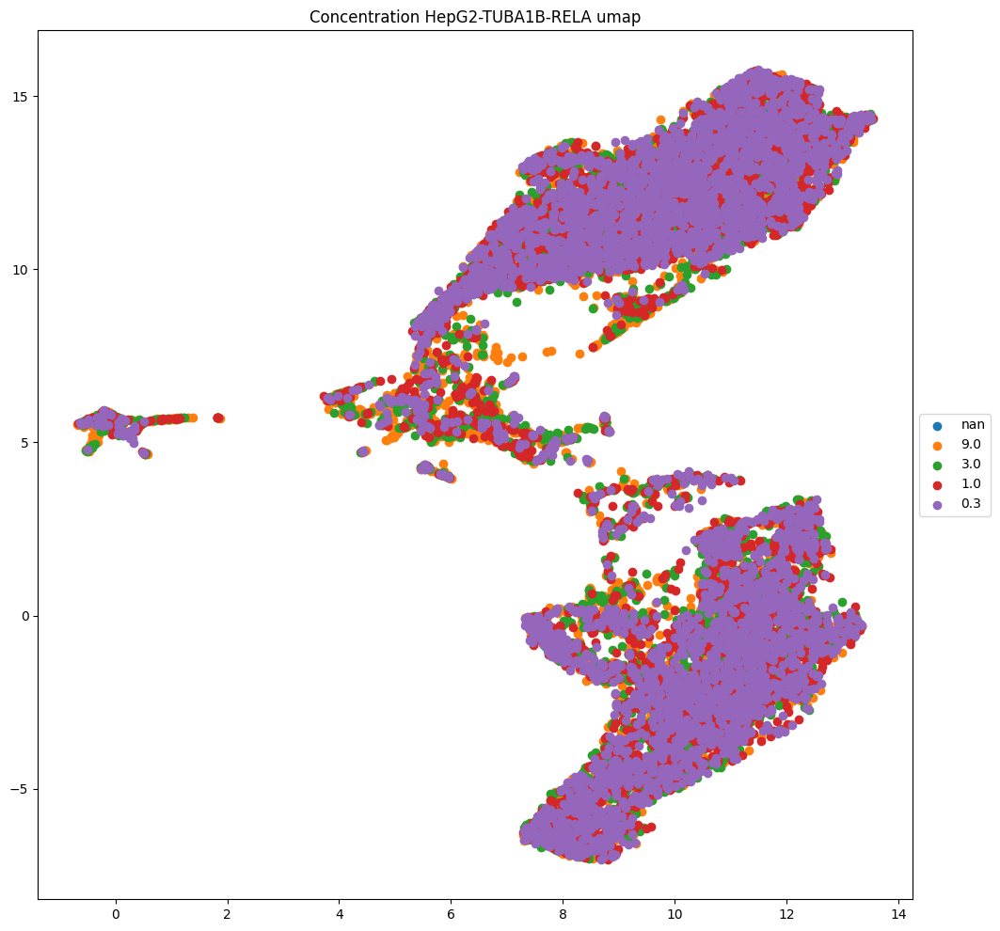

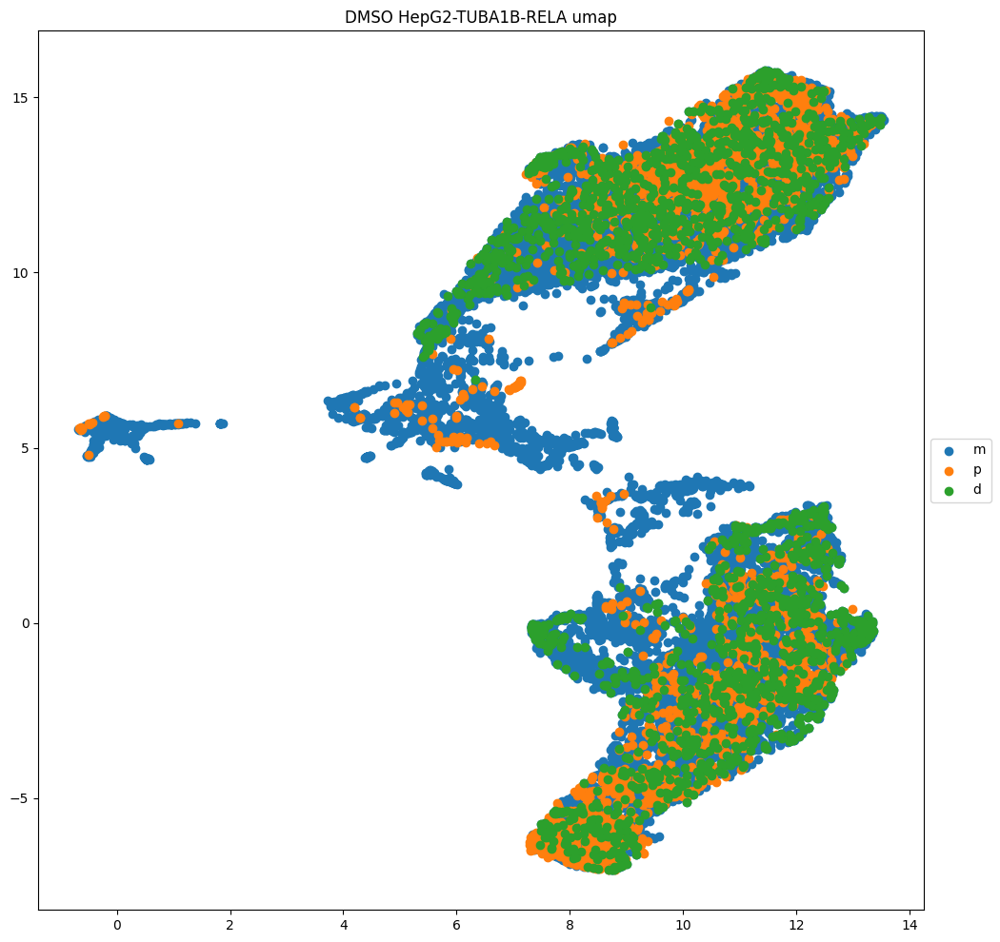

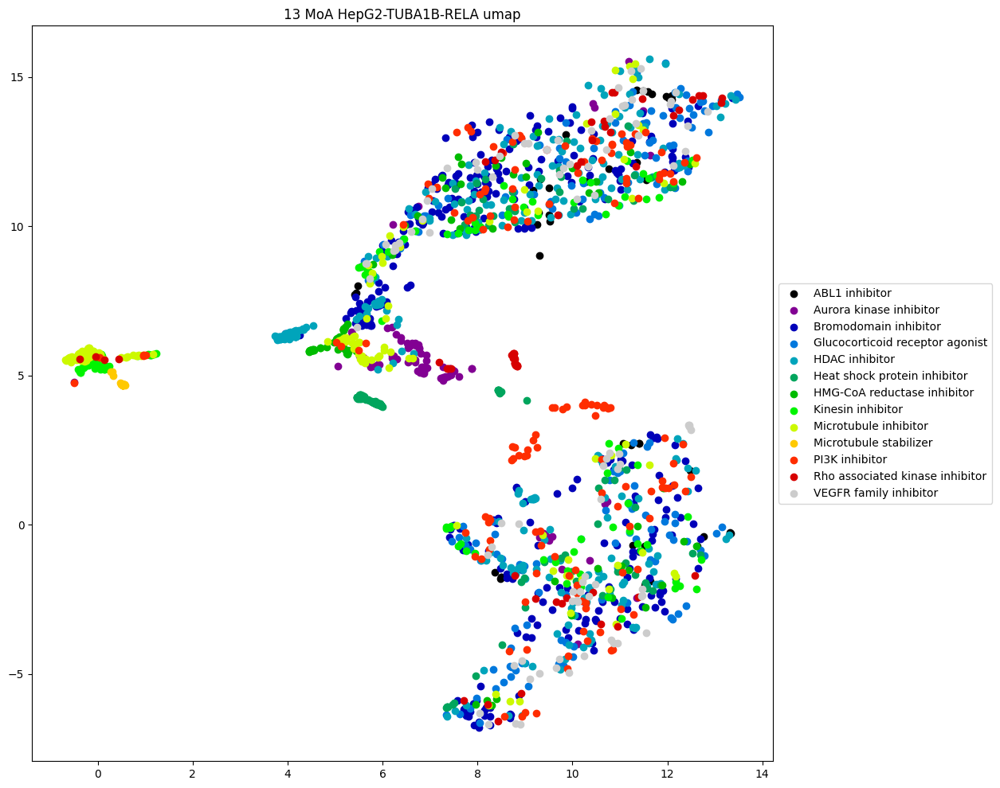

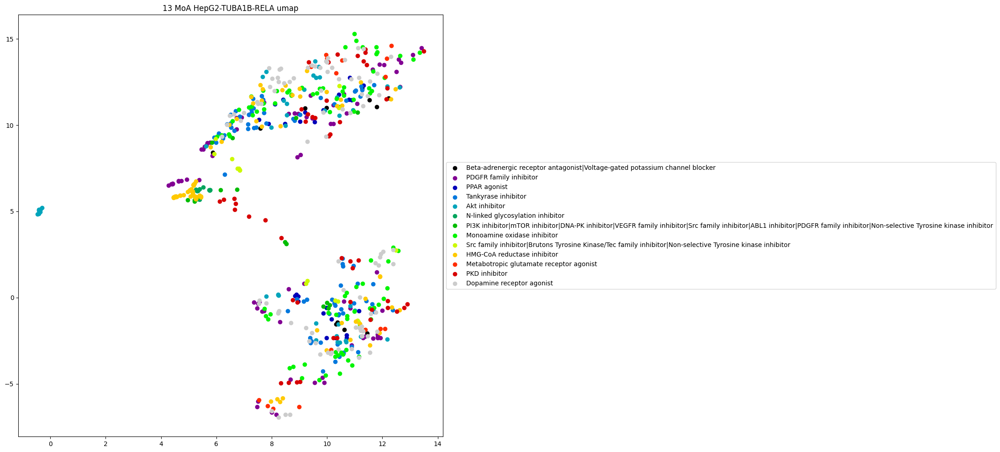

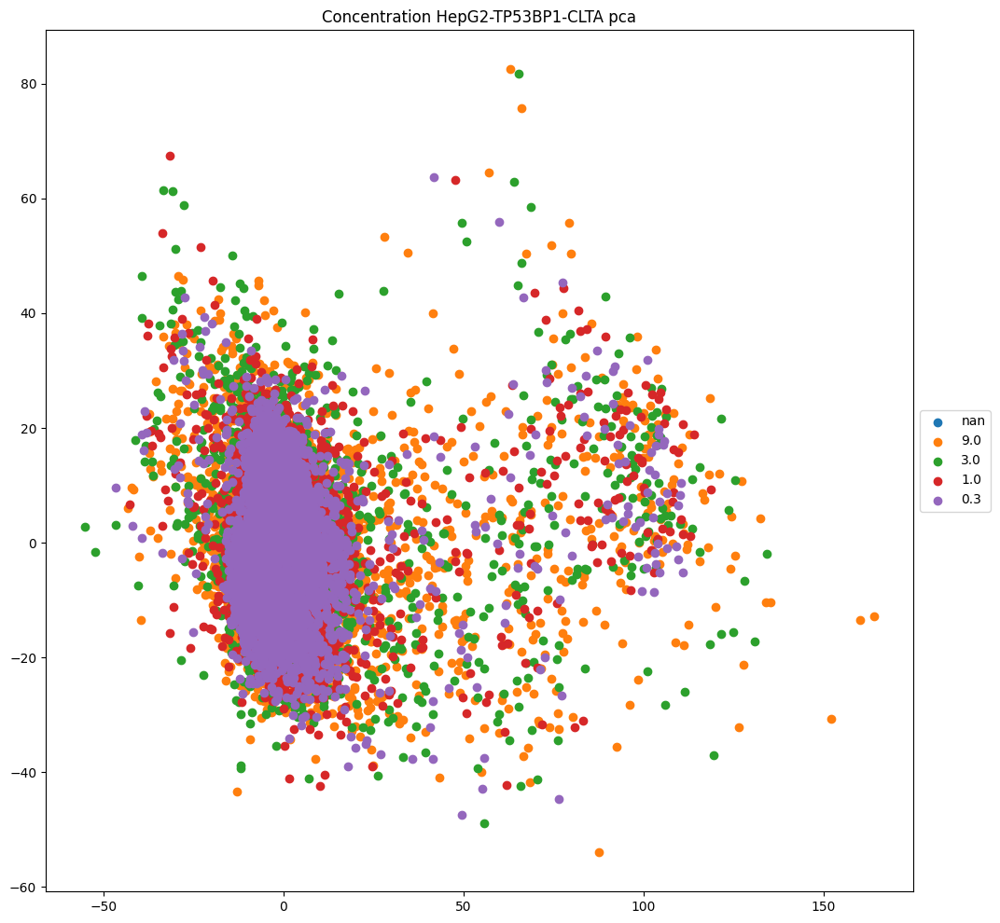

...

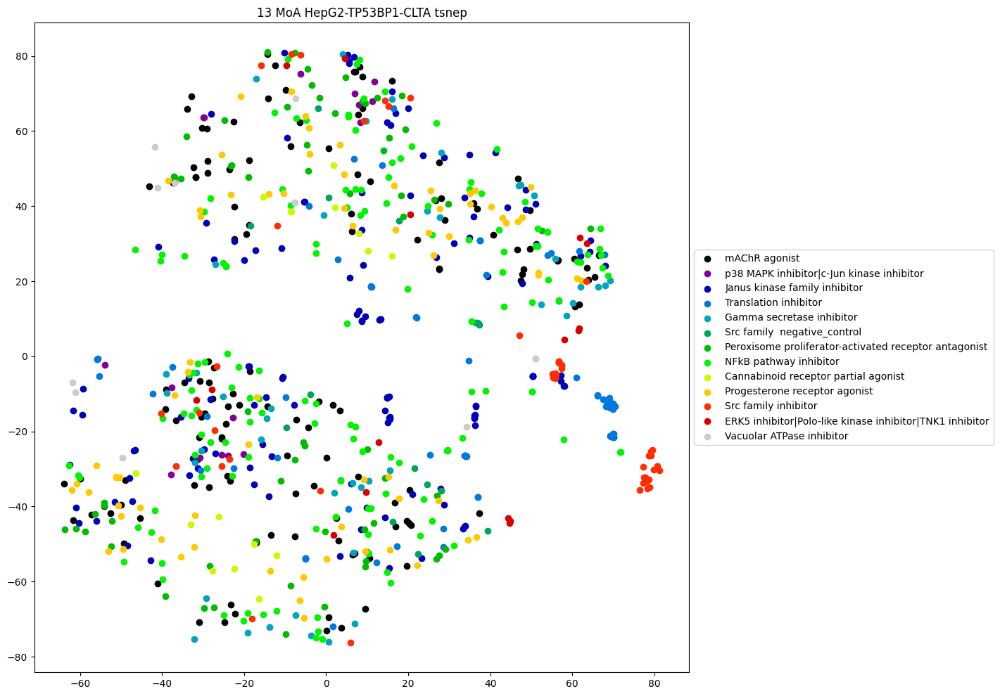

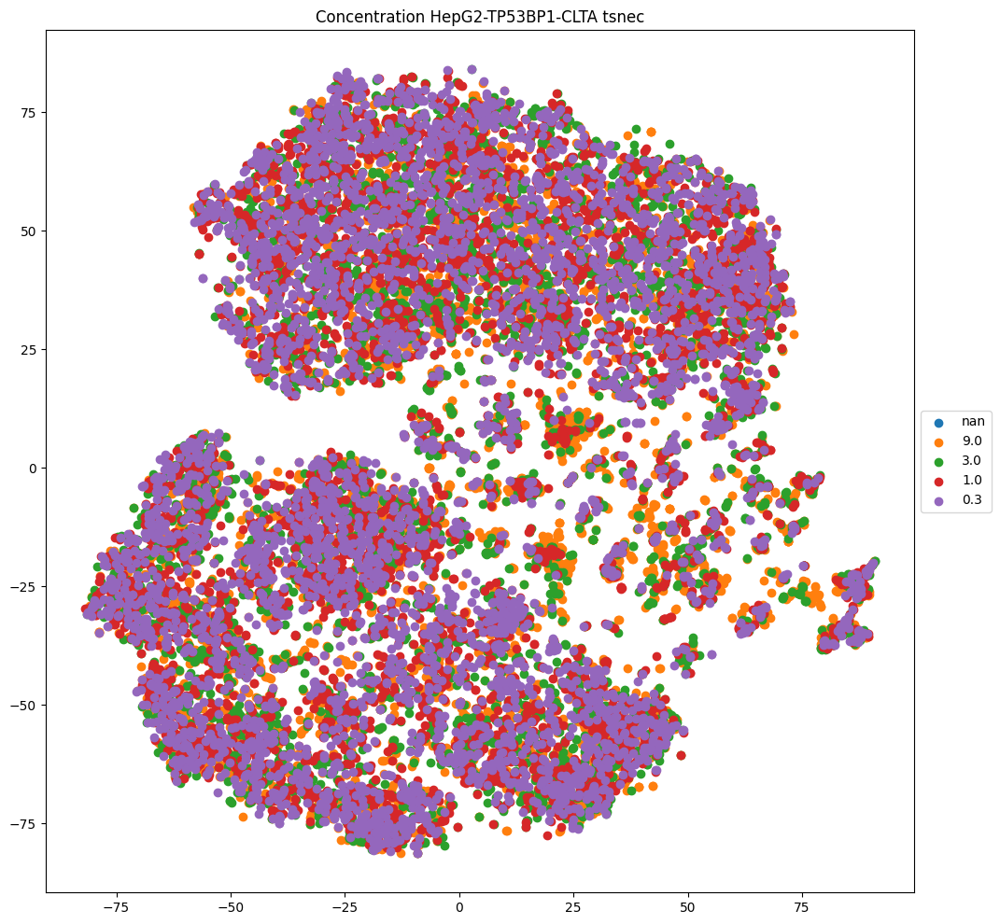

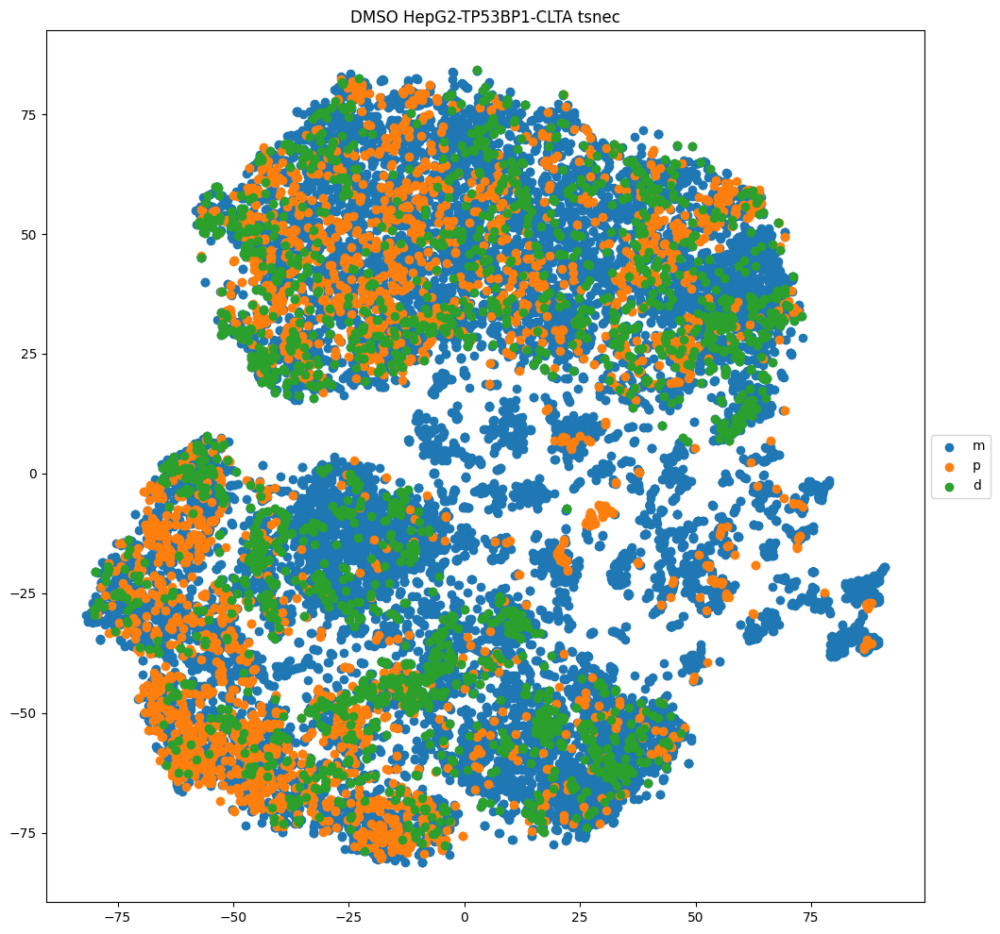

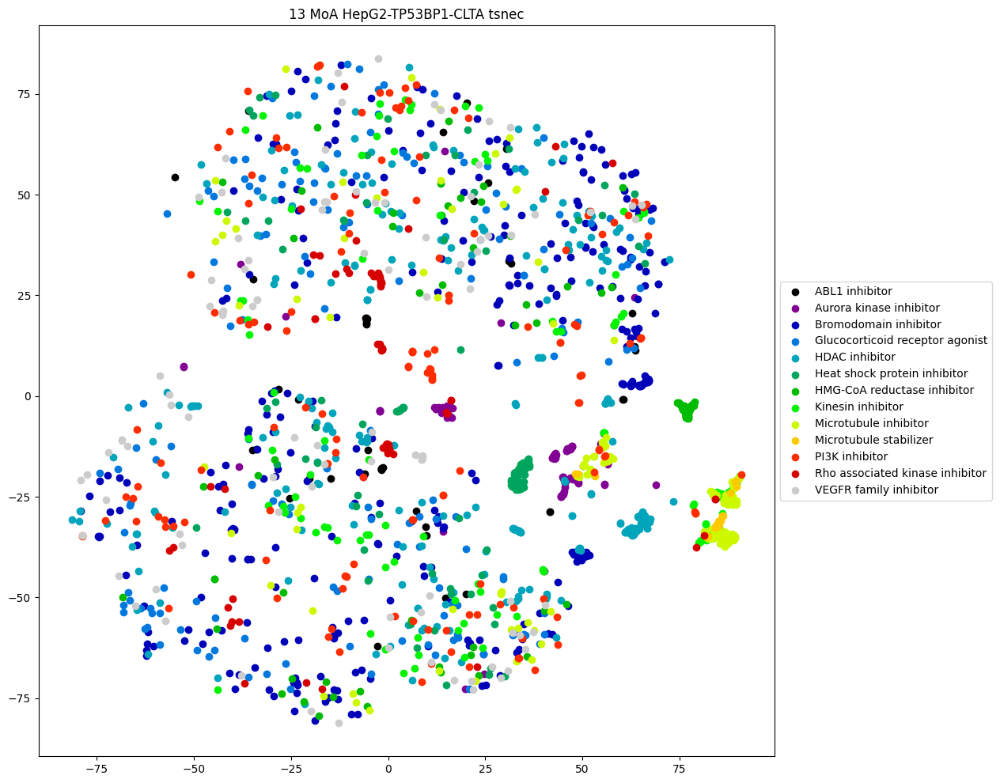

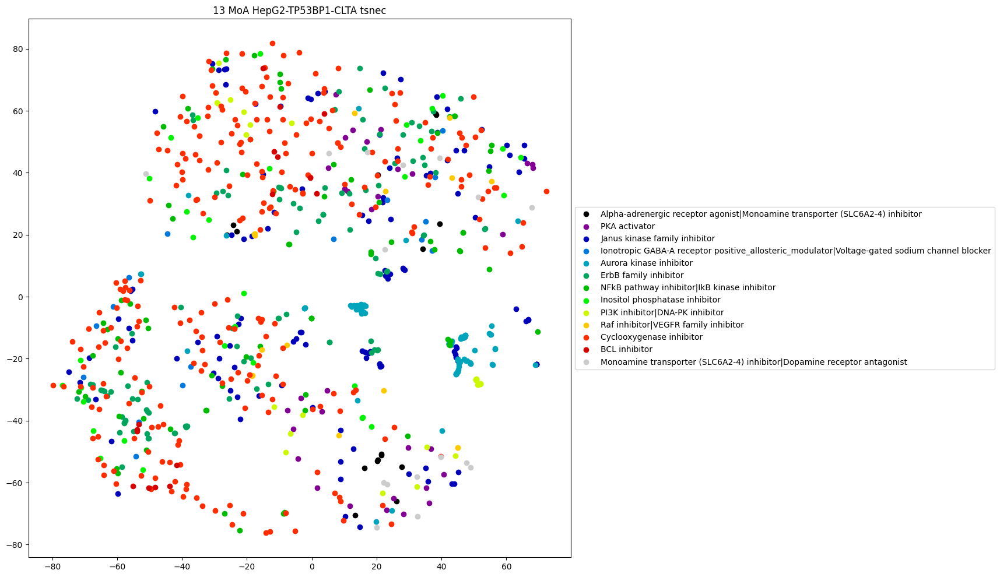

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


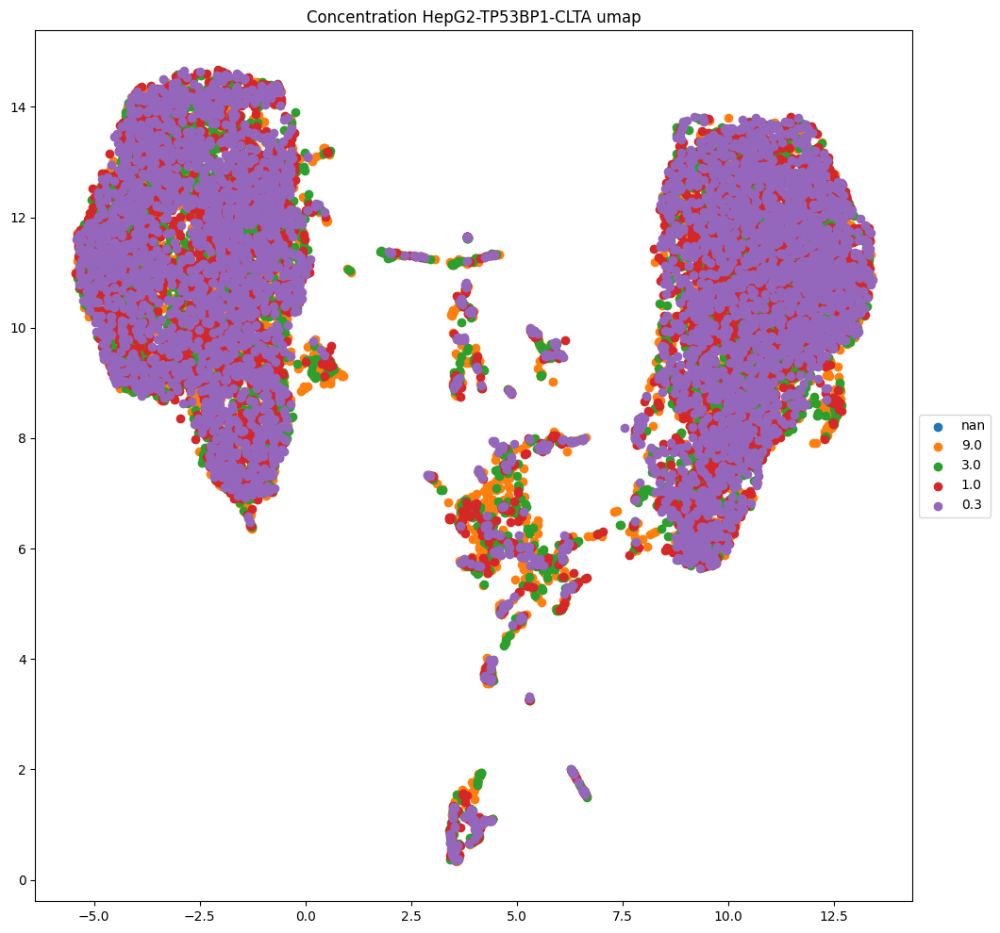

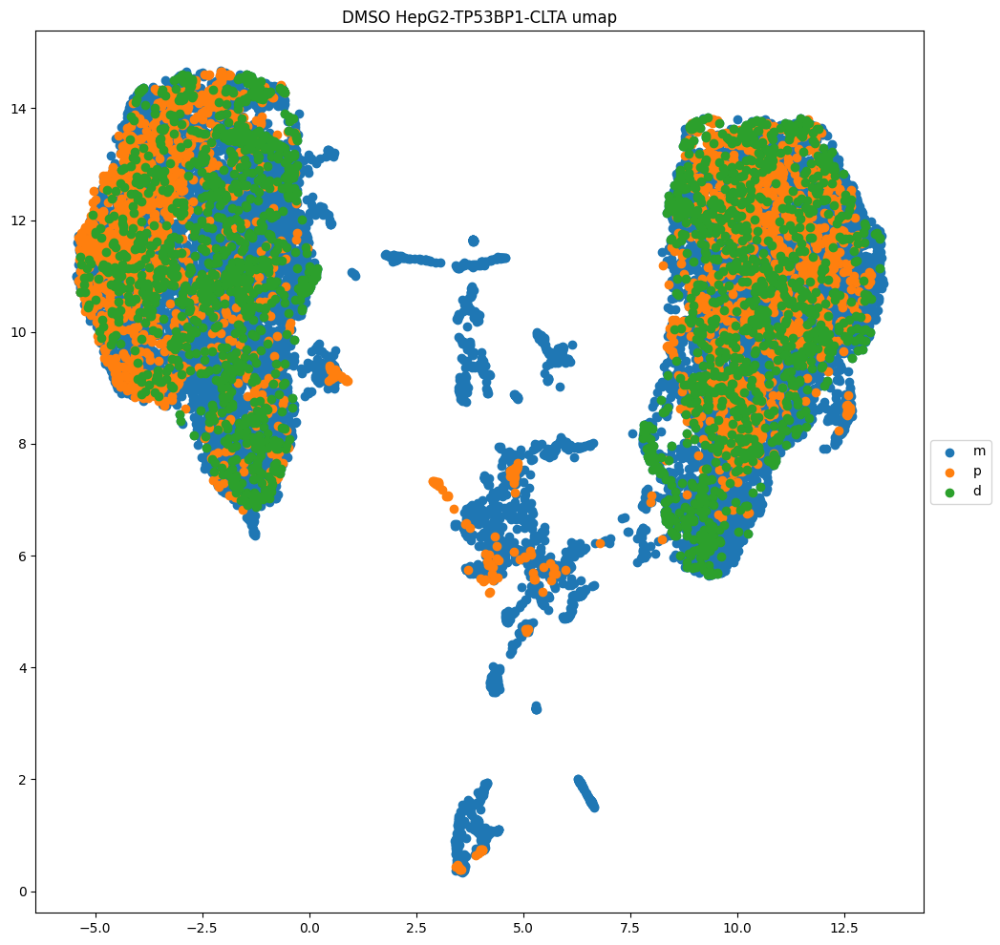

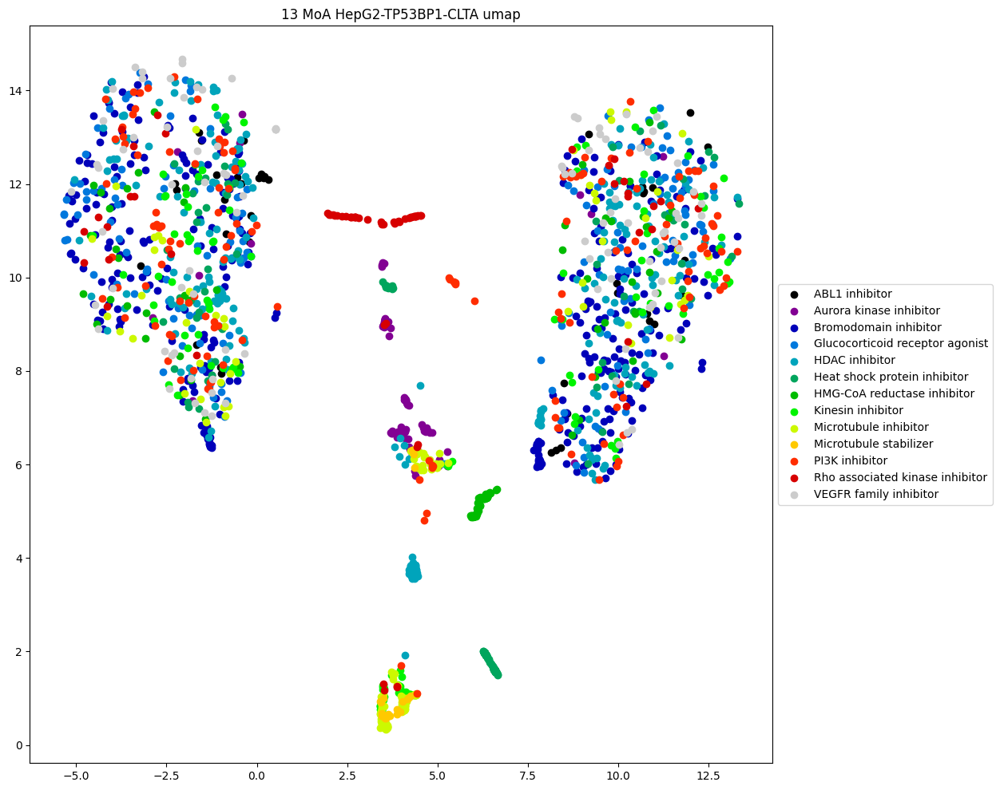

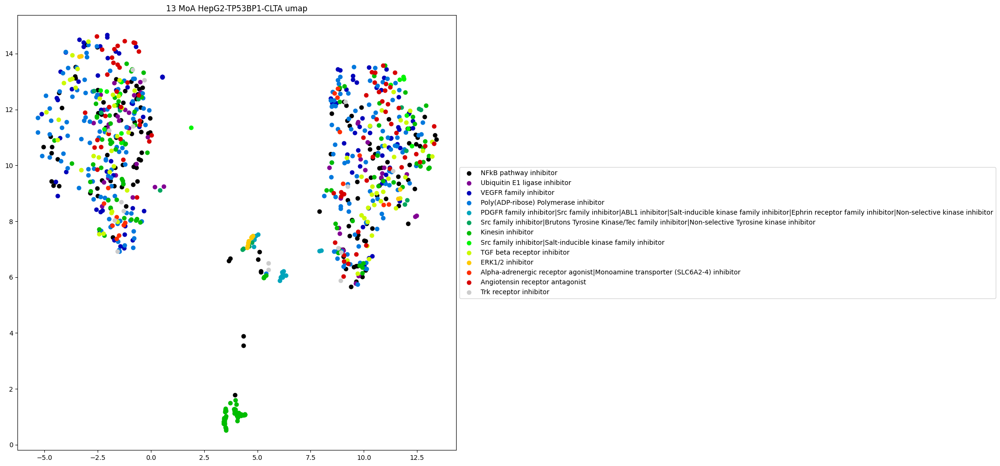

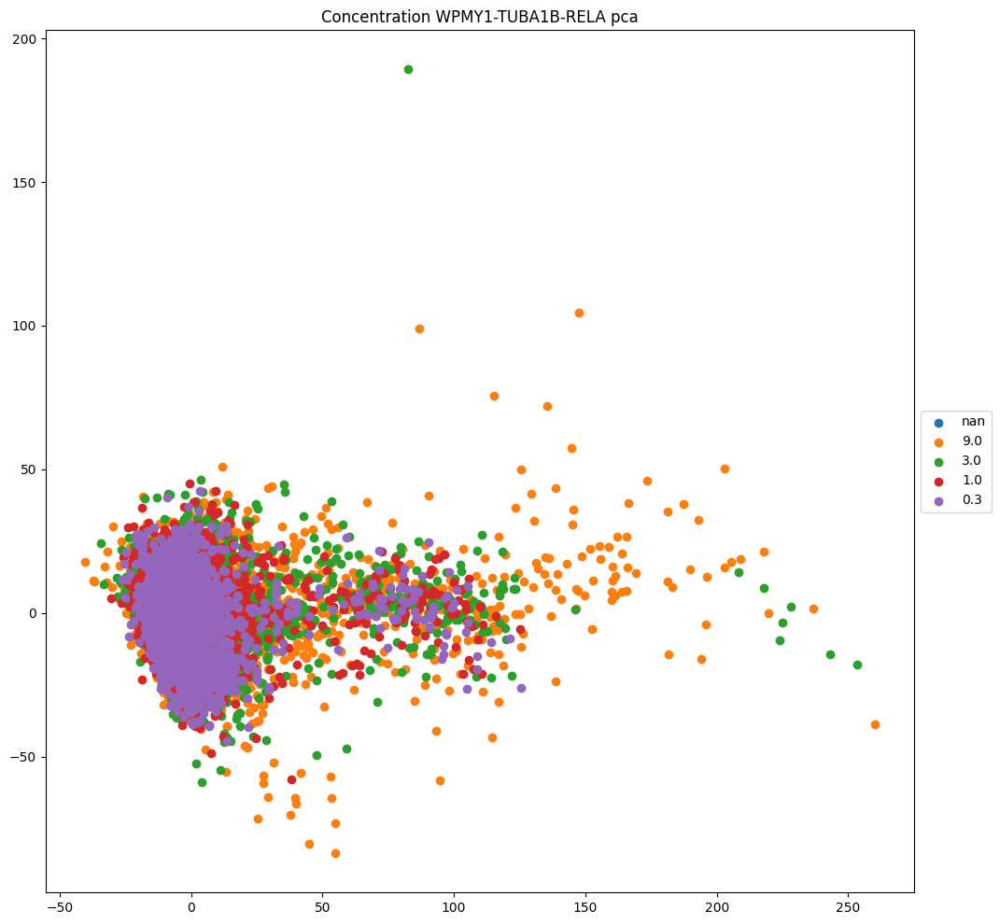

...

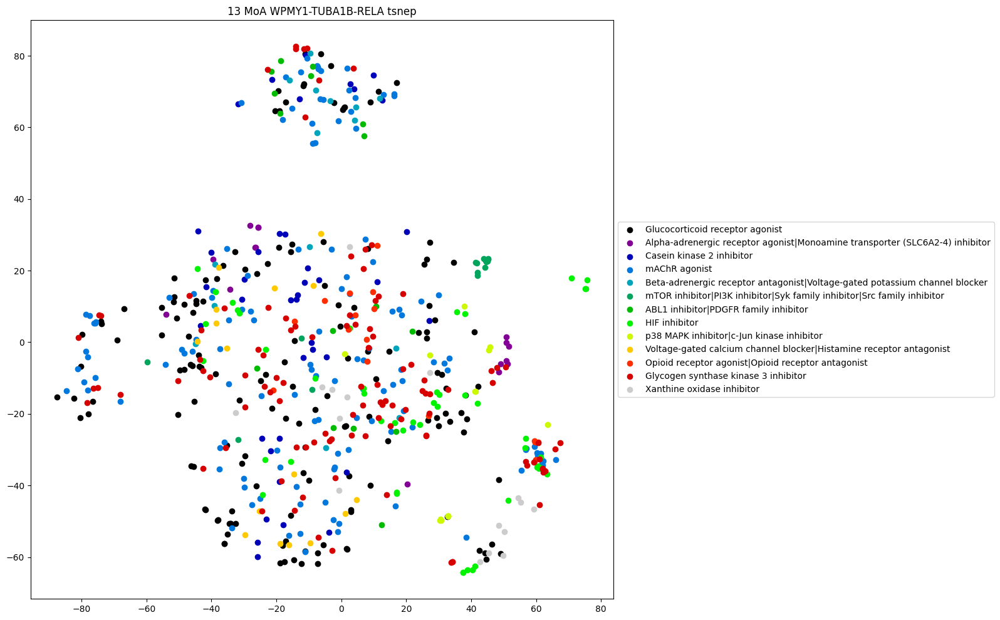

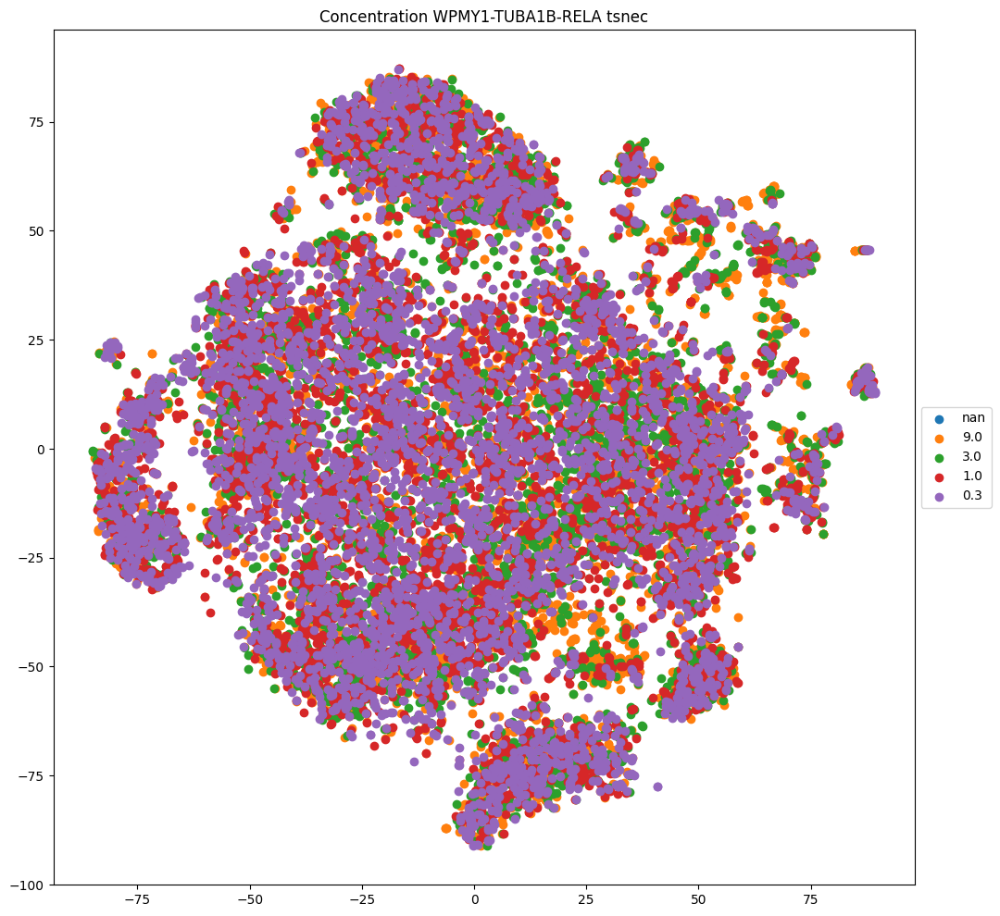

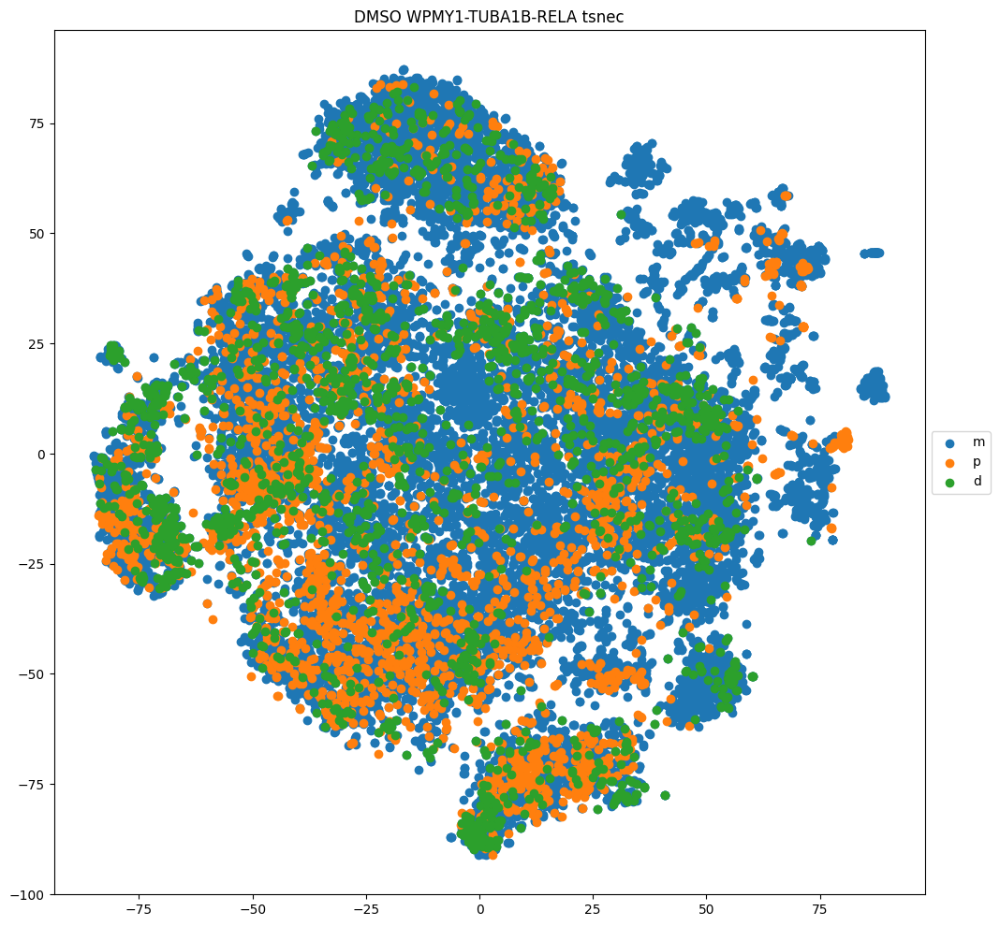

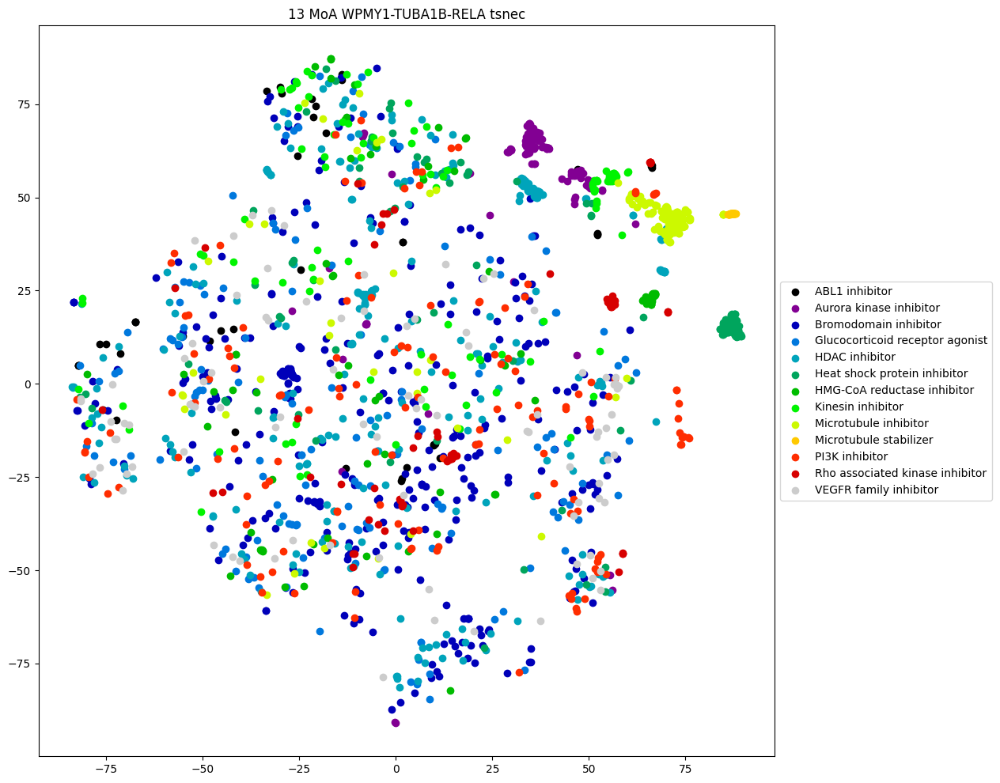

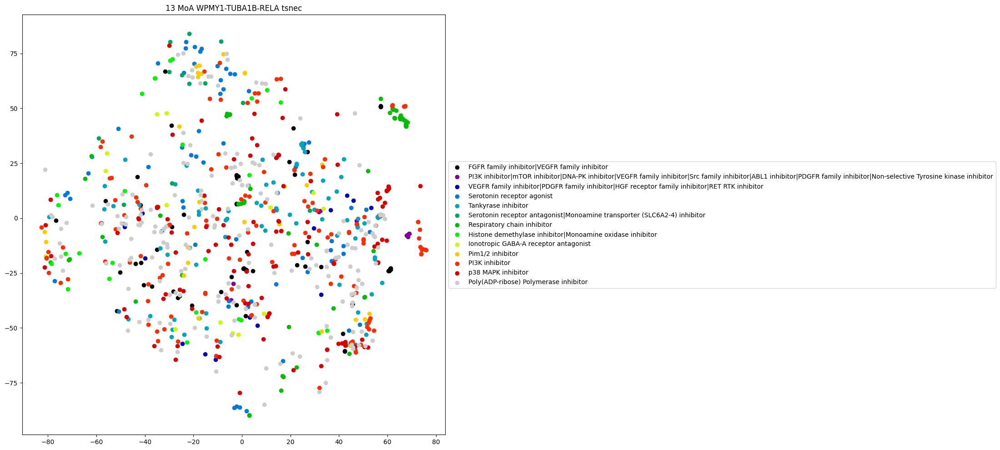

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


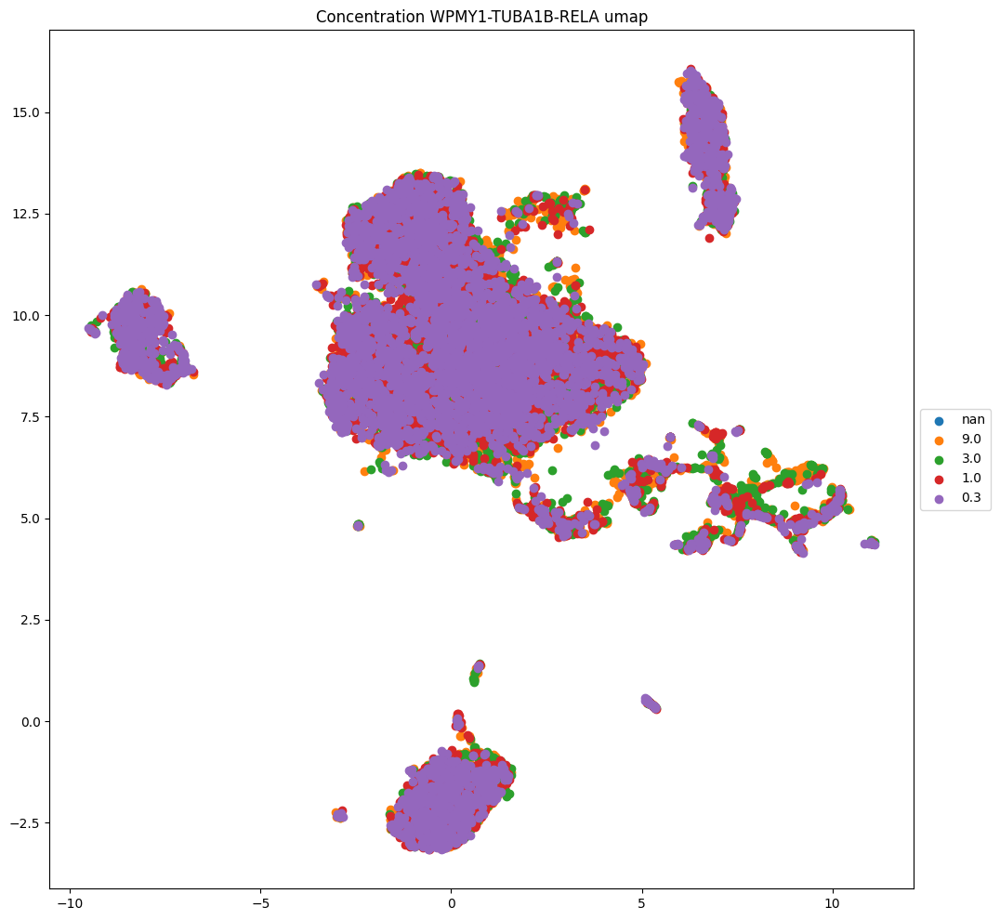

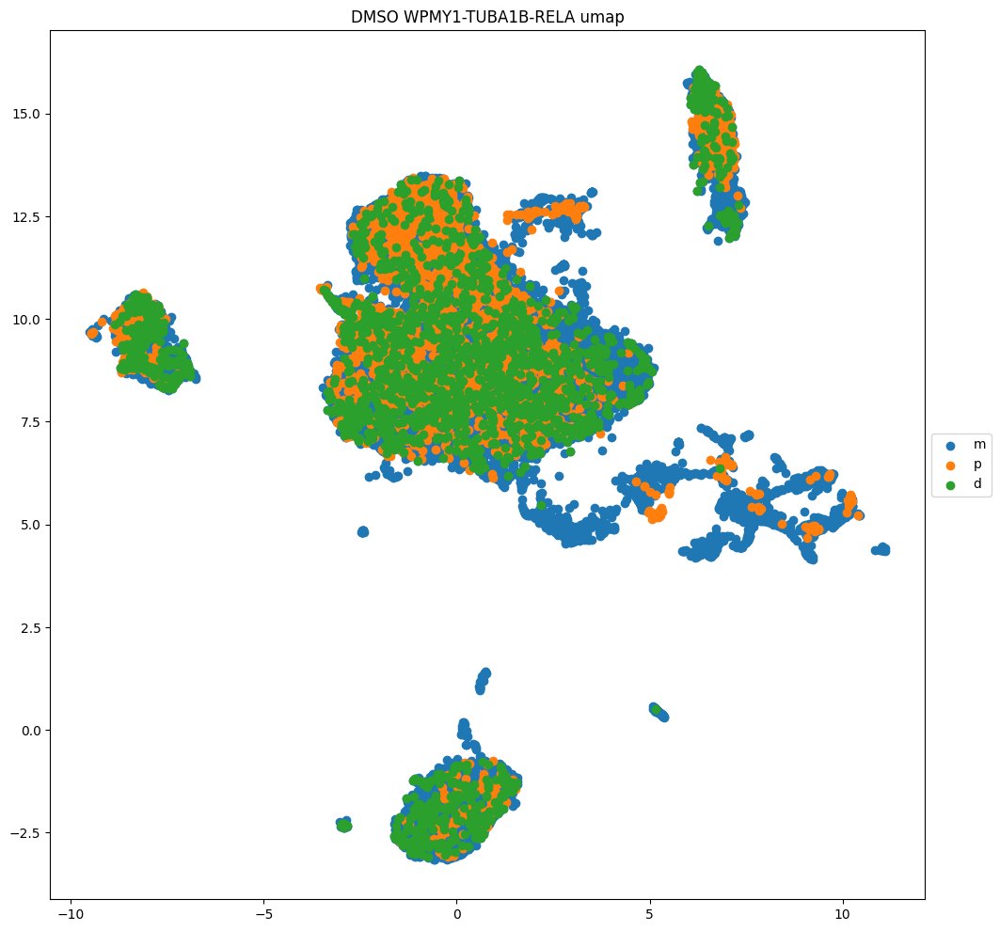

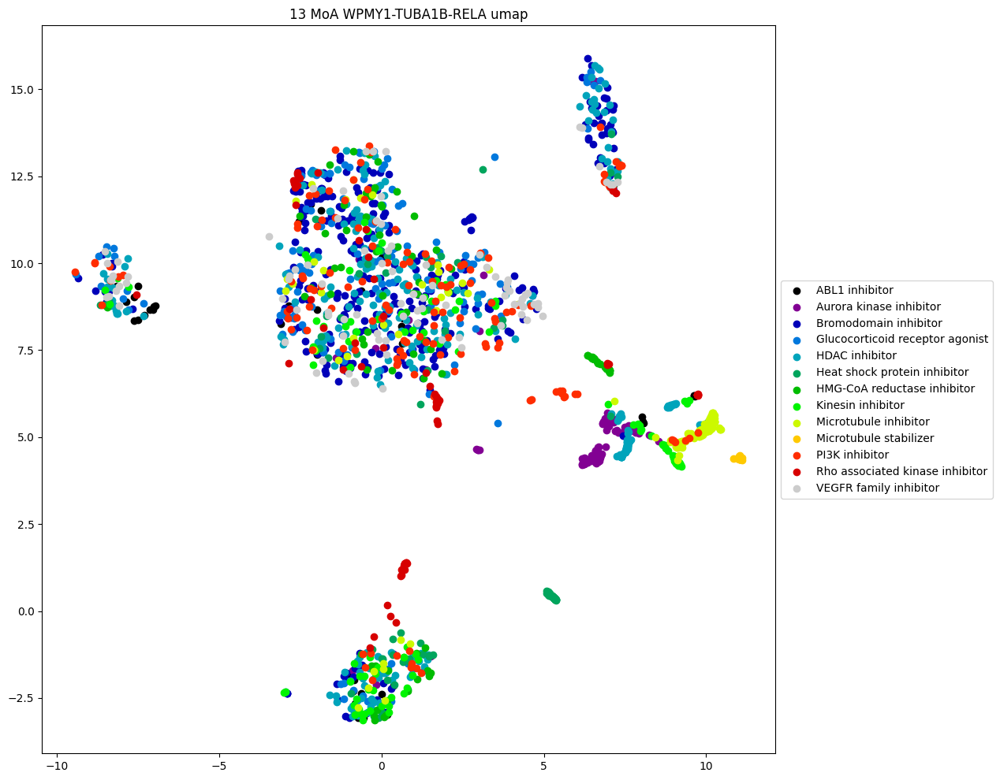

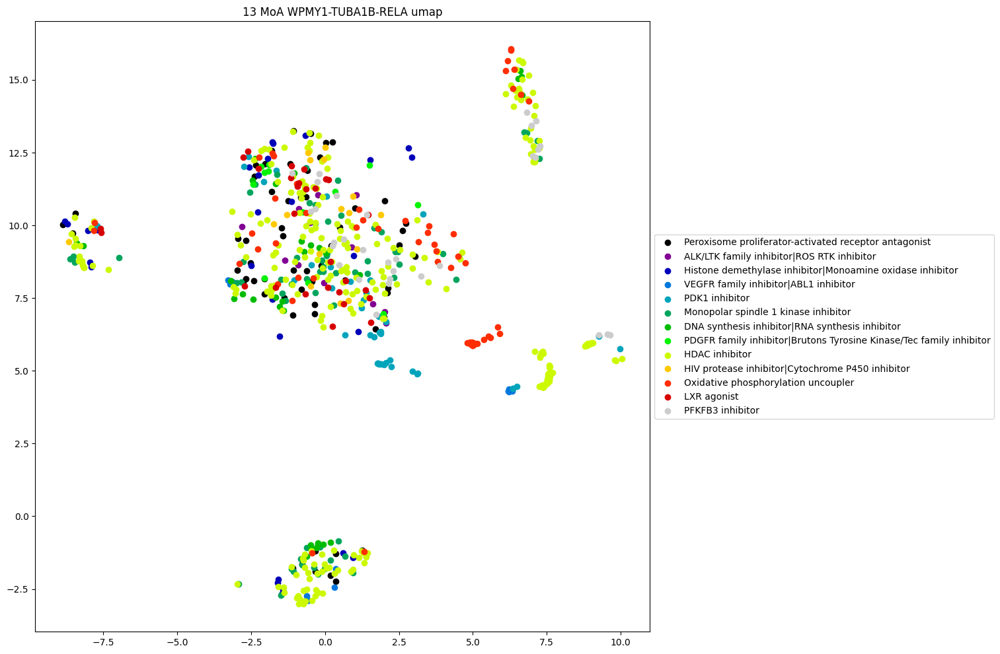

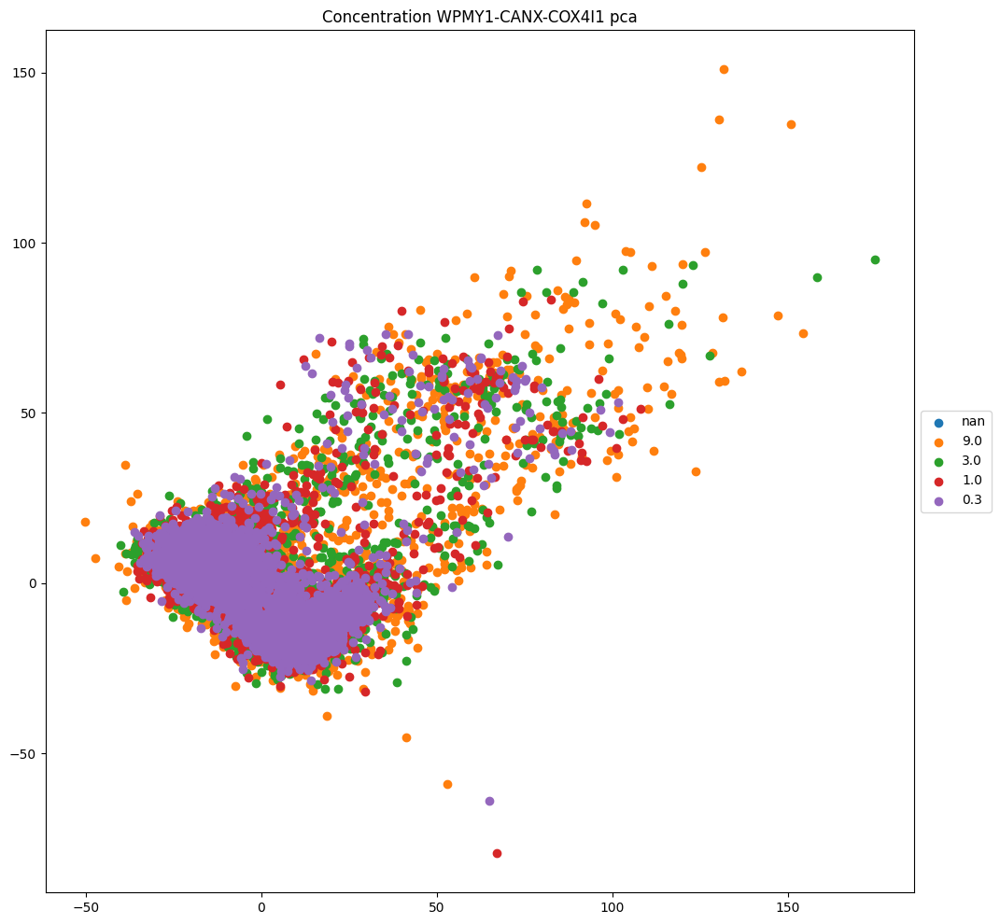

...

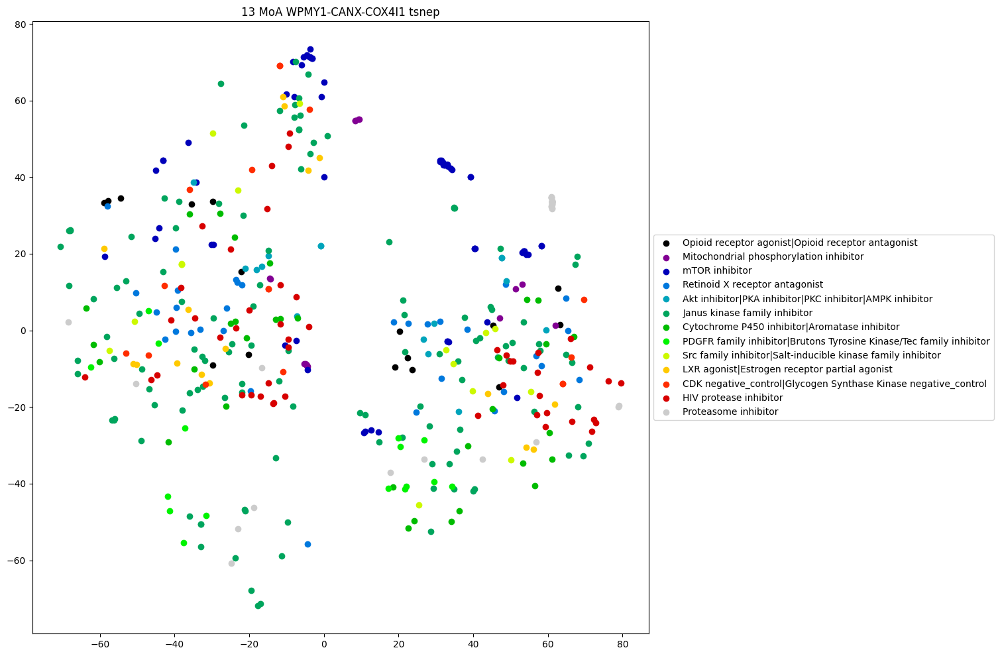

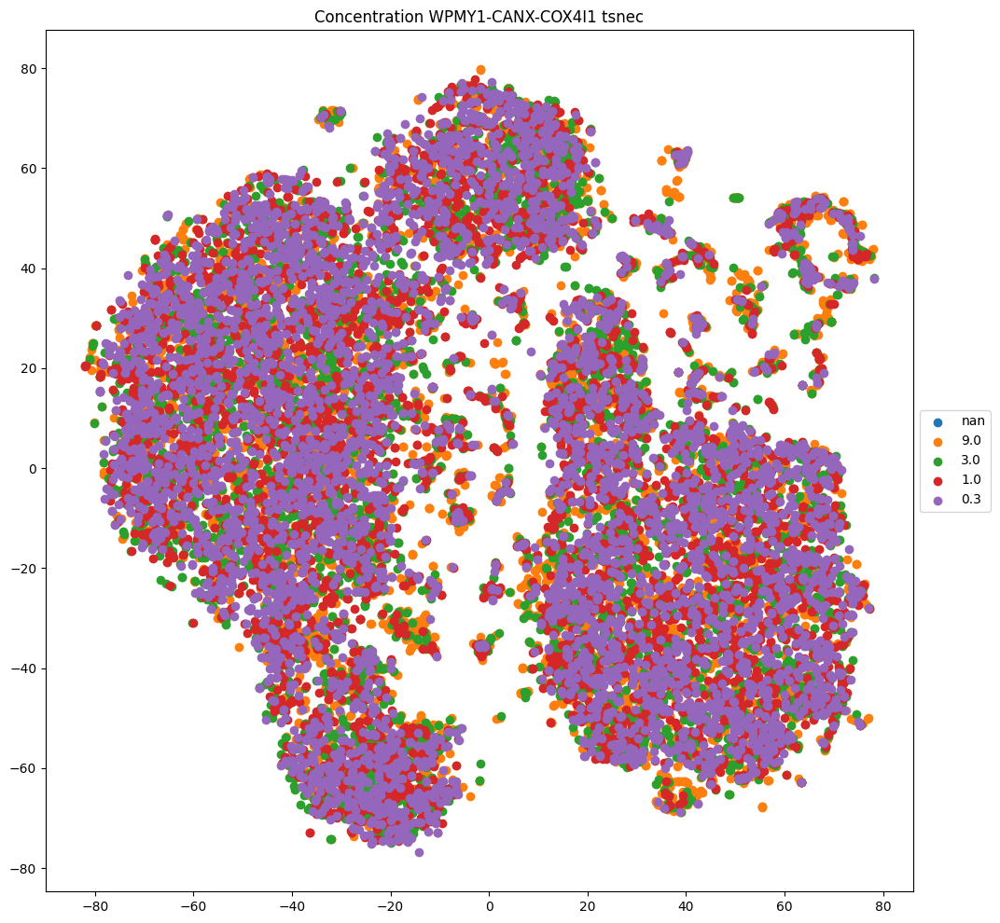

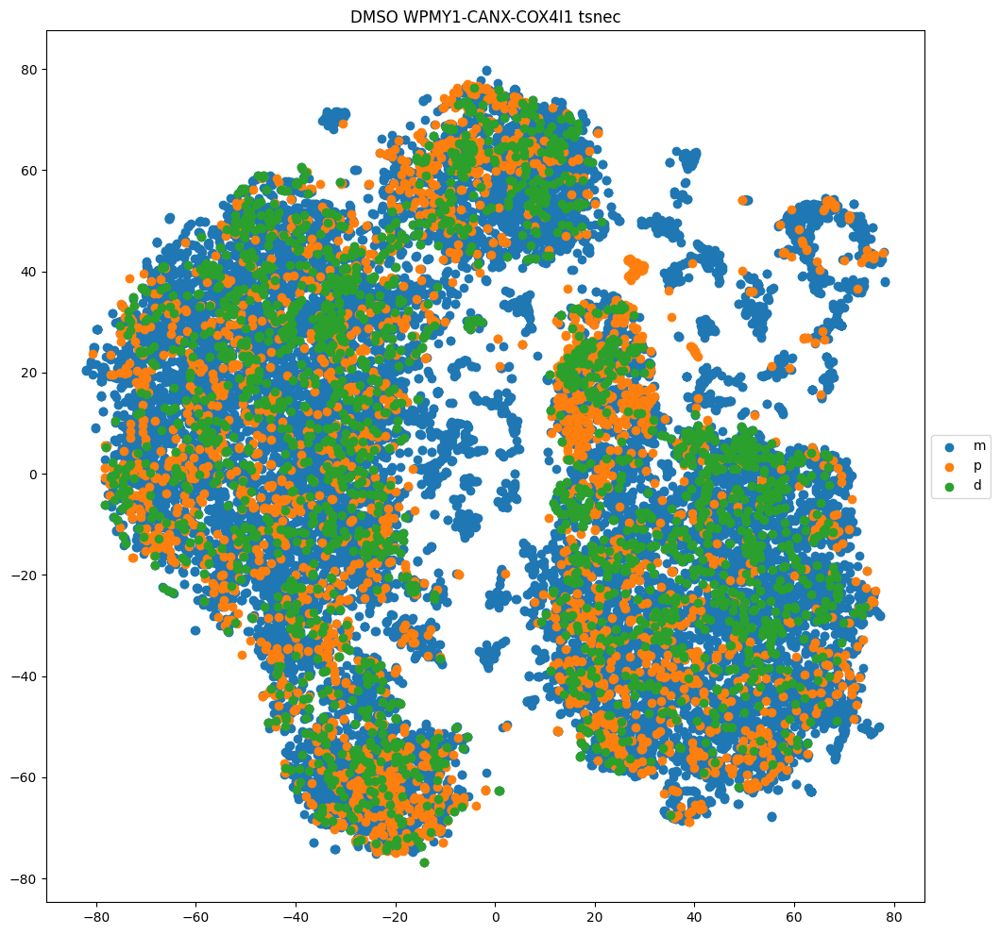

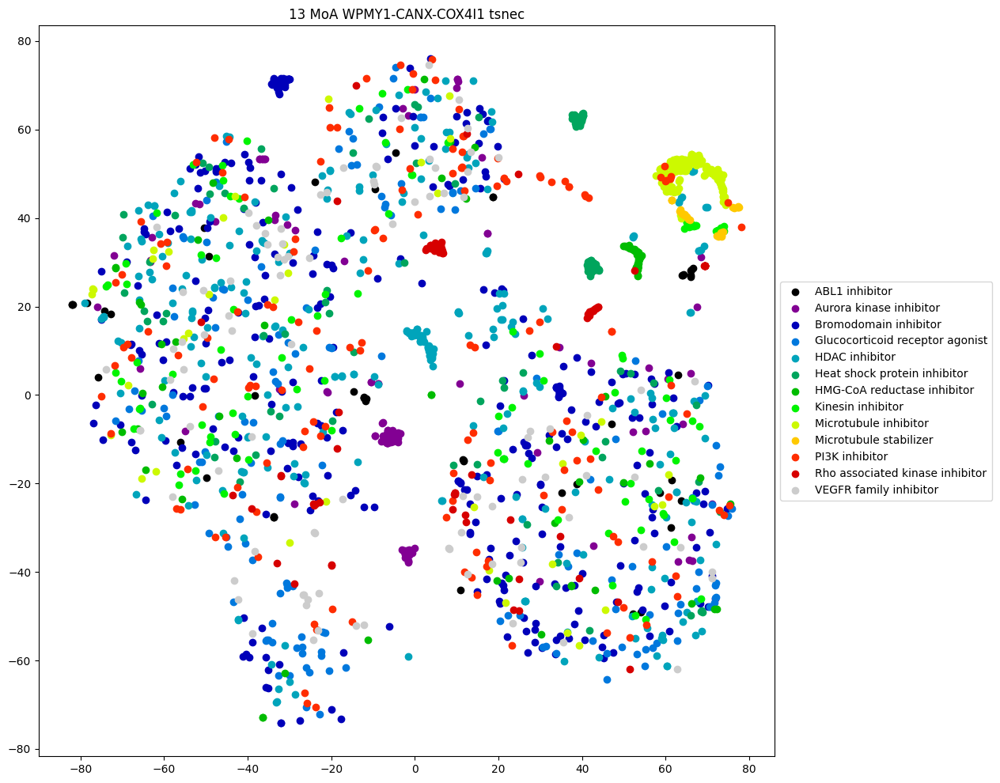

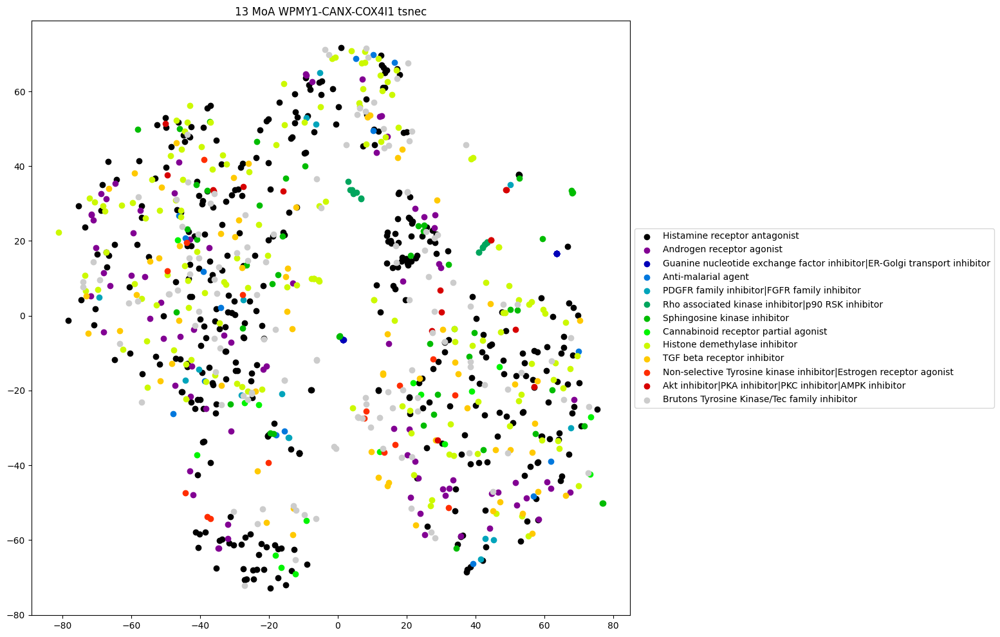

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


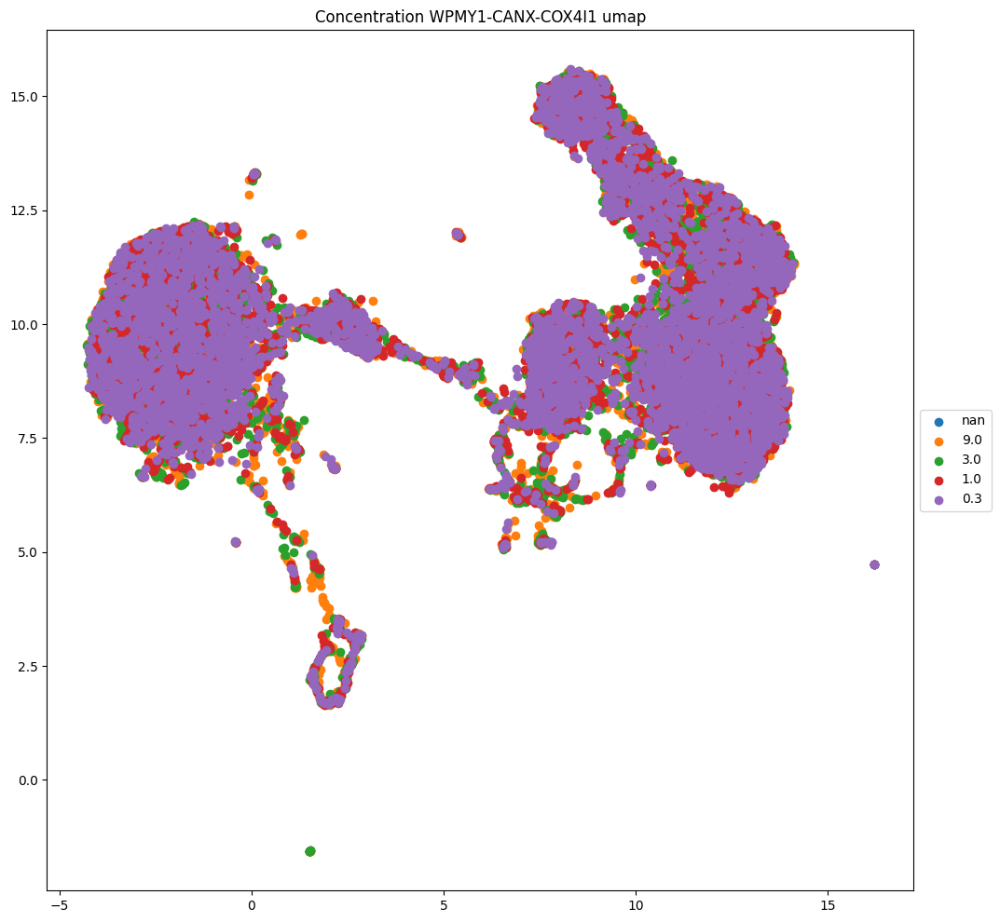

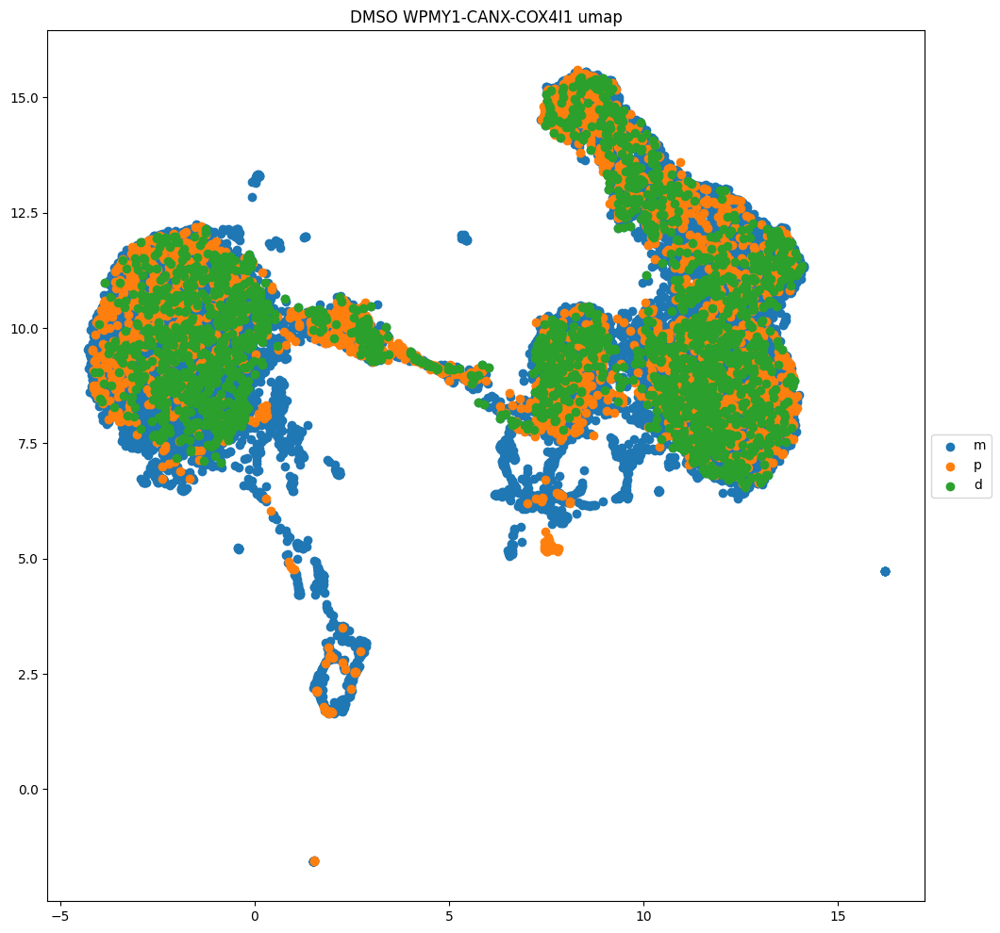

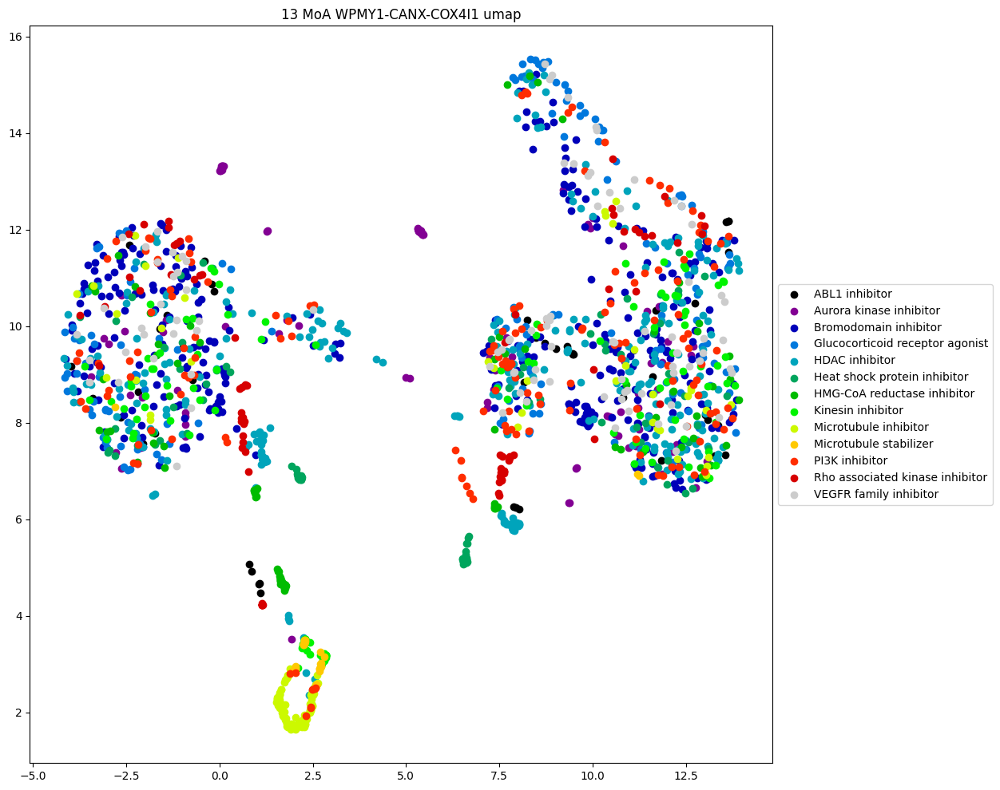

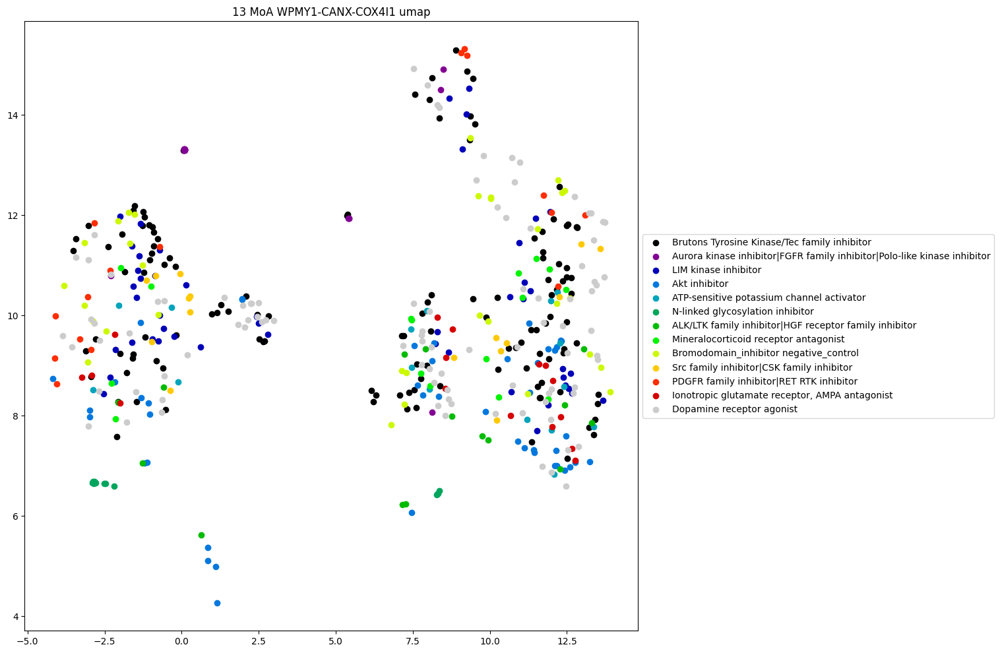

In [ ]:
for c in ['A549-ACTB-RAB5A', 'A549-GM130-SQSTM1', 'HepG2-TUBA1B-RELA', 'HepG2-TP53BP1-CLTA', 'WPMY1-TUBA1B-RELA', 'WPMY1-CANX-COX4I1']:
  for j in ['pca','tsne','tsnep','tsnec','umap']:
    df_A549 = X[X['Comment [Cell Line with Markers]']==c]
    scaler = StandardScaler()
    Xs = scaler.fit_transform(df_A549[df_A549.columns[4:979]])
    if(j=='pca'):
      pca = PCA(n_components=2)  # Specify the number of principal components to keep
      X_pca = pca.fit_transform(Xs)
      df = X_pca
    elif(j=='tsne'):
      tsne = TSNE(n_components=2, random_state=42)
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='tsnep'):
      tsne = TSNE(n_components=2, random_state=42, perplexity=50)
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='tsnec'):
      tsne = TSNE(n_components=2, random_state=42, metric='correlation')
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='umap'):
      umap = UMAP(n_components=2, random_state=42)
      X_umap = umap.fit_transform(Xs)
      df = X_umap
    plt.figure(figsize=(12, 12))
    plt.title('Concentration '+c+' '+j)
    for i in df_A549['Compound Concentration (microMolar)'].unique():
      plt.scatter(df[df_A549['Compound Concentration (microMolar)']==i,0], df[df_A549['Compound Concentration (microMolar)']==i,1], label = i)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()
    plt.figure(figsize=(12, 12))
    plt.title('DMSO '+c+' '+j)
    plt.scatter(df[df_A549['Compound Set']!='Prestwick Natural Product',0], df[df_A549['Compound Set']!='Prestwick Natural Product',1], label = 'm')
    plt.scatter(df[df_A549['Compound Set']=='Prestwick Natural Product',0], df[df_A549['Compound Set']=='Prestwick Natural Product',1], label = 'p')
    plt.scatter(df[df_A549['Compound Name']=='DMSO',0], df[df_A549['Compound Name']=='DMSO',1], label = 'd')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()
    plt.figure(figsize=(12, 12))
    plt.title('13 MoA '+c+' '+j)
    moa_list = ['ABL1 inhibitor', 'Aurora kinase inhibitor', 'Bromodomain inhibitor', 'Glucocorticoid receptor agonist', 'HDAC inhibitor', 'Heat shock protein inhibitor',
            'HMG-CoA reductase inhibitor', 'Kinesin inhibitor', 'Microtubule inhibitor', 'Microtubule stabilizer', 'PI3K inhibitor',
            'Rho associated kinase inhibitor', 'VEGFR family inhibitor']
    colormap = plt.cm.nipy_spectral
    colors = colormap(np.linspace(0, 1, 13))
    plt.gca().set_prop_cycle('color',colors)
    for i in moa_list:
      plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = i)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()
    plt.figure(figsize=(12, 12))
    plt.title('13 MoA '+c+' '+j)
    moa_list = list(np.random.choice(df_A549['Compound MoA'].unique(), size = 13, replace = False))
    colormap = plt.cm.nipy_spectral
    colors = colormap(np.linspace(0, 1, 13))
    plt.gca().set_prop_cycle('color',colors)
    for i in moa_list:
      plt.scatter(df[df_A549['Compound MoA']==i,0], df[df_A549['Compound MoA']==i,1], label = i)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

### KNN MoA

k = 50, training score = 0.2571360181916103, test score = 0.23575873623743418, cell line = A549-TUBA1B-RELA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


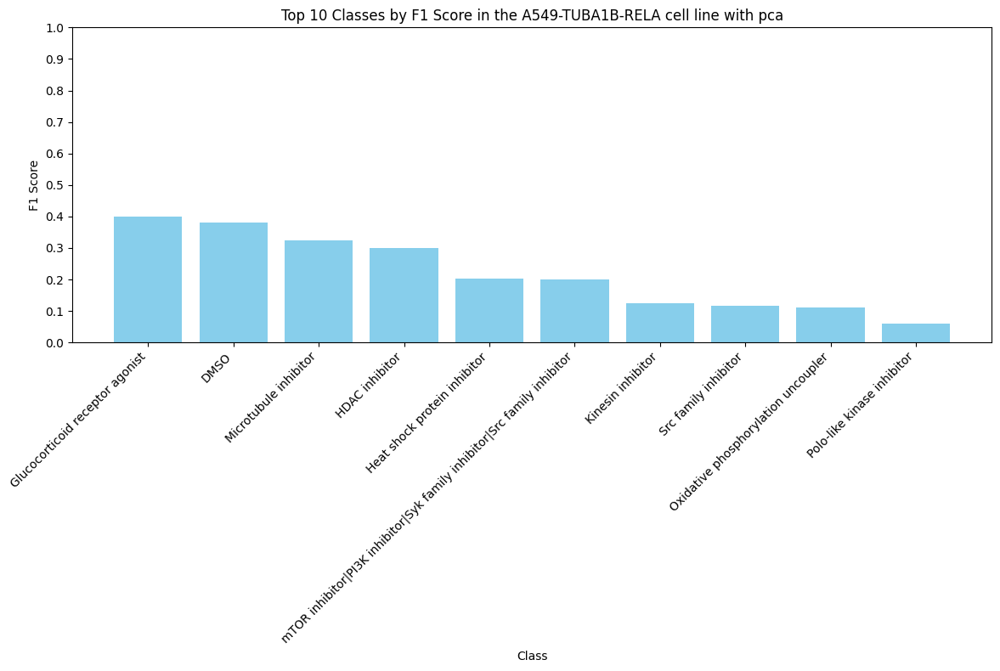

k = 50, training score = 0.29495541858655977, test score = 0.27381522259454283, cell line = A549-TUBA1B-RELA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


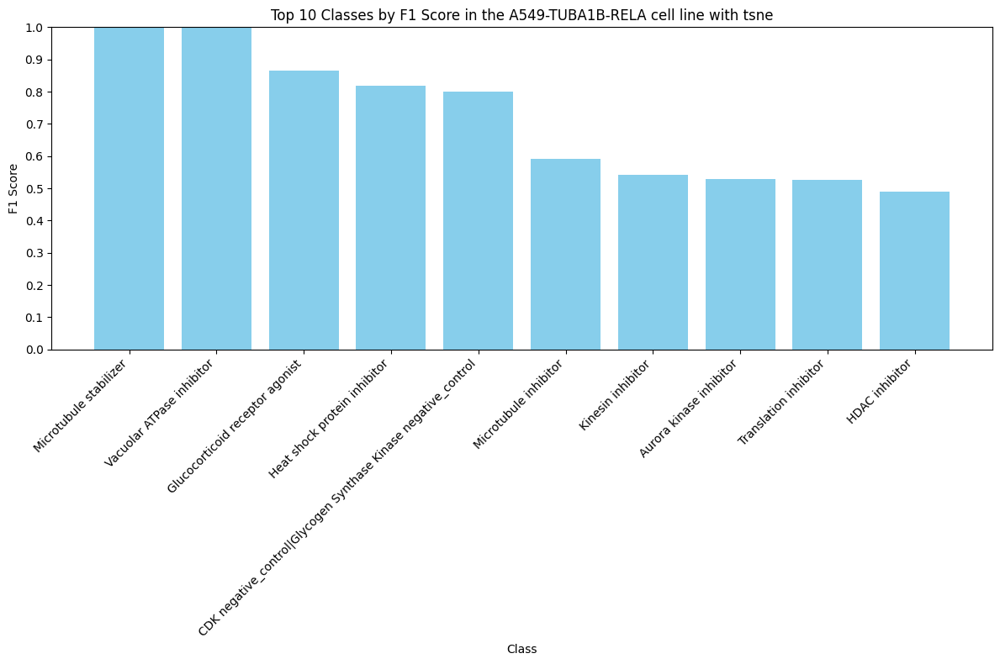

k = 50, training score = 0.29357907964813595, test score = 0.27190043082814747, cell line = A549-TUBA1B-RELA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


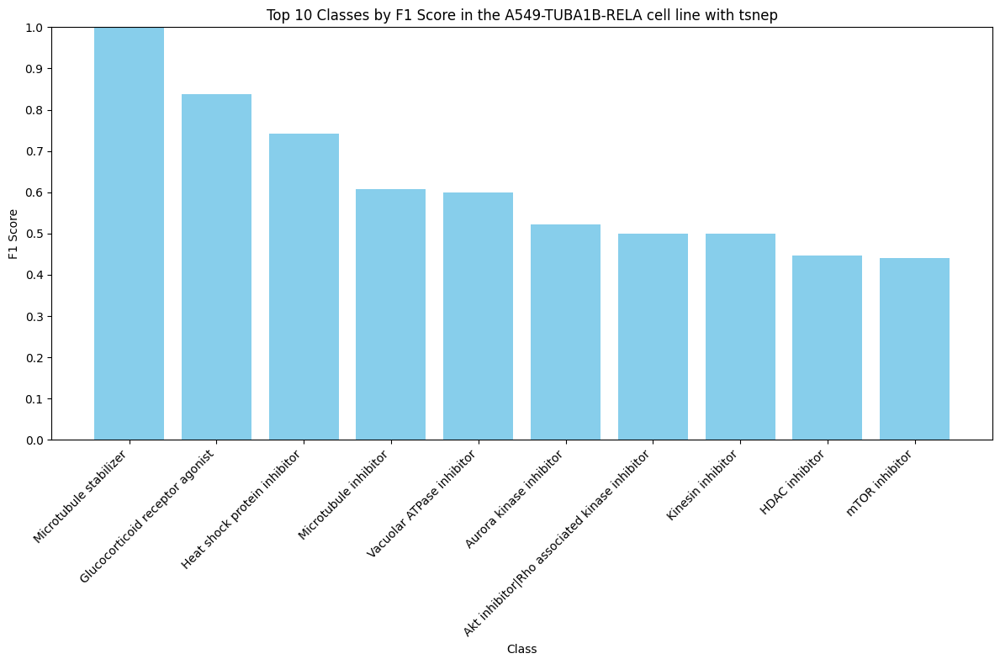

k = 50, training score = 0.29609239423134465, test score = 0.27740545715653425, cell line = A549-TUBA1B-RELA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


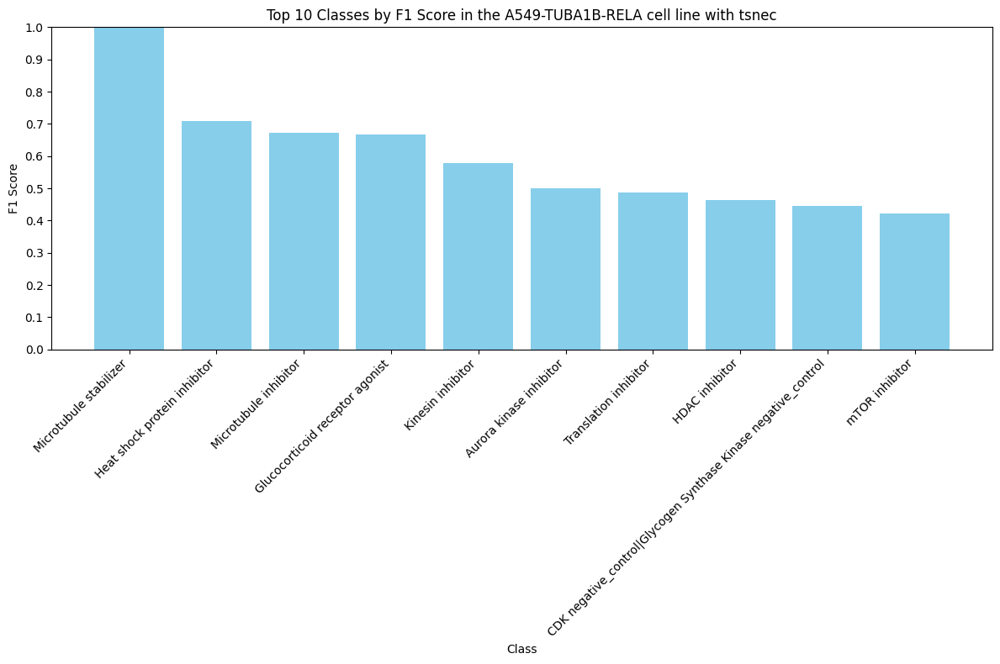

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.28939022200945486, test score = 0.26831019626615604, cell line = A549-TUBA1B-RELA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


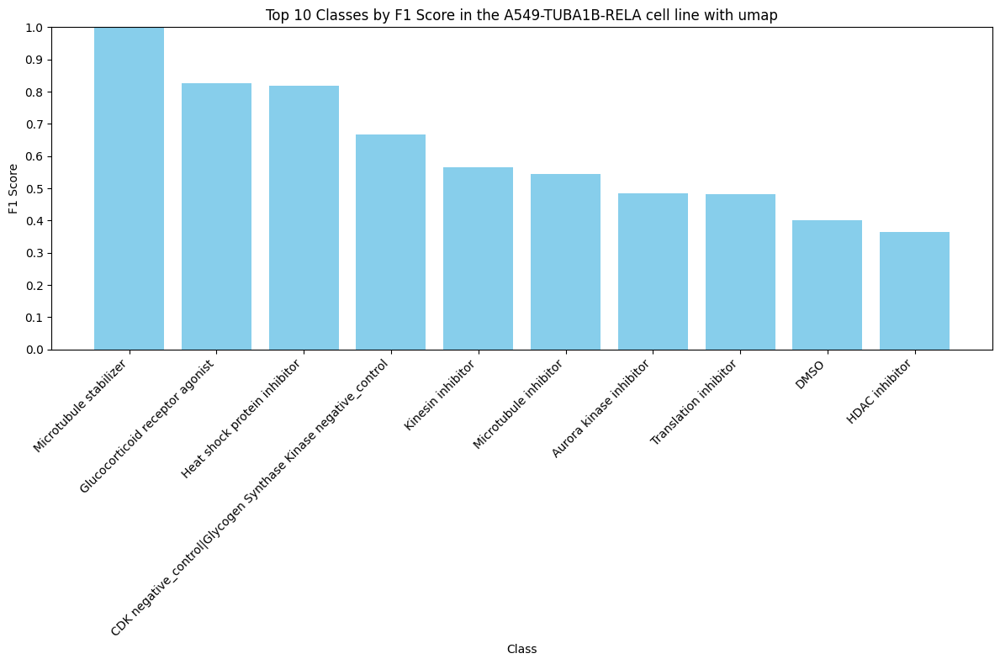

k = 50, training score = 0.2598109595597033, test score = 0.2502991146207227, cell line = A549-GM130-SQSTM1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


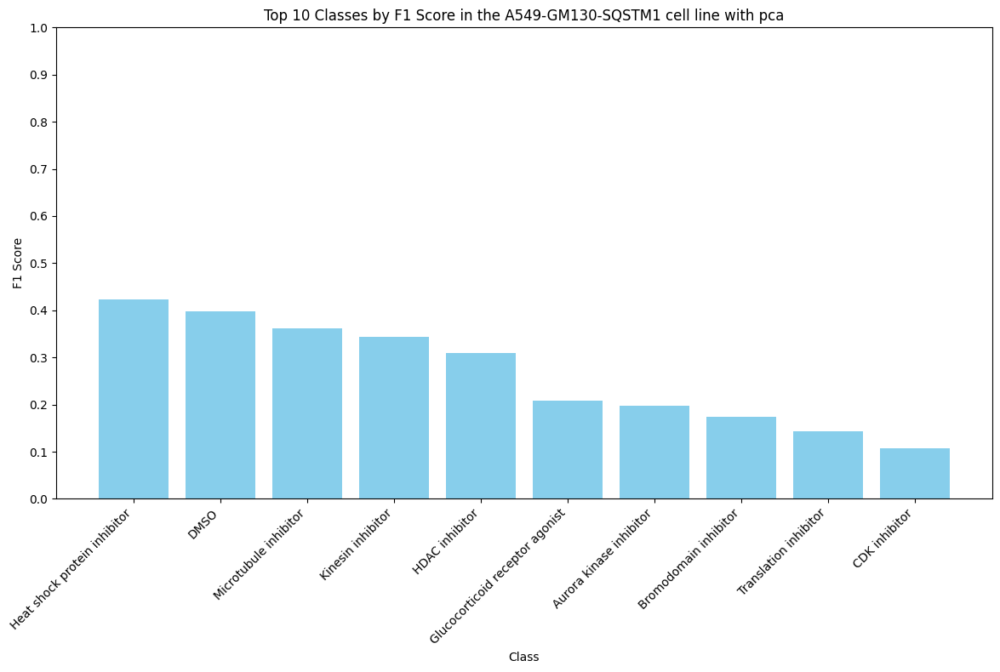

k = 50, training score = 0.2985163914812156, test score = 0.27949270160325435, cell line = A549-GM130-SQSTM1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


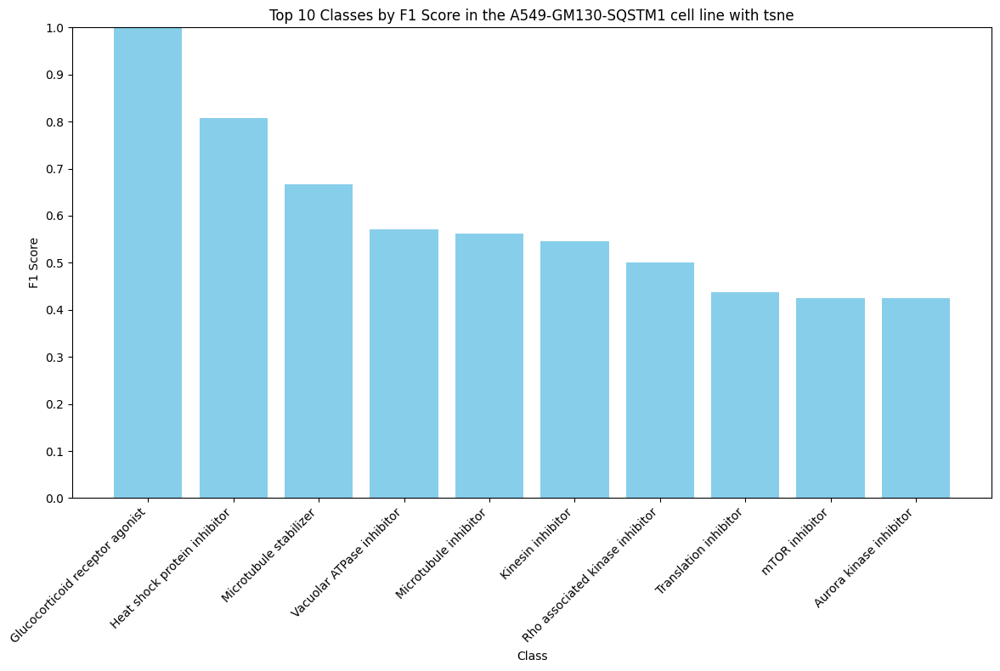

k = 50, training score = 0.29630294328786794, test score = 0.2782962431203637, cell line = A549-GM130-SQSTM1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


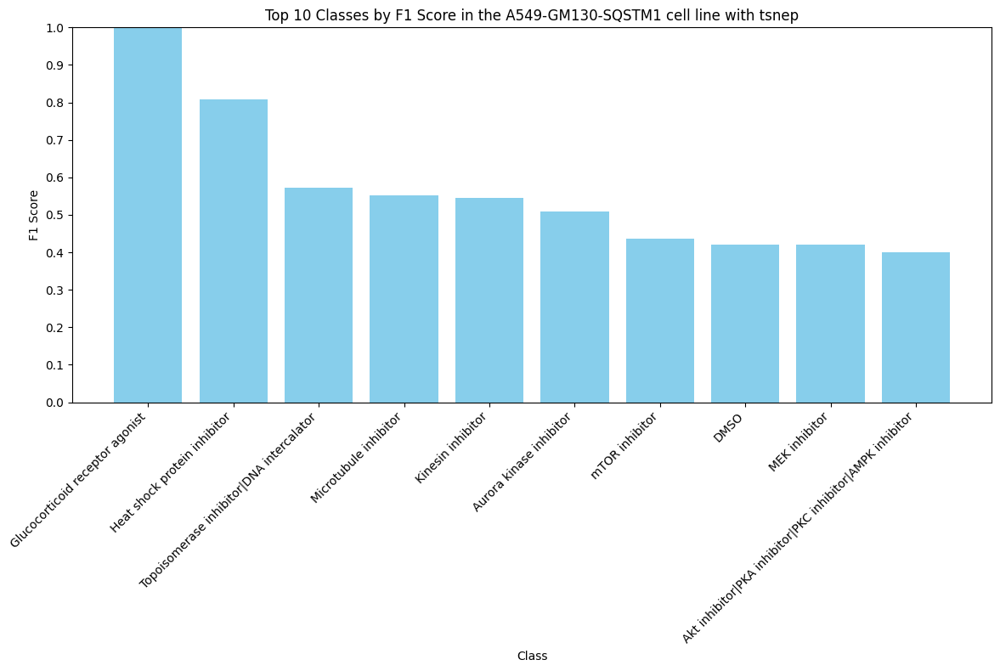

k = 50, training score = 0.30156736061258677, test score = 0.28523570232112944, cell line = A549-GM130-SQSTM1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


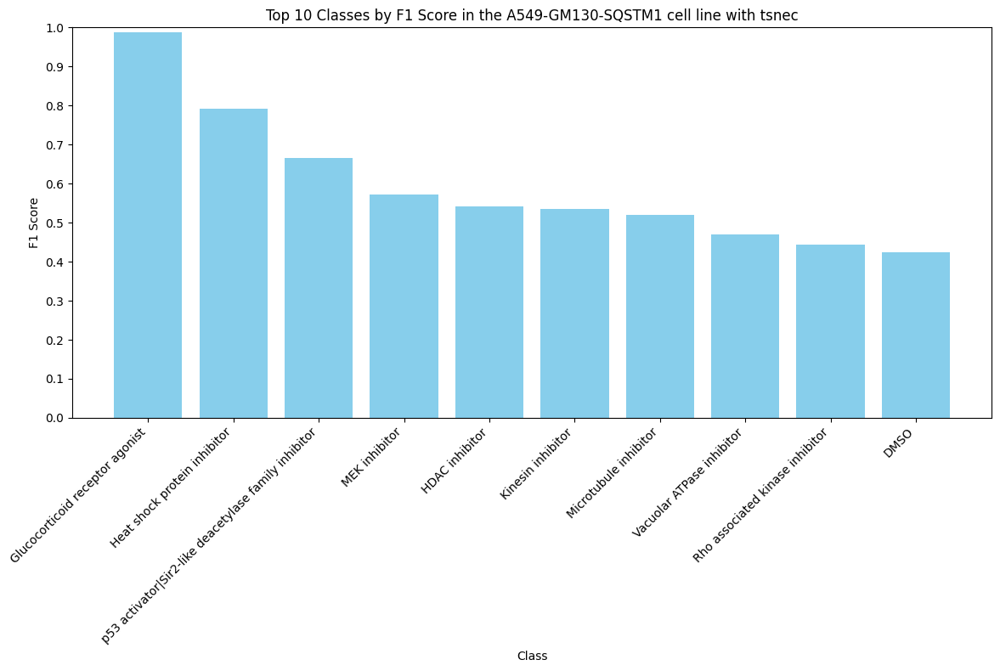

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2949270160325437, test score = 0.28164632687245755, cell line = A549-GM130-SQSTM1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


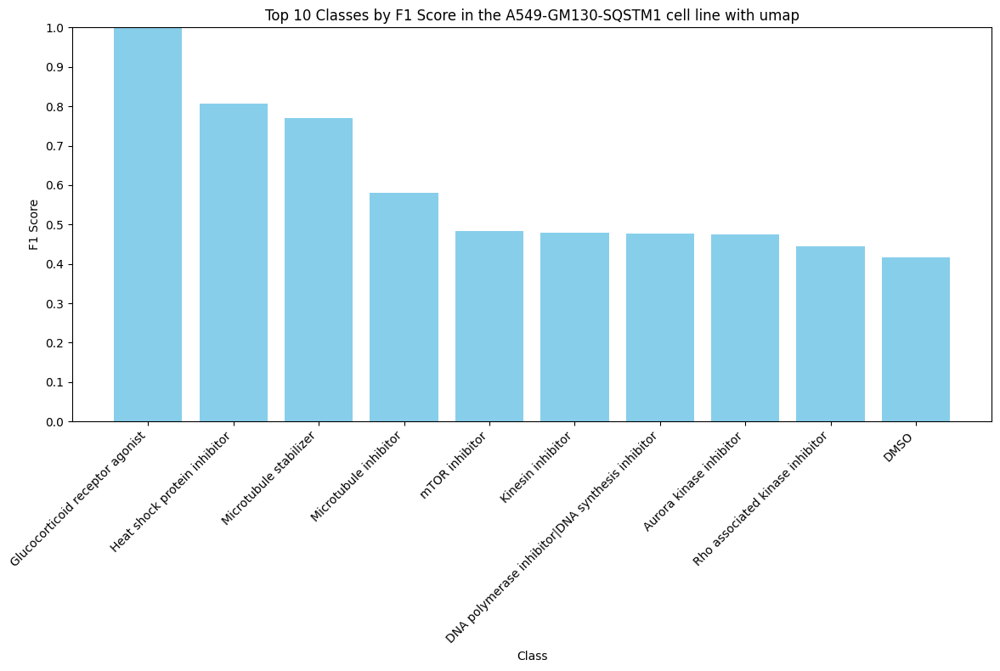

k = 50, training score = 0.26006340092110775, test score = 0.25813397129186605, cell line = A549-ACTB-RAB5A, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


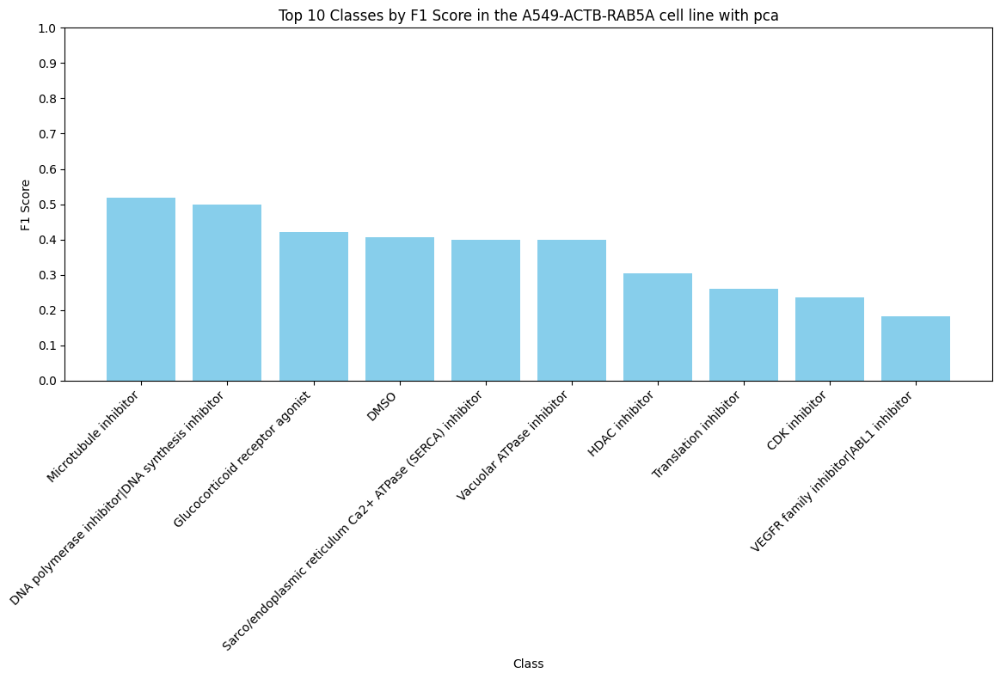

k = 50, training score = 0.3024104312458879, test score = 0.2971291866028708, cell line = A549-ACTB-RAB5A, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


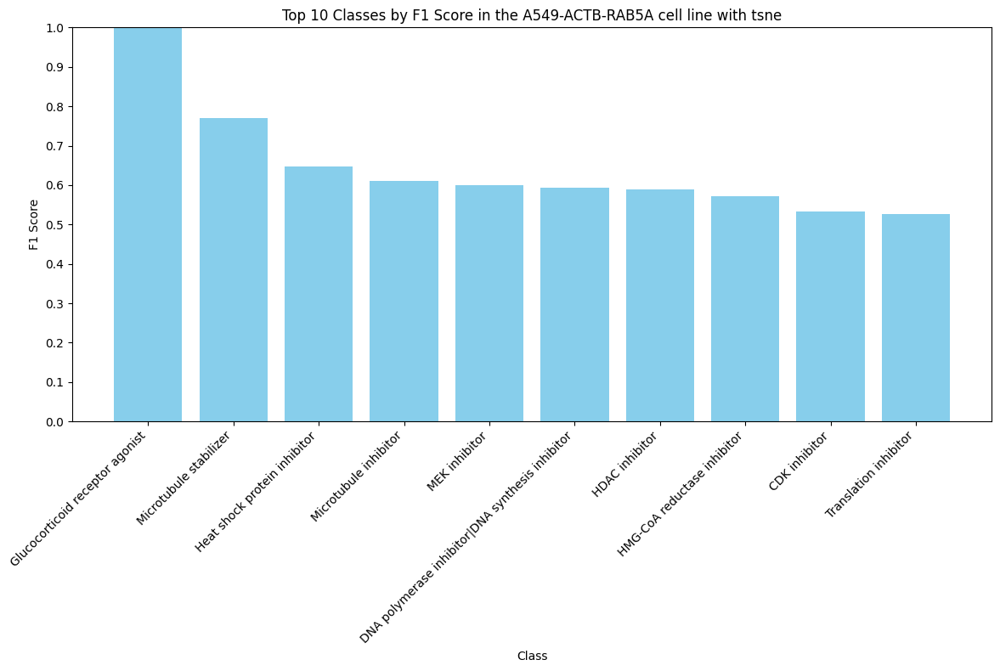

k = 50, training score = 0.302649680004785, test score = 0.29688995215311004, cell line = A549-ACTB-RAB5A, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


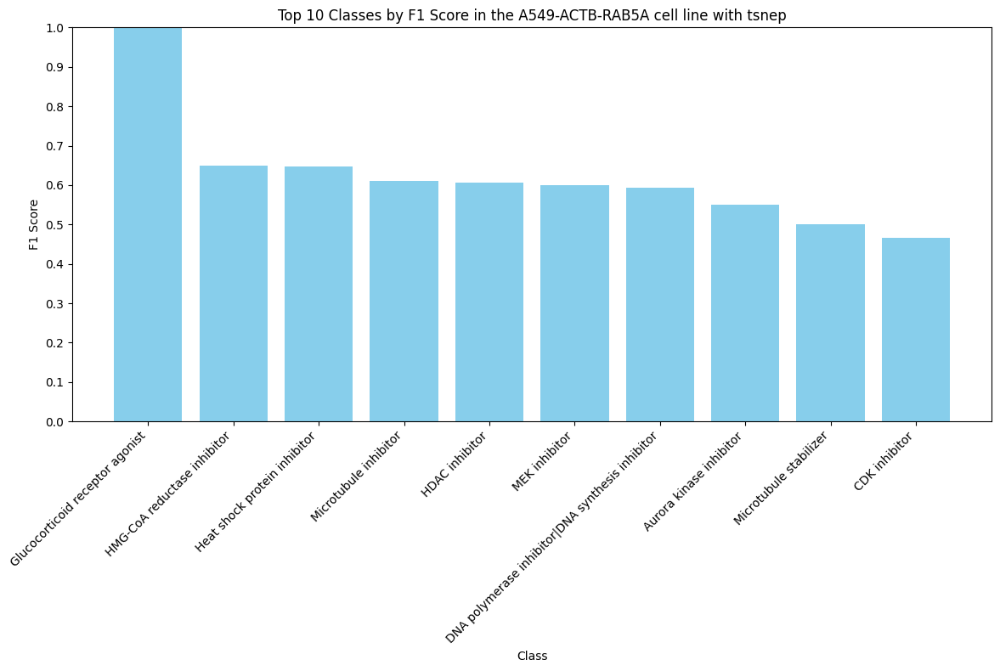

k = 50, training score = 0.31263831568873734, test score = 0.3066985645933014, cell line = A549-ACTB-RAB5A, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


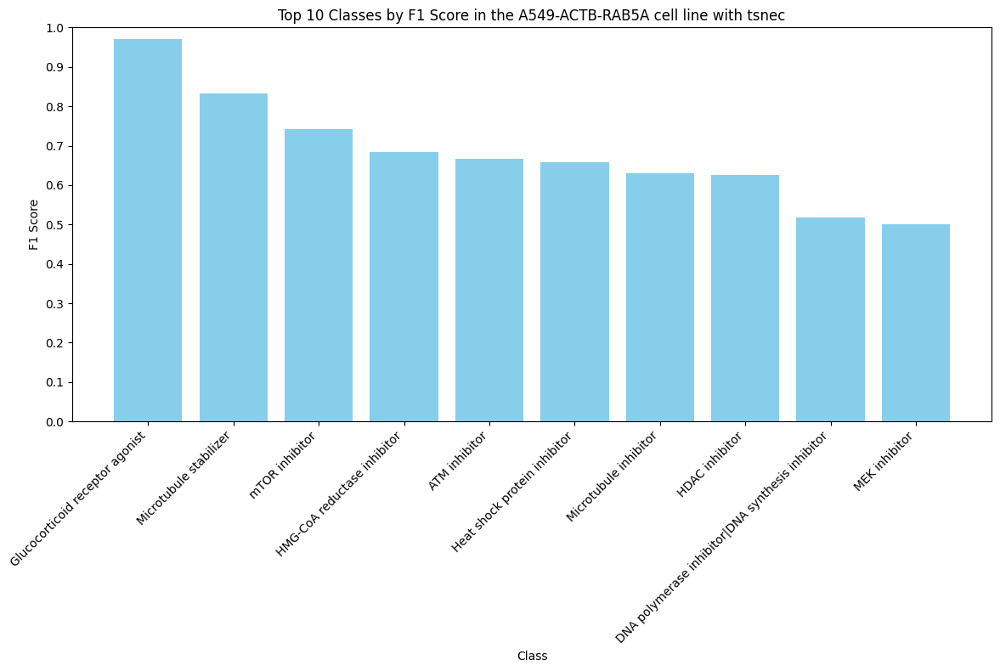

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.3027693043842335, test score = 0.2976076555023923, cell line = A549-ACTB-RAB5A, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


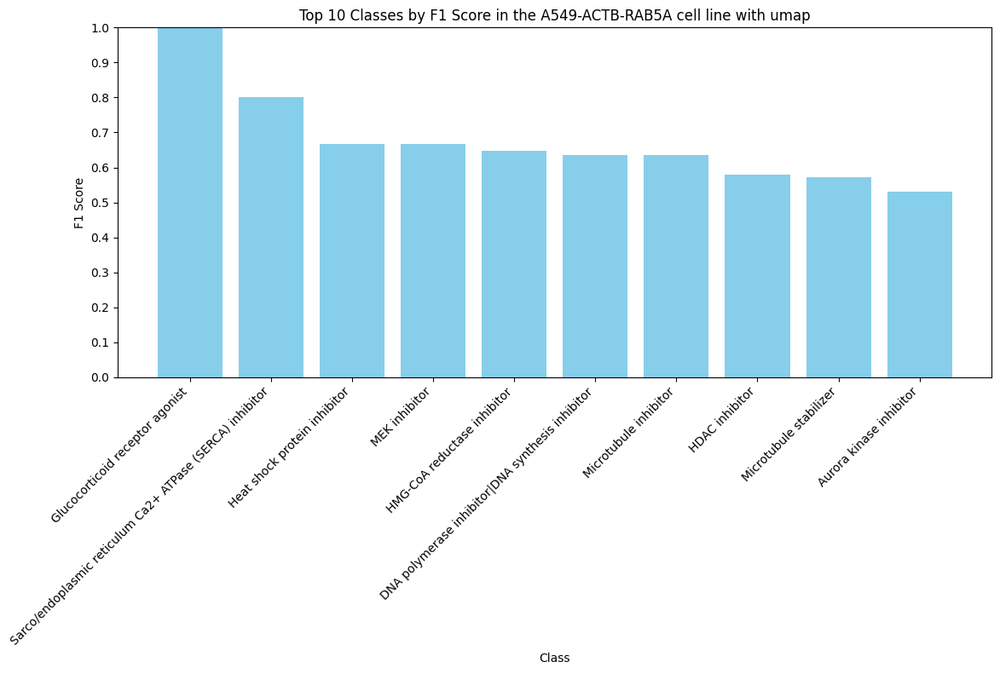

k = 50, training score = 0.2514461315979754, test score = 0.26126777536755846, cell line = HepG2-TP53BP1-CLTA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


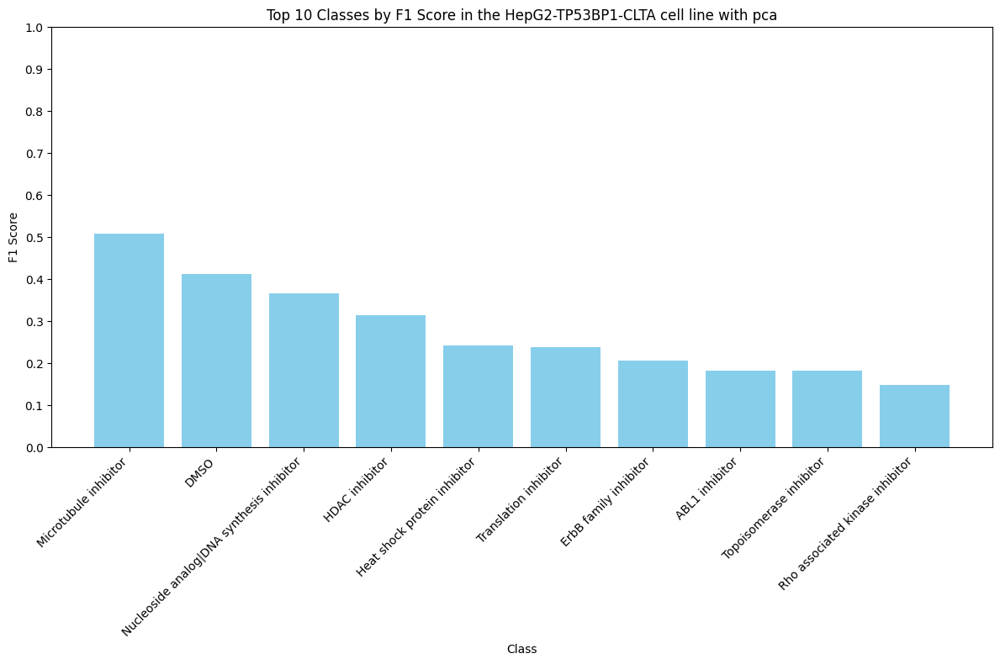

k = 50, training score = 0.28422511448541815, test score = 0.284646902868161, cell line = HepG2-TP53BP1-CLTA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


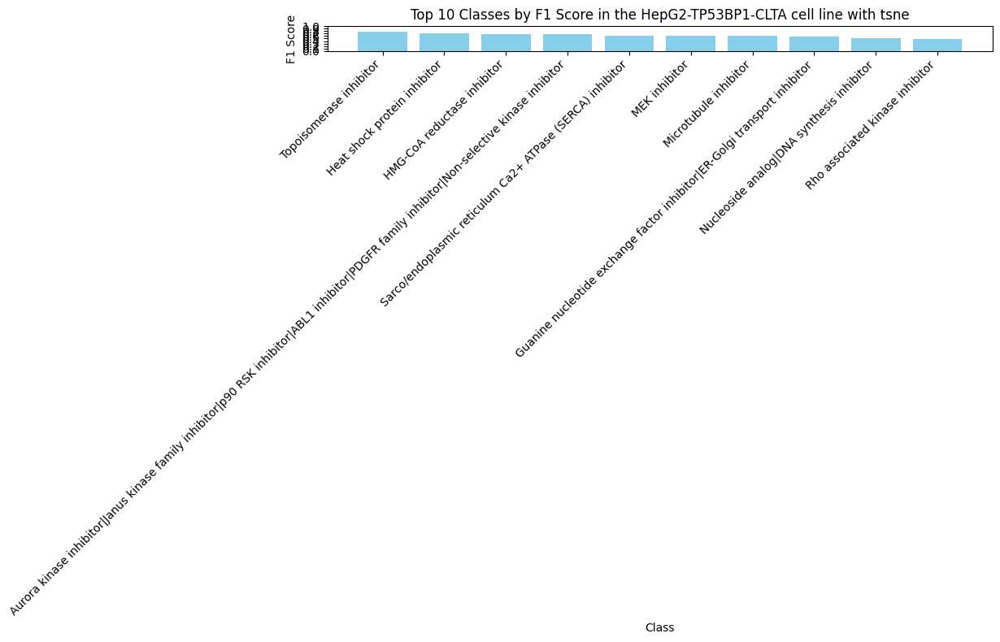

k = 50, training score = 0.28530971318389975, test score = 0.2827187274041938, cell line = HepG2-TP53BP1-CLTA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


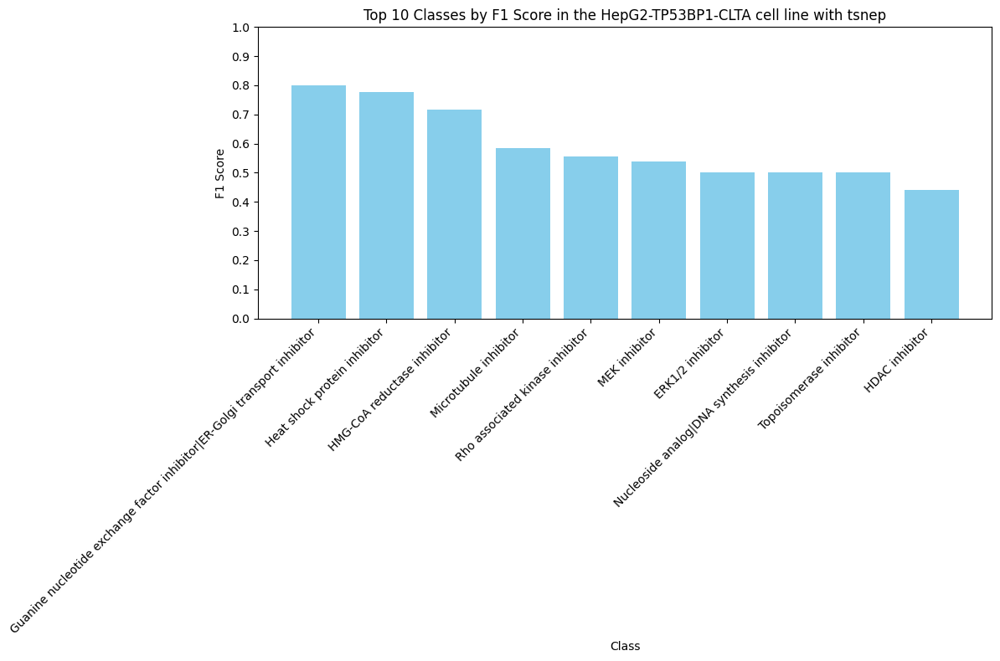

k = 50, training score = 0.2900698963605688, test score = 0.28922631959508316, cell line = HepG2-TP53BP1-CLTA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


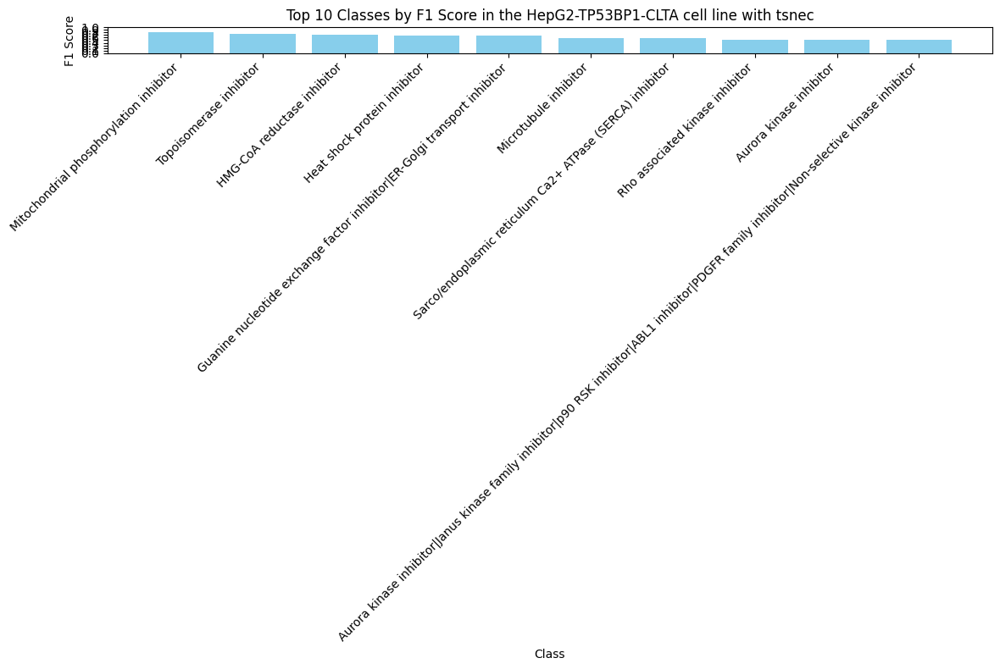

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.28030850807423474, test score = 0.2824777054711979, cell line = HepG2-TP53BP1-CLTA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


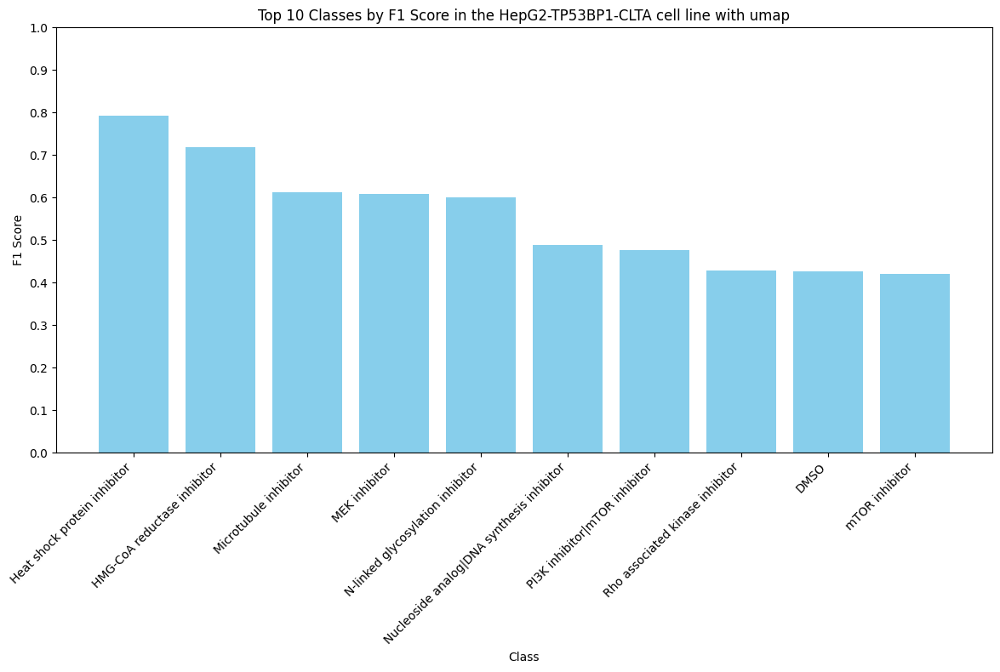

k = 50, training score = 0.251532982347476, test score = 0.23135992073321773, cell line = HepG2-TUBA1B-RELA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


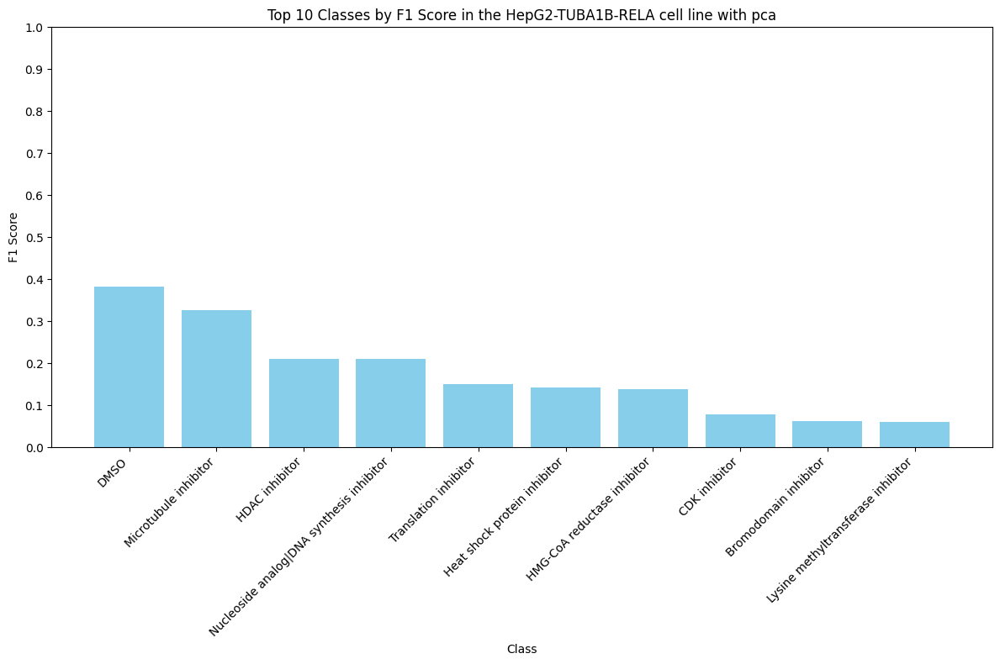

k = 50, training score = 0.2829978321461753, test score = 0.26034183799851374, cell line = HepG2-TUBA1B-RELA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


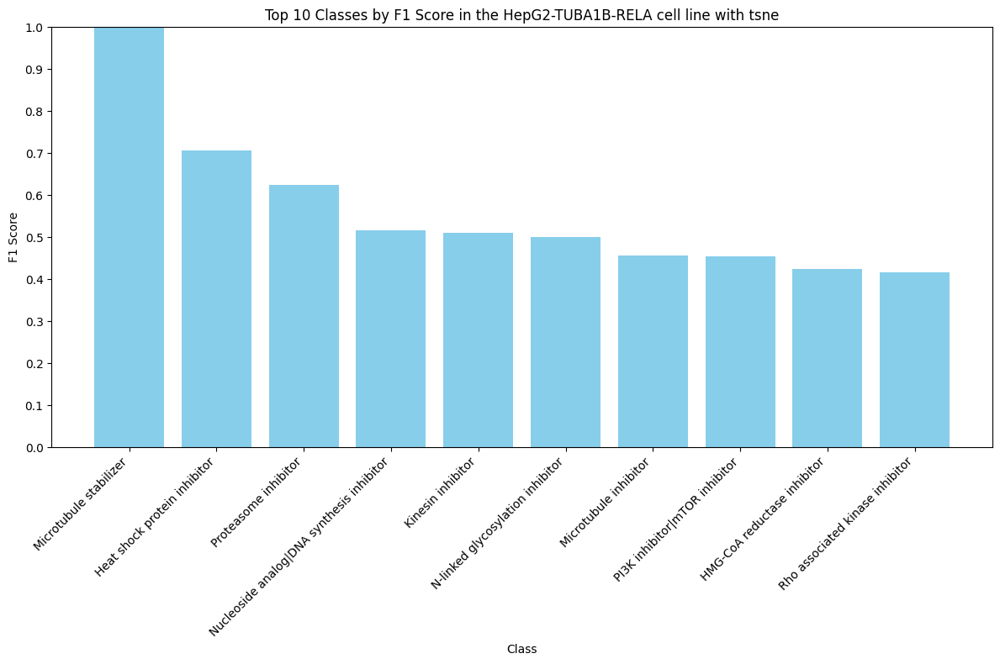

k = 50, training score = 0.28237844533911427, test score = 0.25811245974733715, cell line = HepG2-TUBA1B-RELA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


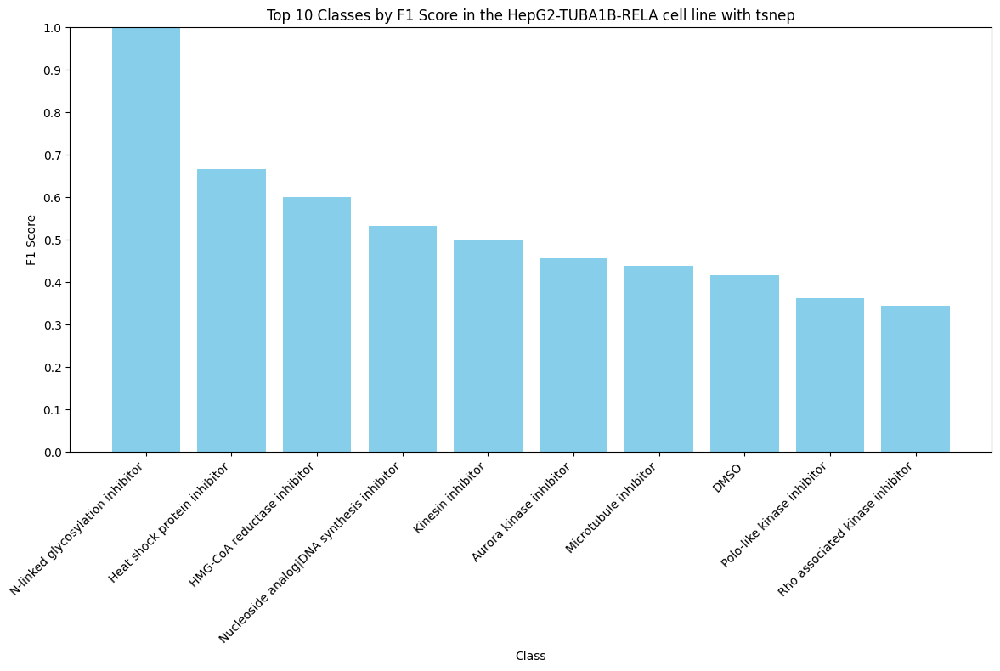

k = 50, training score = 0.2856611954165376, test score = 0.26529601189001734, cell line = HepG2-TUBA1B-RELA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


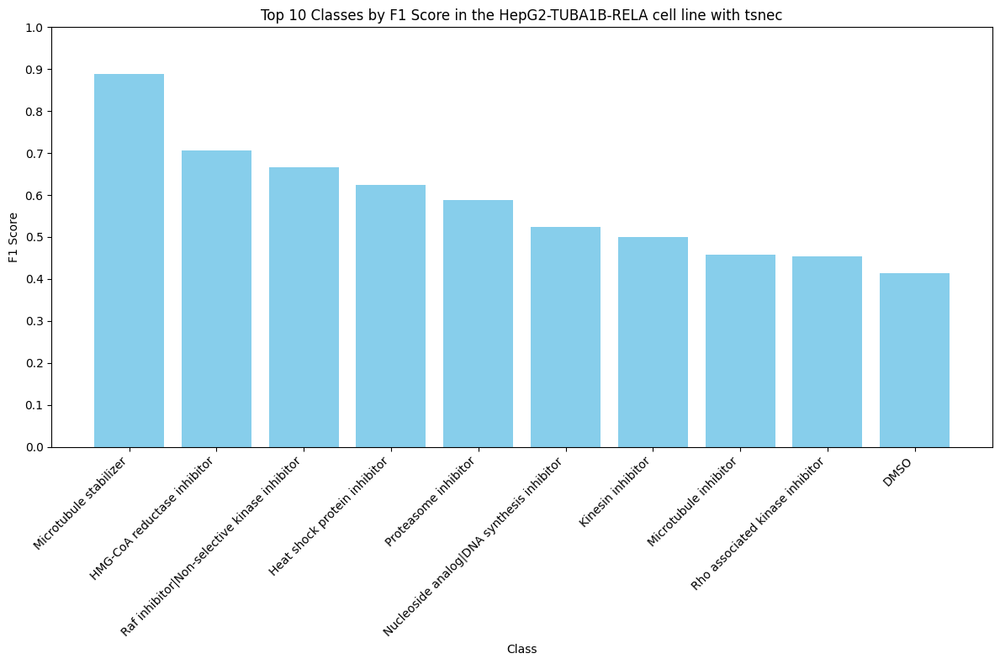

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2775472282440384, test score = 0.2583601684419123, cell line = HepG2-TUBA1B-RELA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


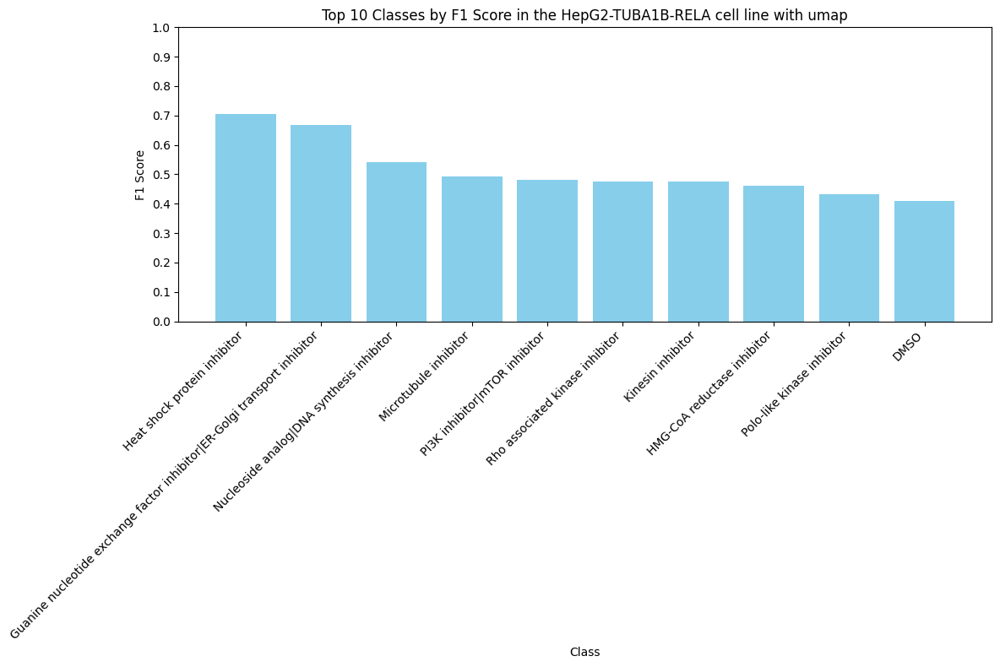

k = 50, training score = 0.24355055630272648, test score = 0.24987775061124695, cell line = WPMY1-TUBA1B-RELA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


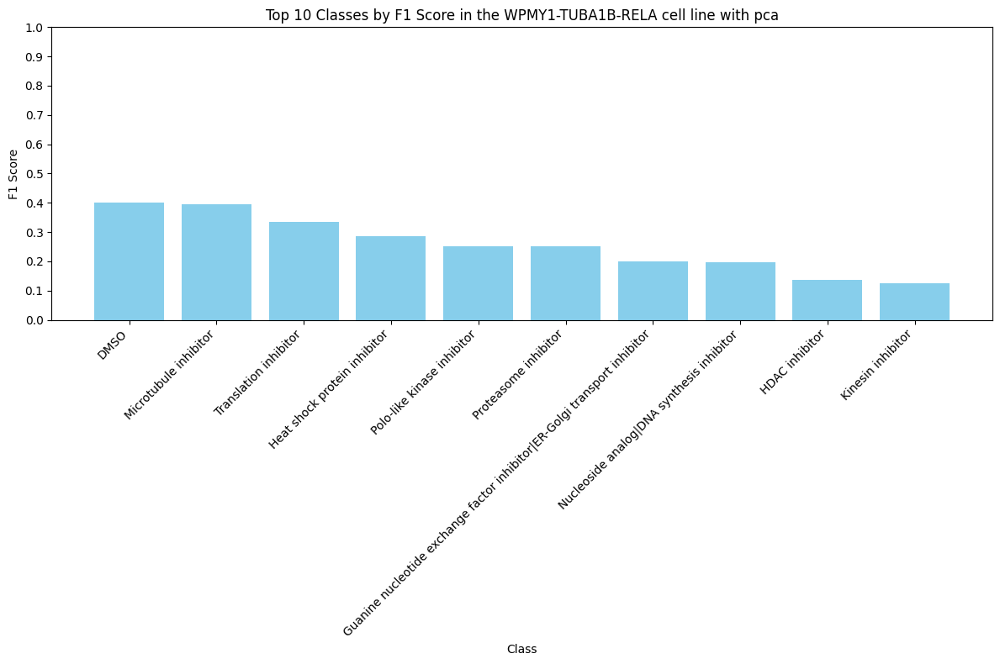

k = 50, training score = 0.28181929331214084, test score = 0.2809290953545232, cell line = WPMY1-TUBA1B-RELA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


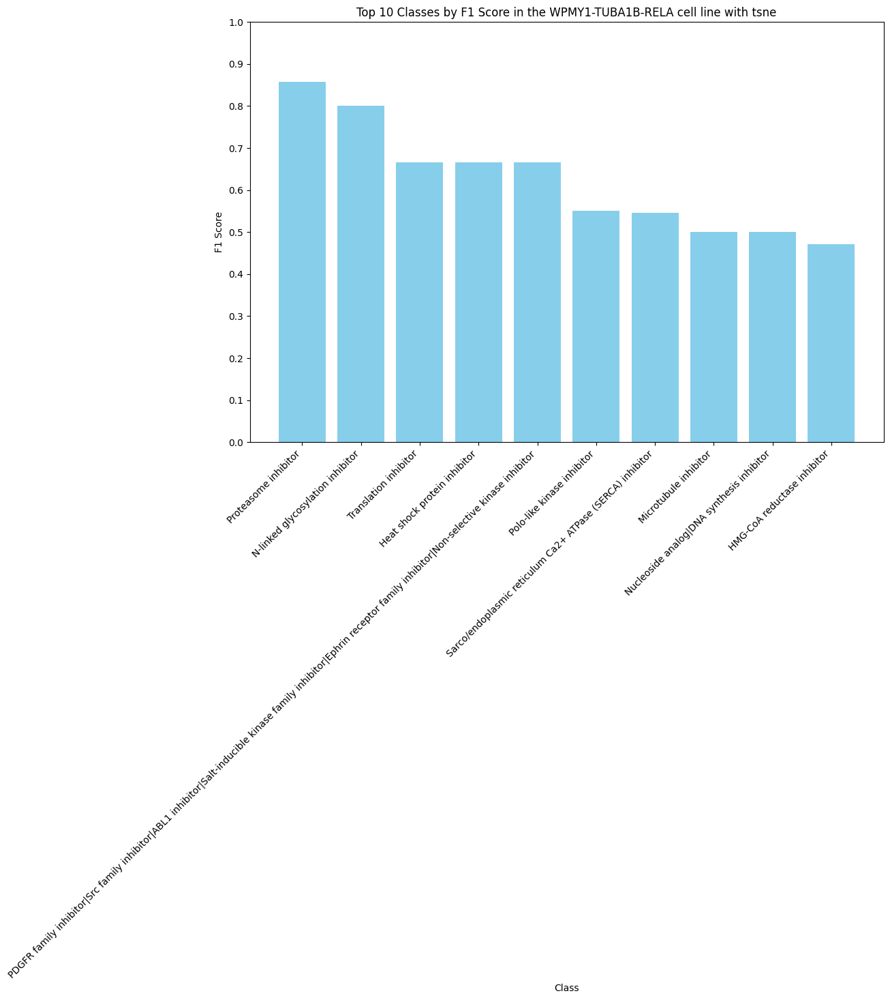

k = 50, training score = 0.2791906100990341, test score = 0.2792176039119804, cell line = WPMY1-TUBA1B-RELA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


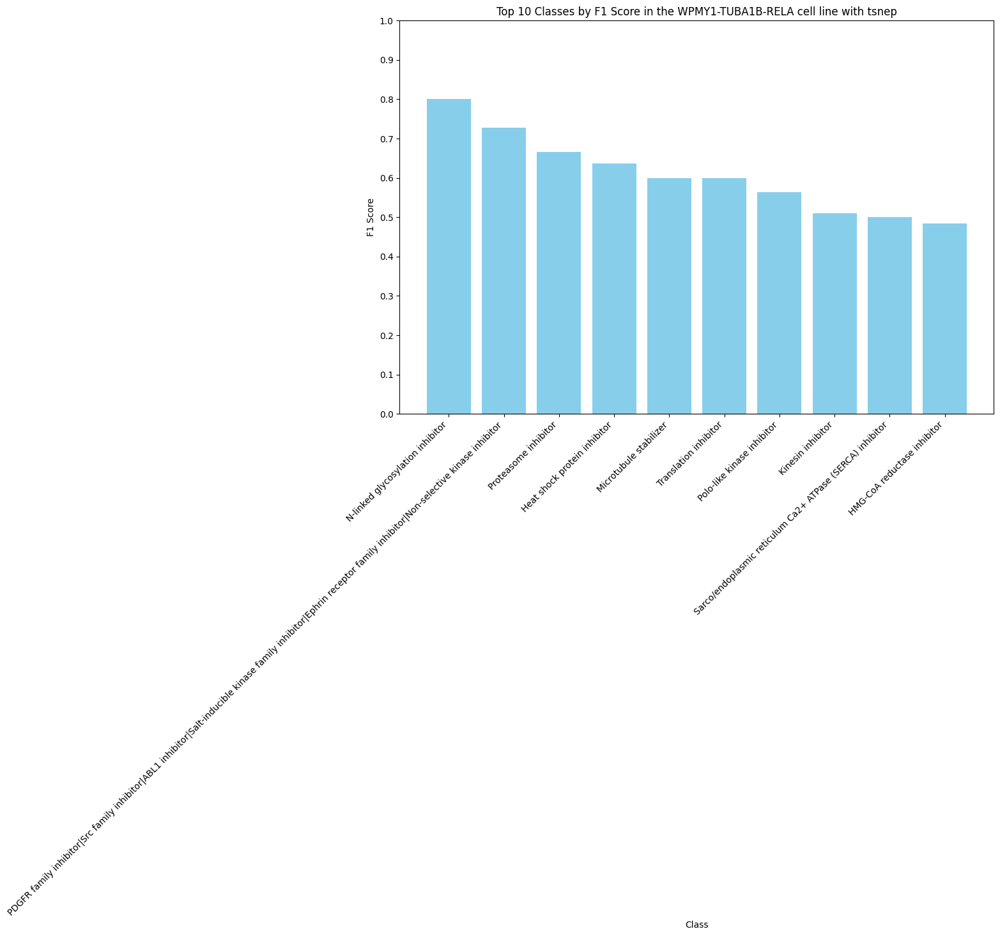

k = 50, training score = 0.2843257121897543, test score = 0.27188264058679706, cell line = WPMY1-TUBA1B-RELA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


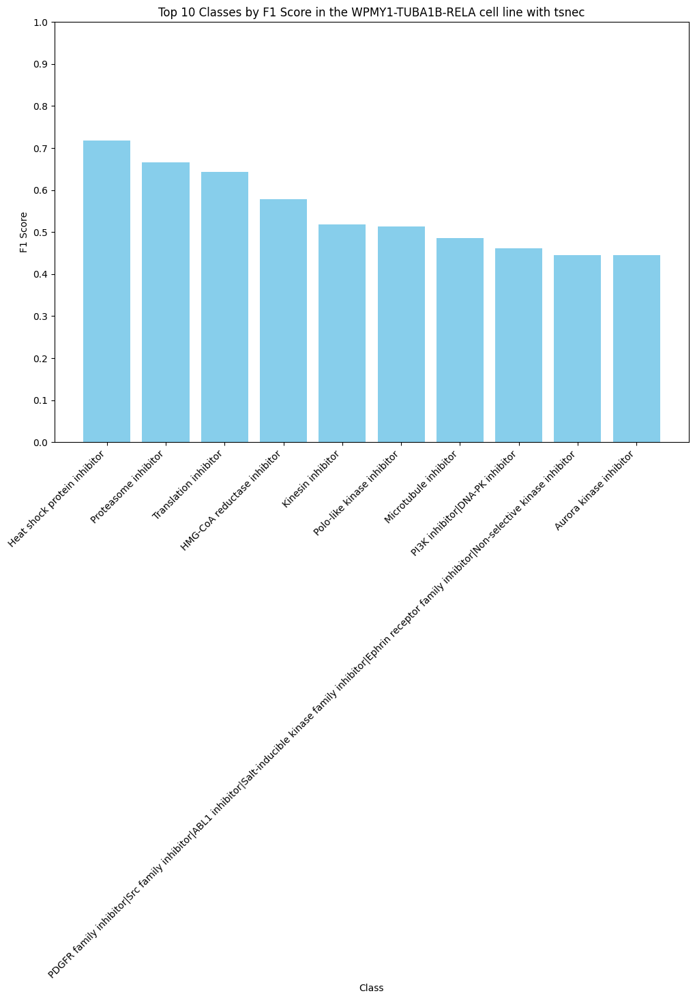

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2772343807311407, test score = 0.27726161369193153, cell line = WPMY1-TUBA1B-RELA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


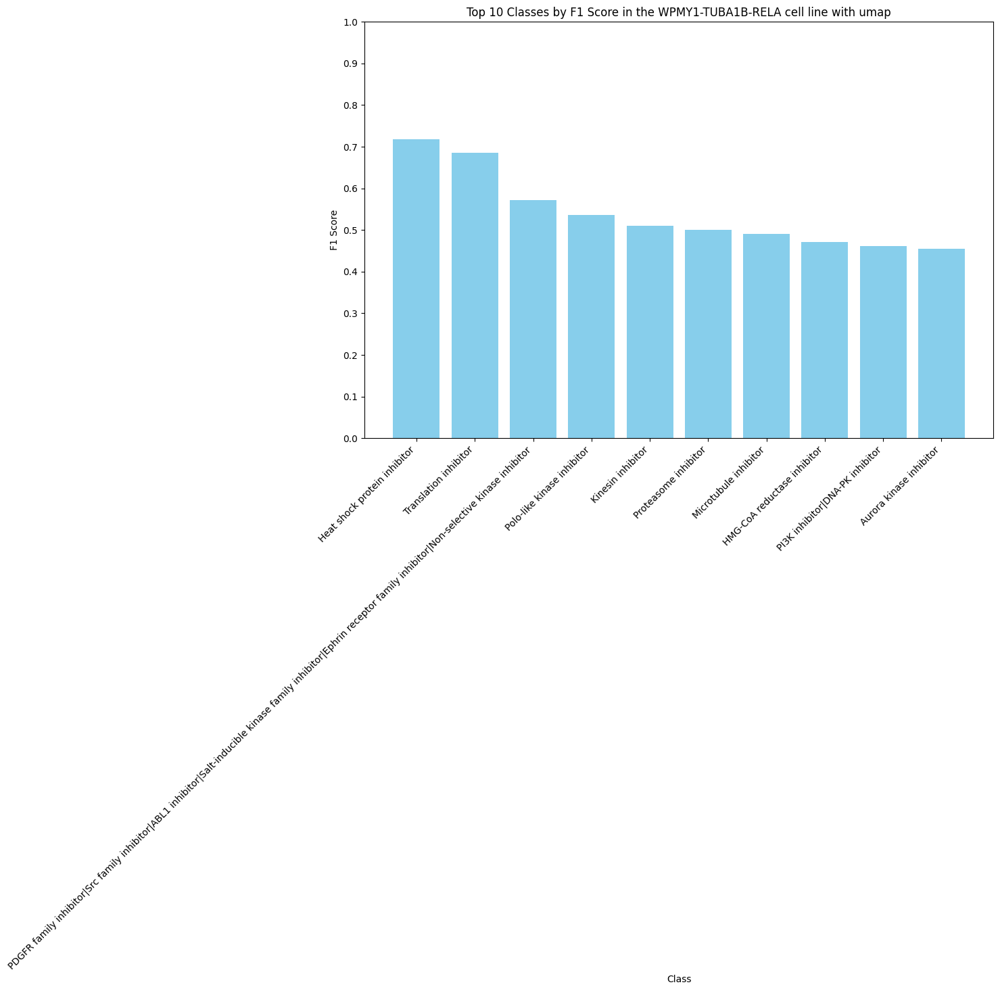

k = 50, training score = 0.2522739929459811, test score = 0.2534026231130908, cell line = WPMY1-TP53BP1-CLTA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


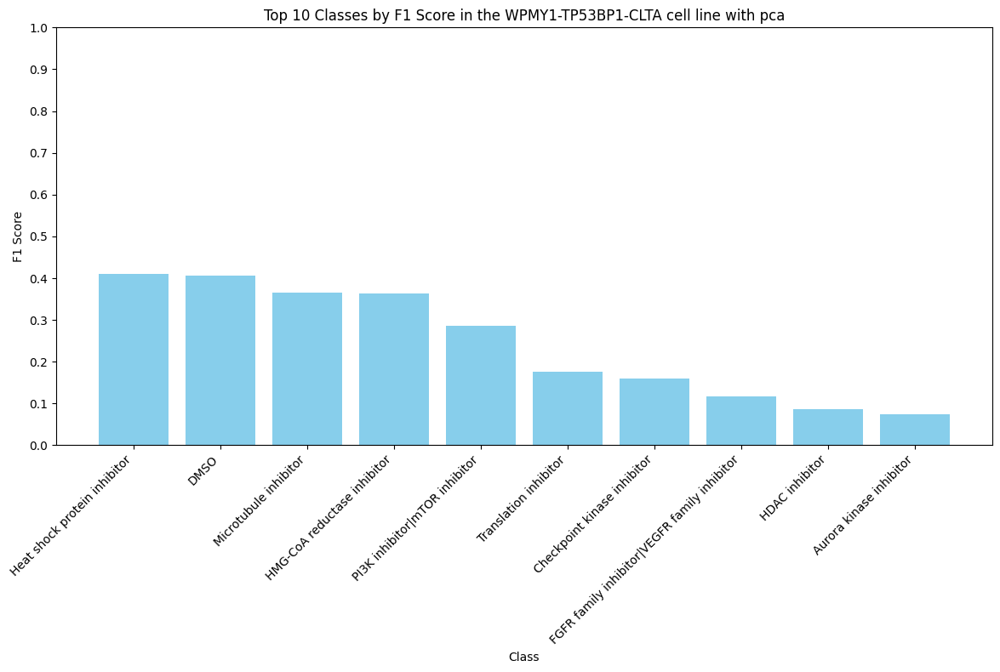

k = 50, training score = 0.2818513705835035, test score = 0.2798812175204157, cell line = WPMY1-TP53BP1-CLTA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


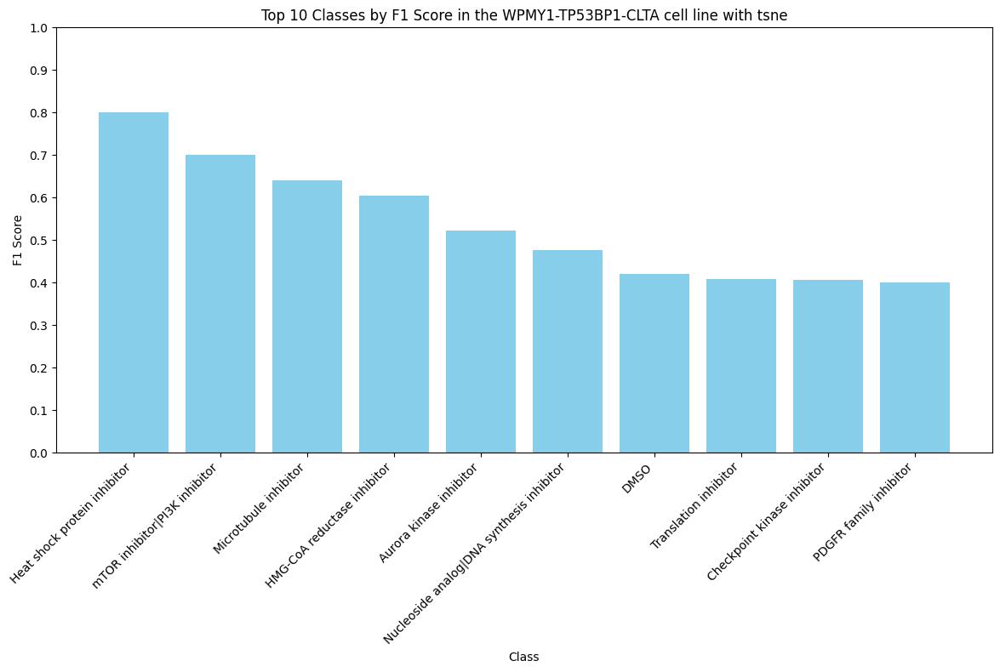

k = 50, training score = 0.2785718705525648, test score = 0.27715911902994306, cell line = WPMY1-TP53BP1-CLTA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


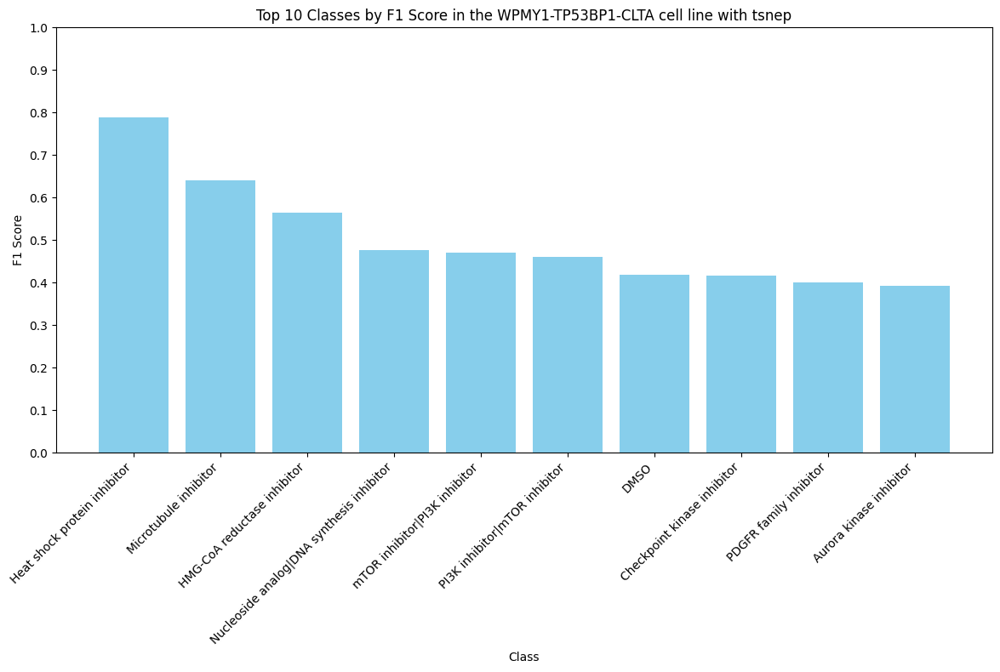

k = 50, training score = 0.2868015593094487, test score = 0.28433556050482556, cell line = WPMY1-TP53BP1-CLTA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


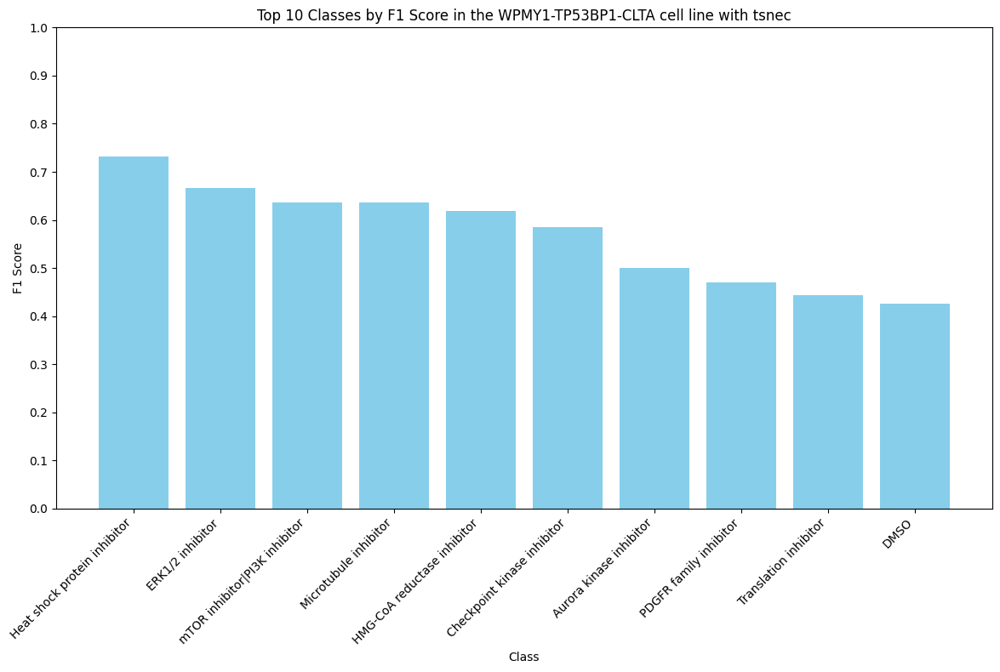

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2784481158344162, test score = 0.27864390002474637, cell line = WPMY1-TP53BP1-CLTA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


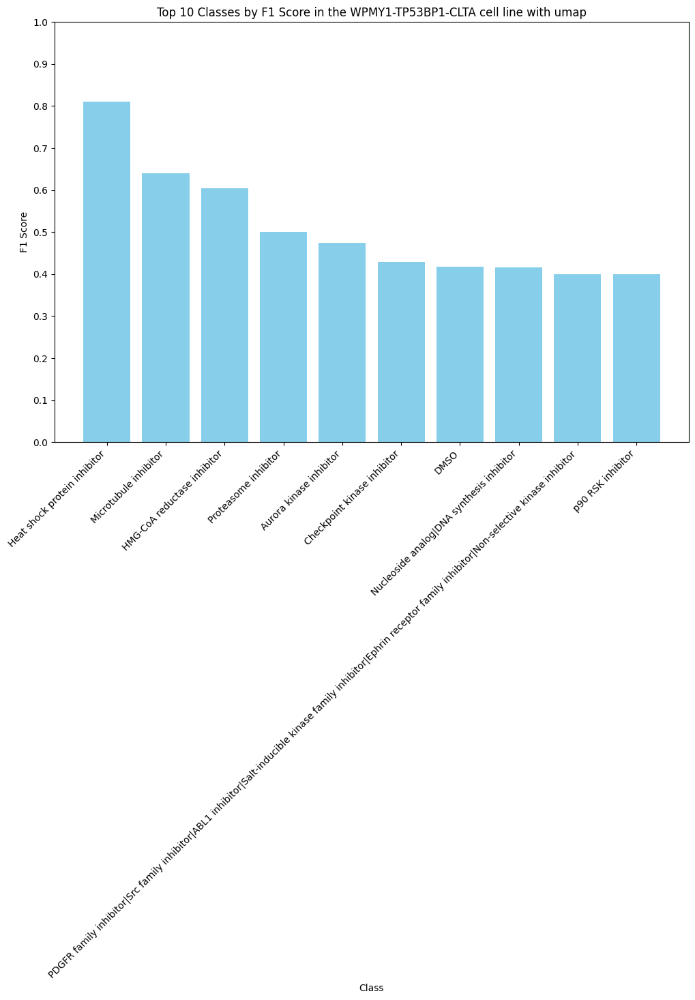

k = 50, training score = 0.2505953798523458, test score = 0.2338652060014289, cell line = WPMY1-GM130-SQSTM1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


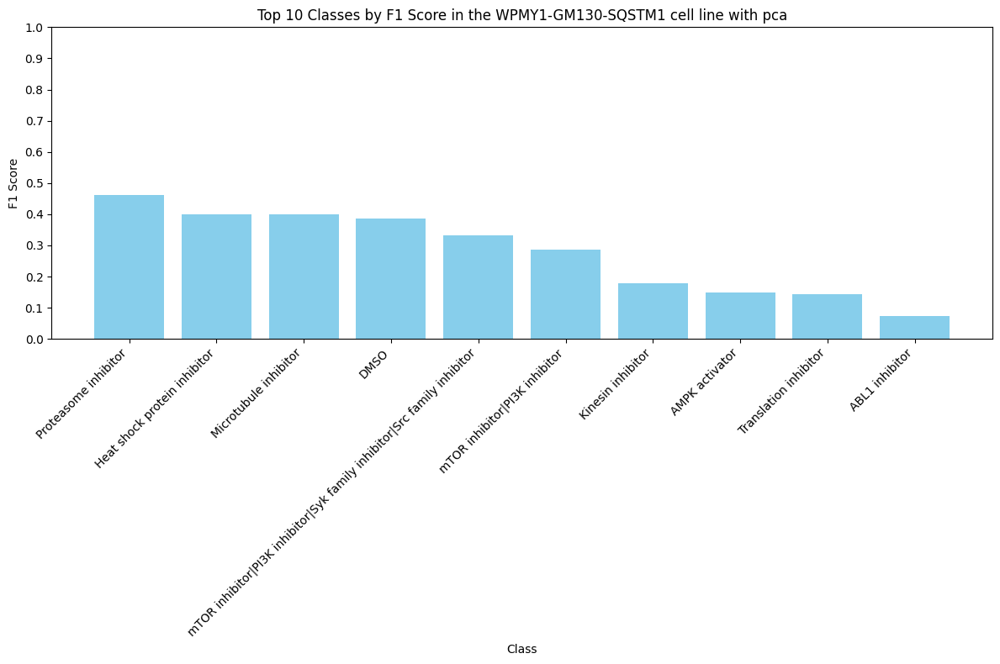

k = 50, training score = 0.27655394141462253, test score = 0.2576804000952608, cell line = WPMY1-GM130-SQSTM1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


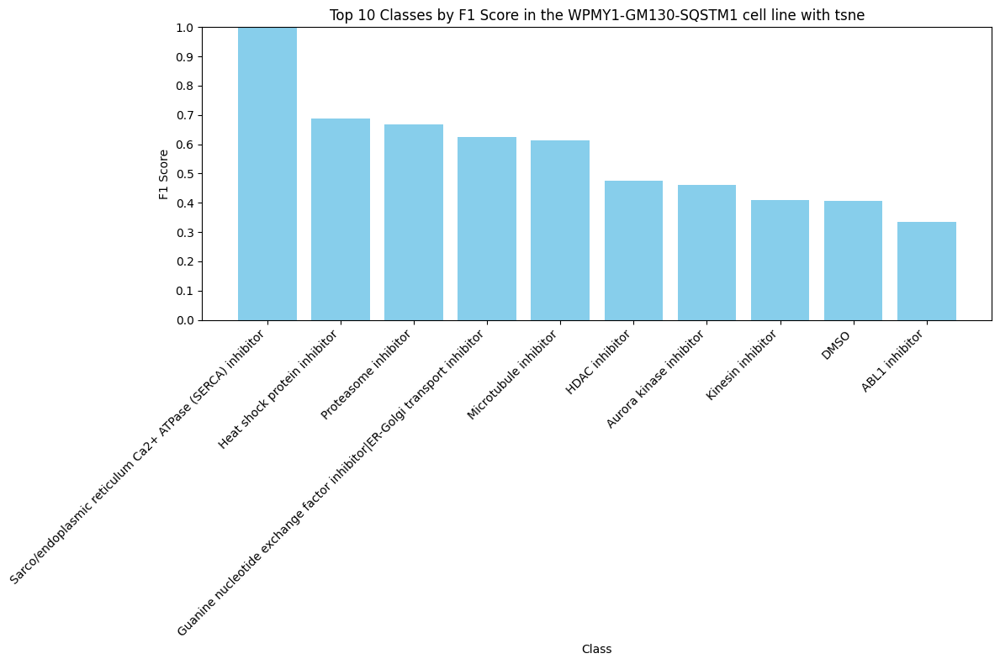

k = 50, training score = 0.2757204096213384, test score = 0.26030007144558226, cell line = WPMY1-GM130-SQSTM1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


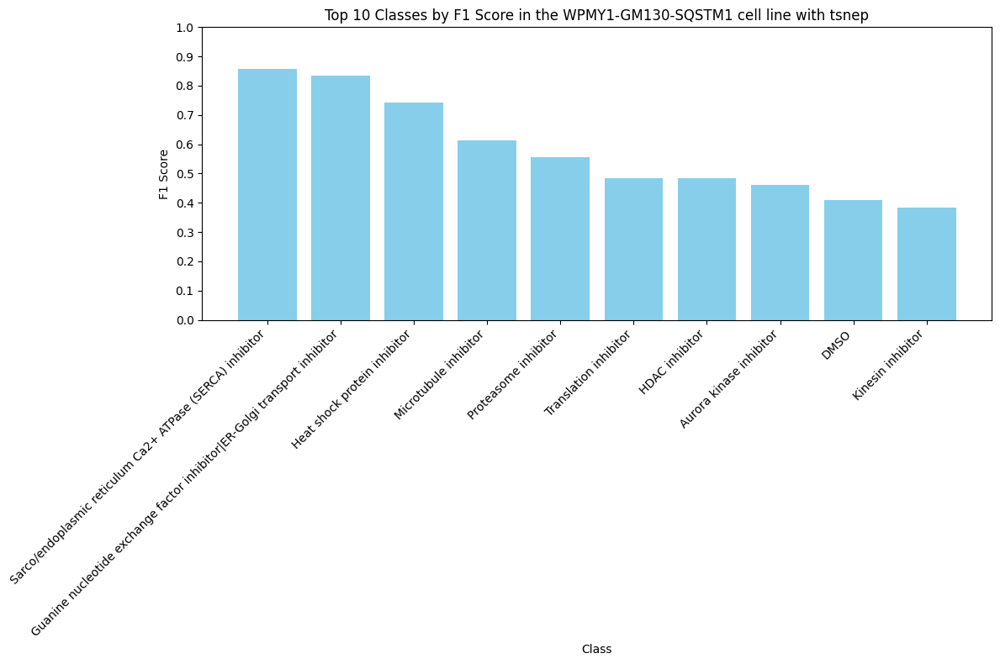

k = 50, training score = 0.2815551321743272, test score = 0.2631578947368421, cell line = WPMY1-GM130-SQSTM1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


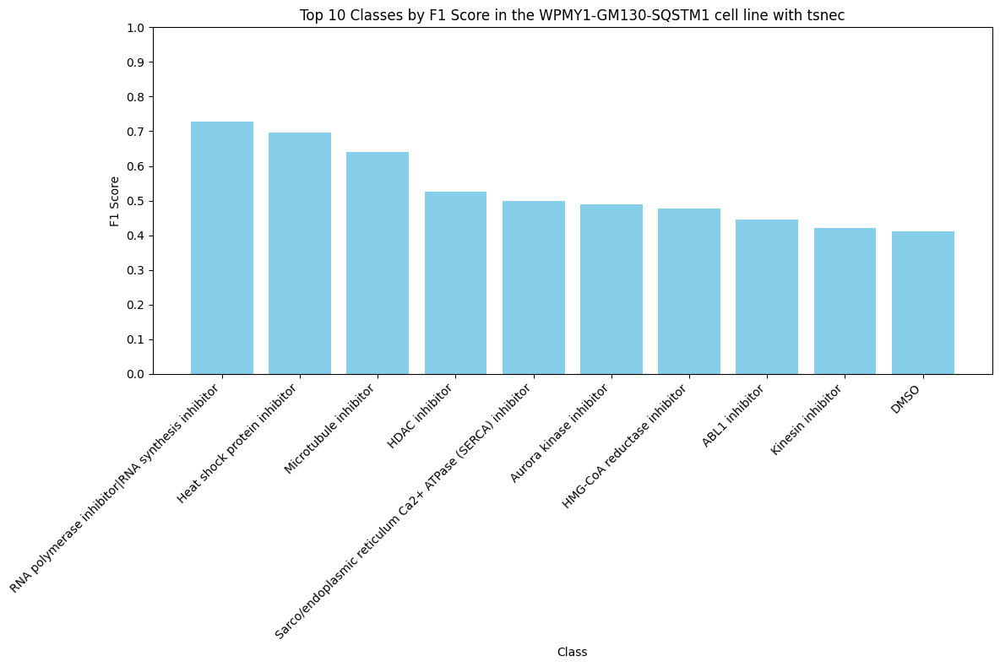

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.27363658013812814, test score = 0.25601333650869257, cell line = WPMY1-GM130-SQSTM1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


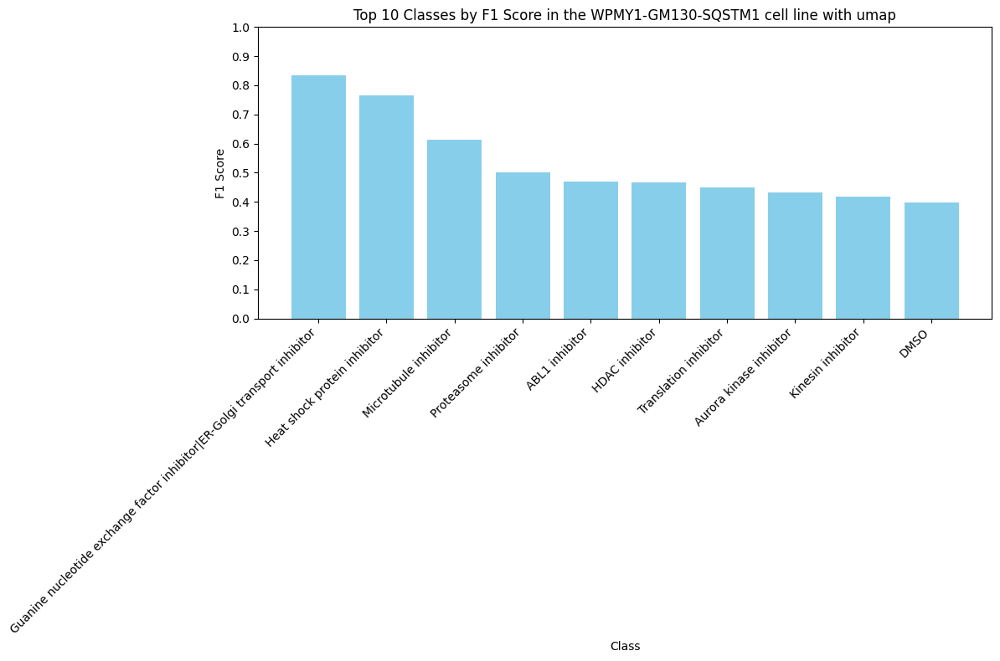

k = 50, training score = 0.25295258240789703, test score = 0.24653349001175087, cell line = HepG2-ACTB-RAB5A, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


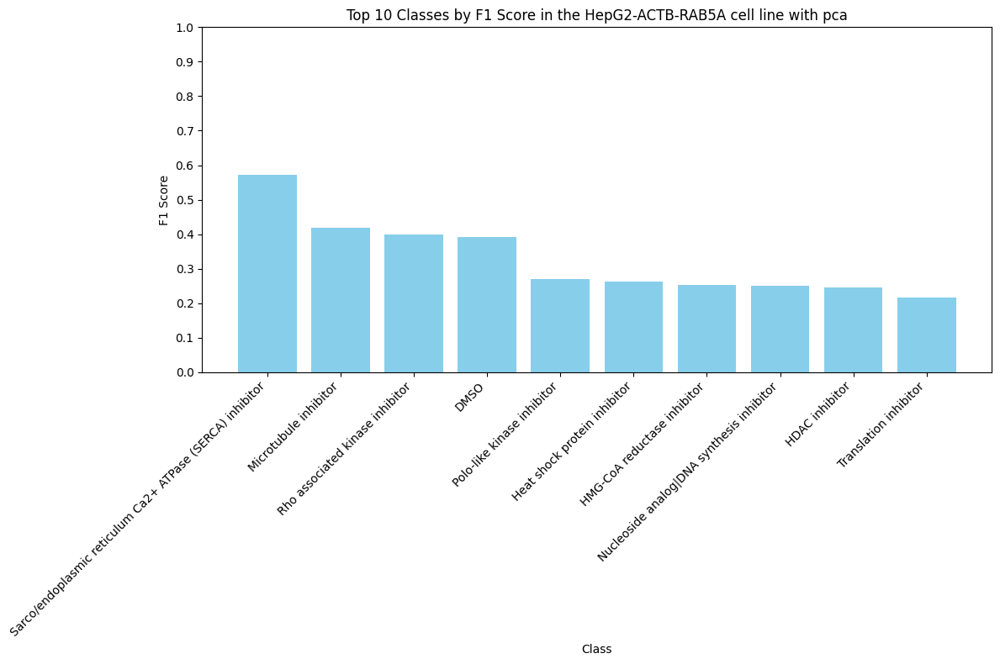

k = 50, training score = 0.2832716375815265, test score = 0.27356051703877793, cell line = HepG2-ACTB-RAB5A, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


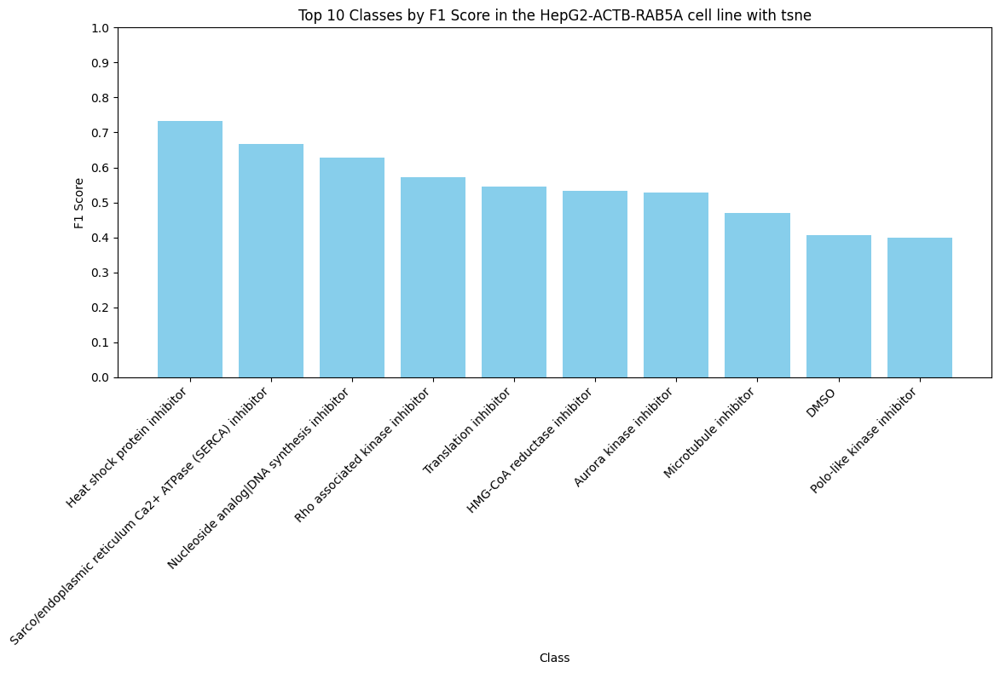

k = 50, training score = 0.28415300546448086, test score = 0.27356051703877793, cell line = HepG2-ACTB-RAB5A, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


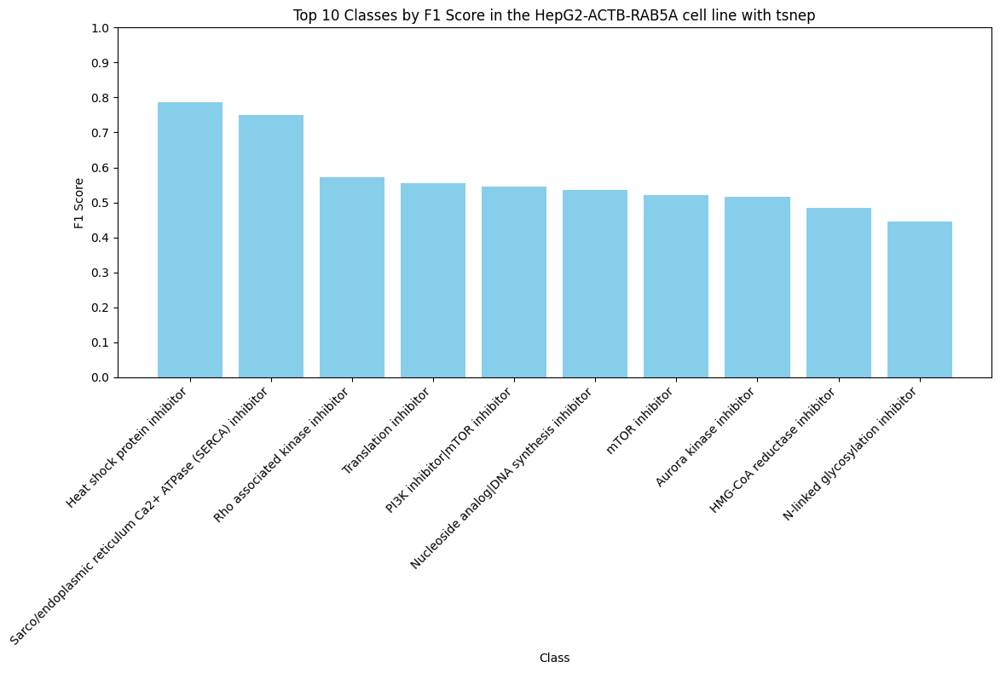

k = 50, training score = 0.2900287913508432, test score = 0.2810810810810811, cell line = HepG2-ACTB-RAB5A, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


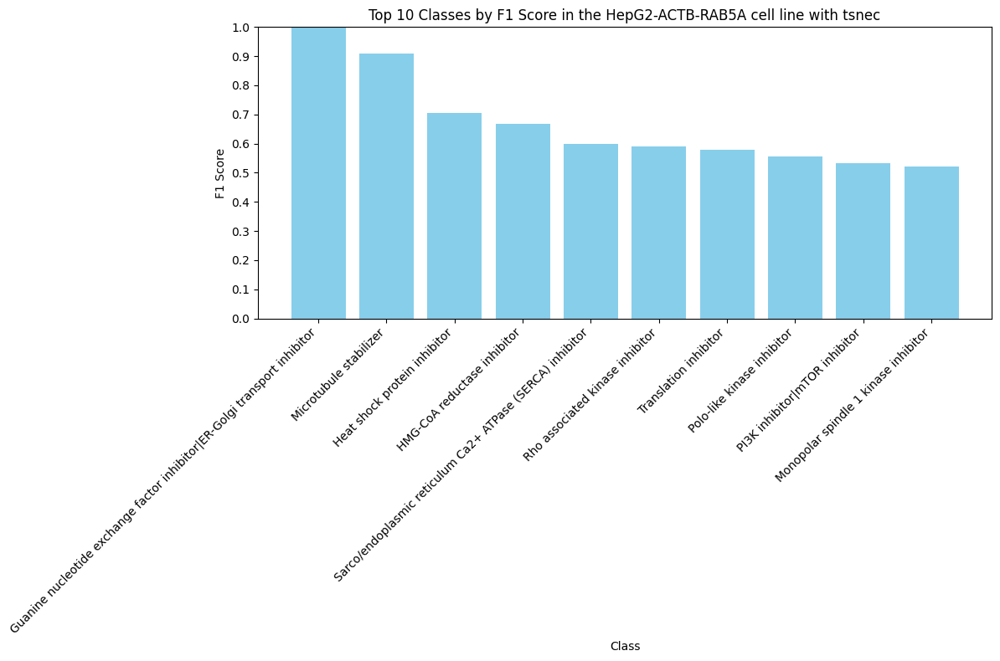

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2809213232269816, test score = 0.27403055229142187, cell line = HepG2-ACTB-RAB5A, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


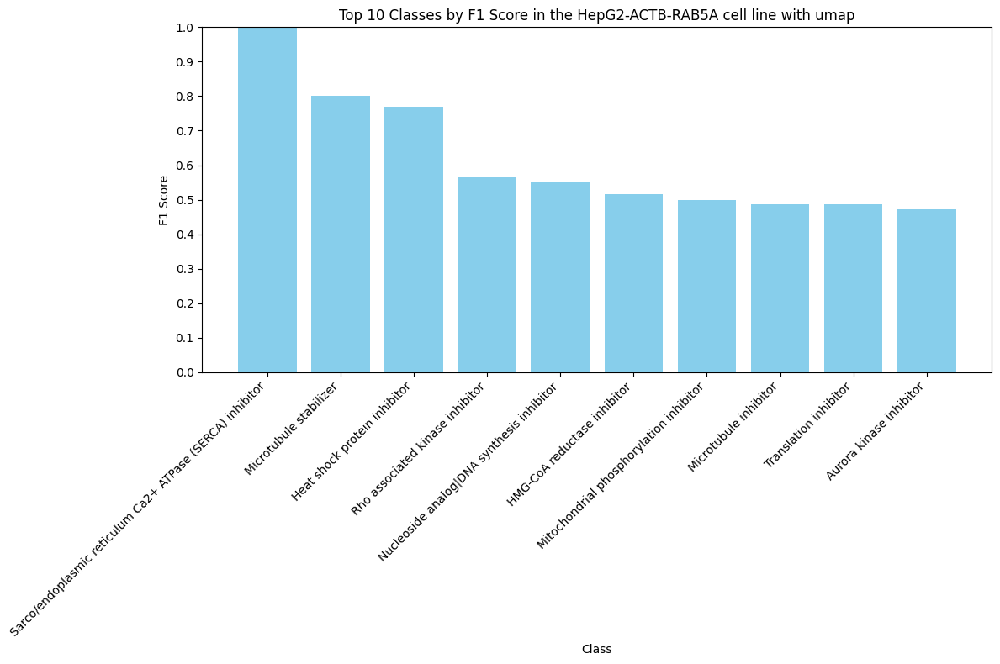

k = 50, training score = 0.24941176470588236, test score = 0.2444130792754646, cell line = HepG2-CANX-COX4I1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


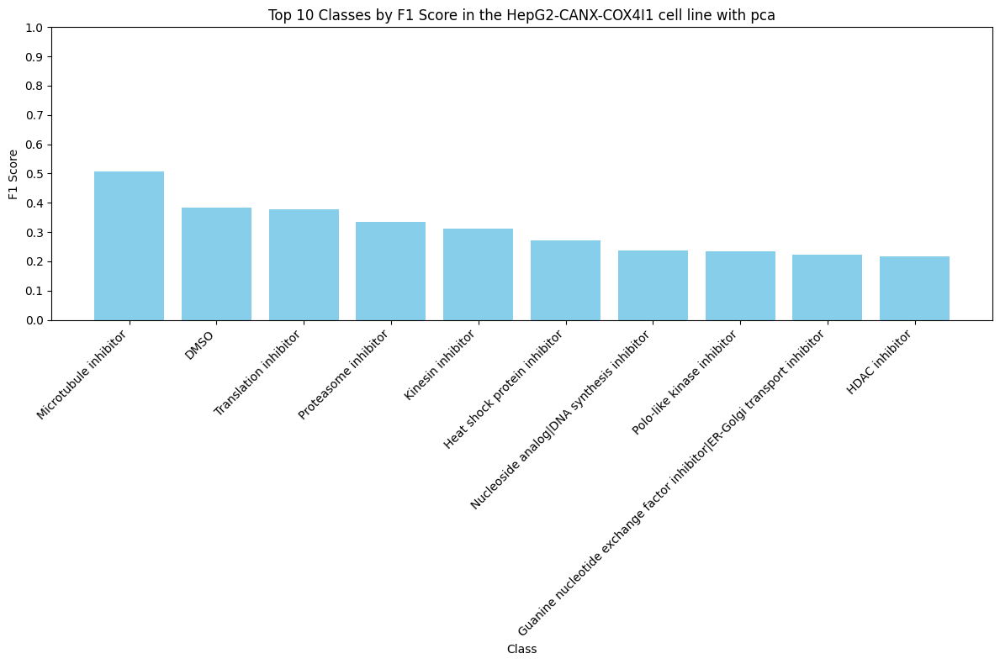

k = 50, training score = 0.2817058823529412, test score = 0.27217125382262997, cell line = HepG2-CANX-COX4I1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


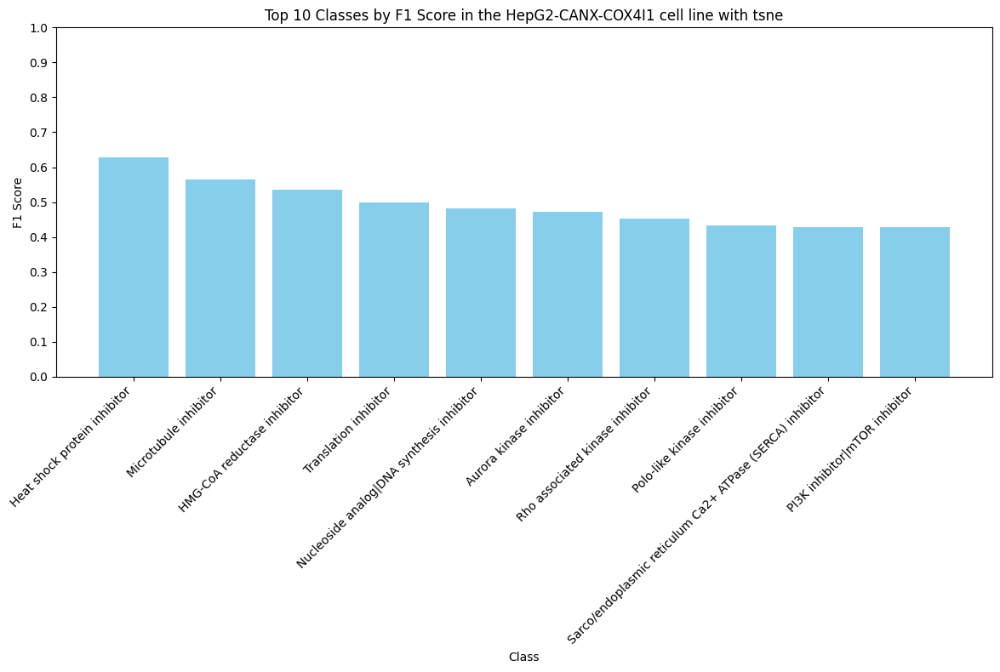

k = 50, training score = 0.284, test score = 0.2740531639614208, cell line = HepG2-CANX-COX4I1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


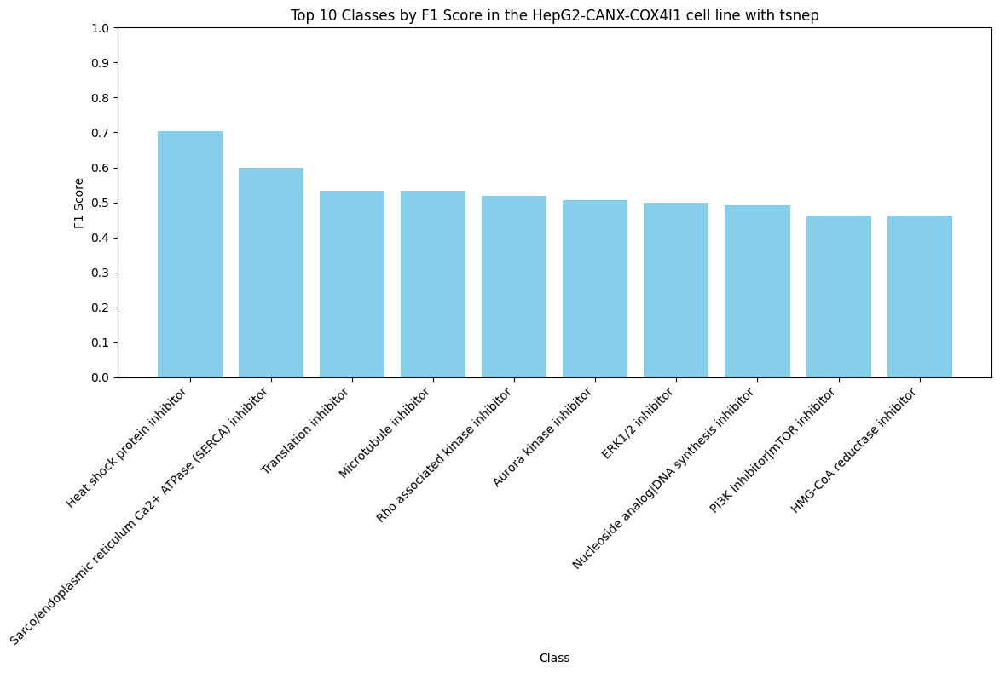

k = 50, training score = 0.28923529411764703, test score = 0.2799341331451423, cell line = HepG2-CANX-COX4I1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


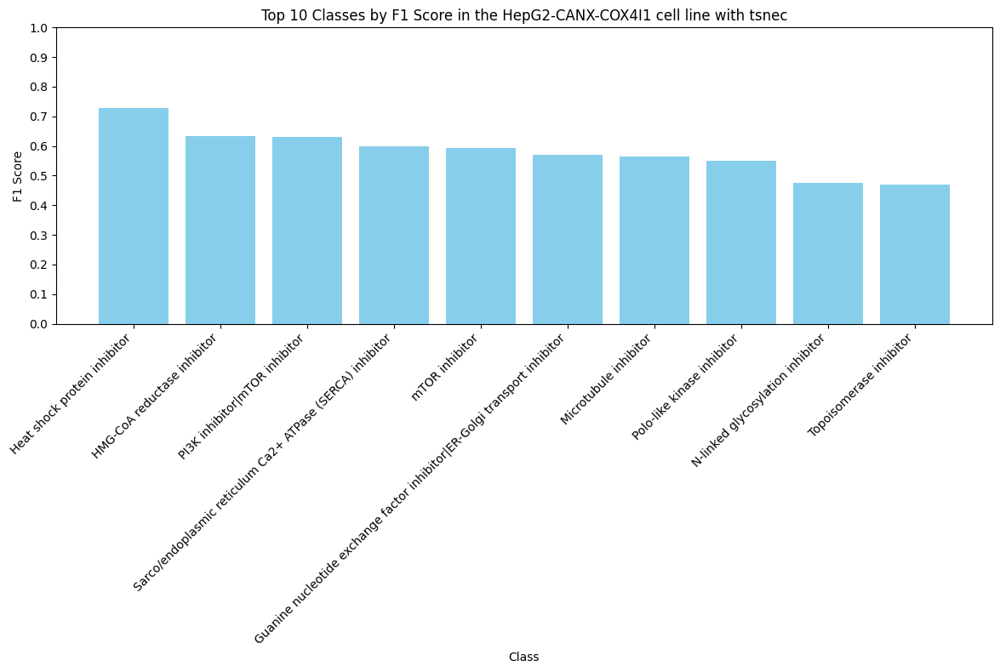

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2811176470588235, test score = 0.2747588802634674, cell line = HepG2-CANX-COX4I1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


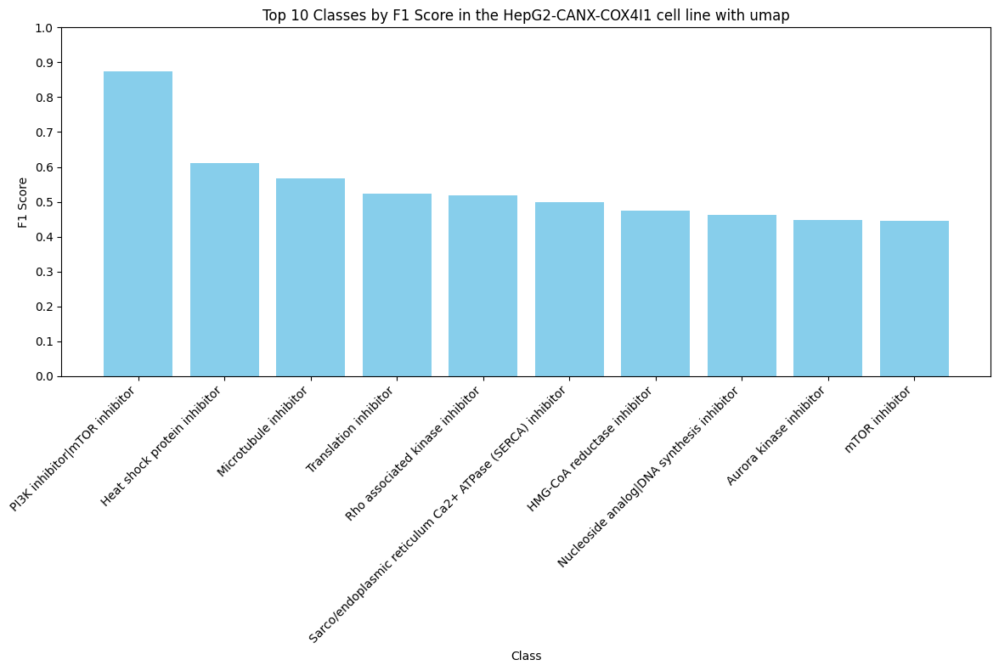

k = 50, training score = 0.2548351066956675, test score = 0.2525276275570186, cell line = HepG2-GM130-SQSTM1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


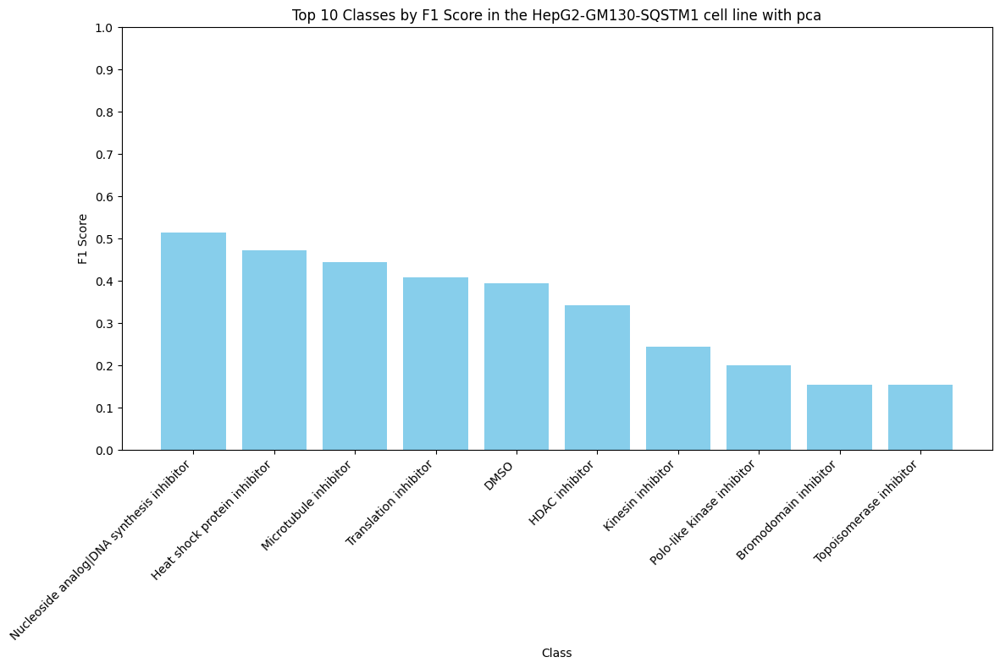

k = 50, training score = 0.28916583387220035, test score = 0.28285915824124147, cell line = HepG2-GM130-SQSTM1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


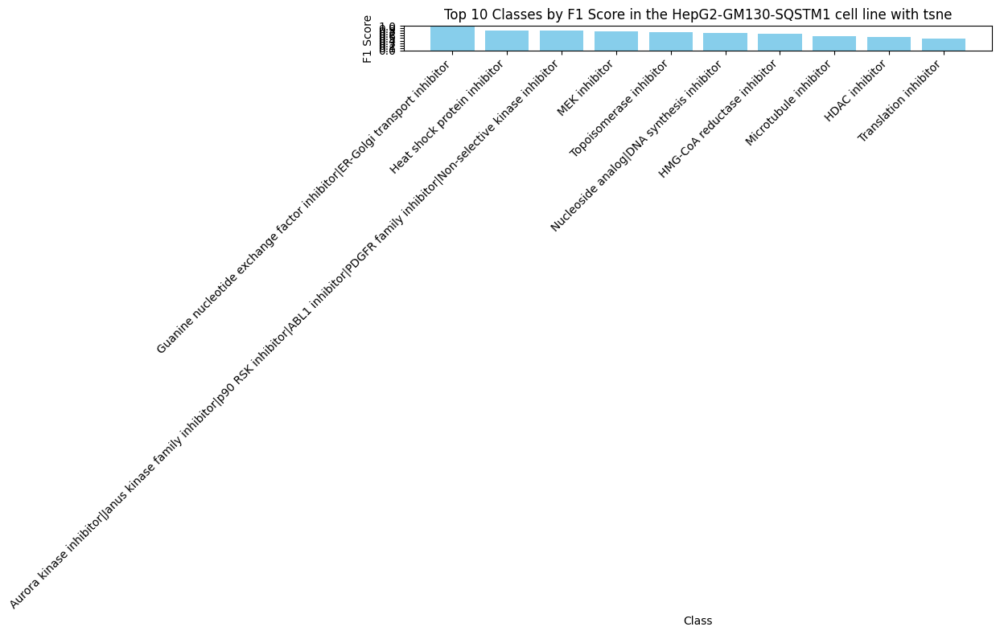

k = 50, training score = 0.28704955616953737, test score = 0.2823889019515636, cell line = HepG2-GM130-SQSTM1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


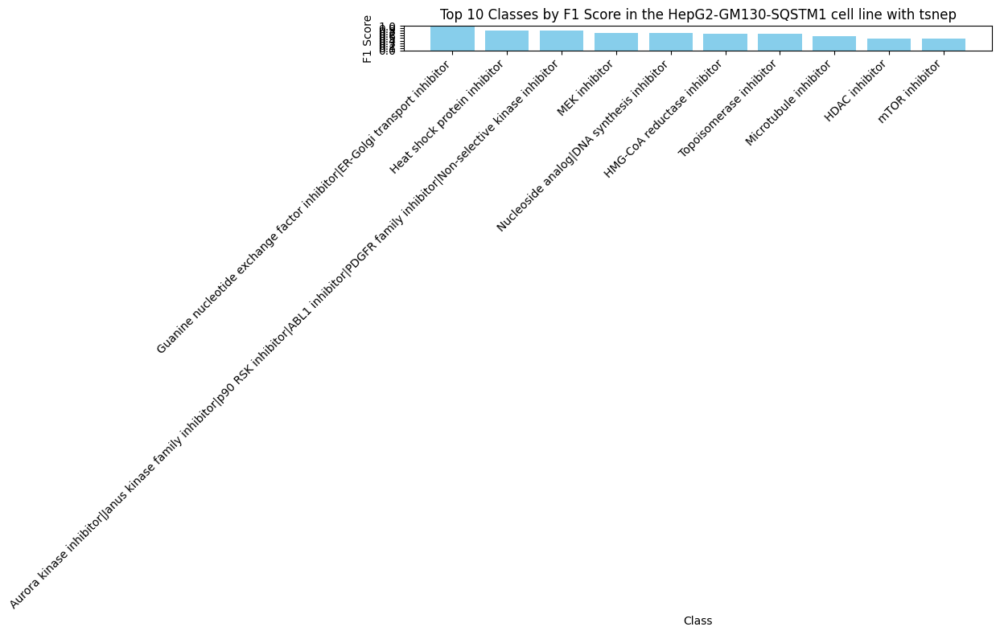

k = 50, training score = 0.29192875198401036, test score = 0.284740183399953, cell line = HepG2-GM130-SQSTM1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


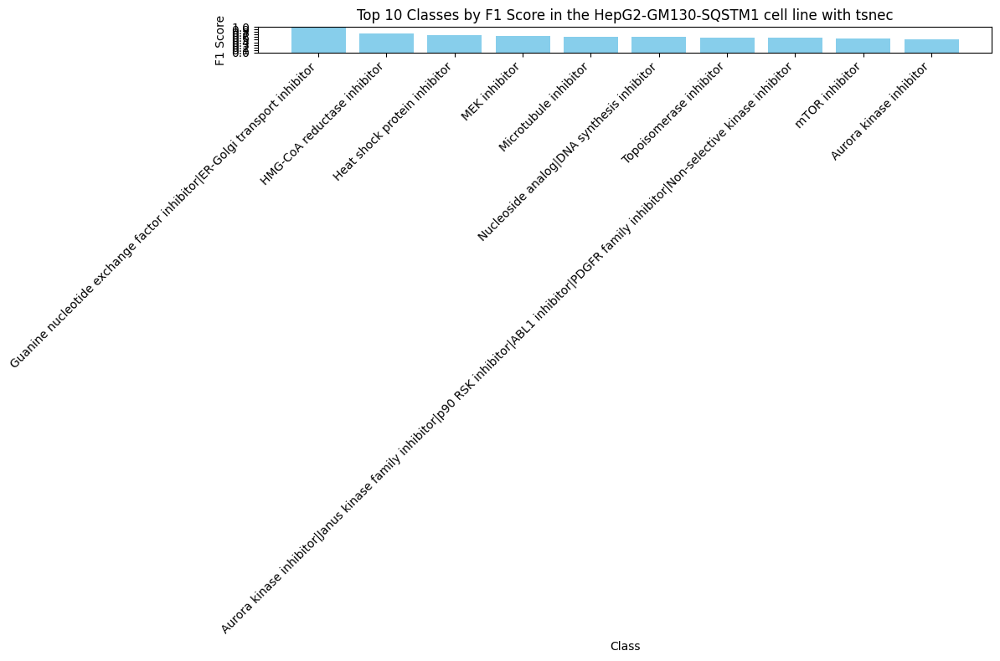

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.28381635412380224, test score = 0.2800376205031742, cell line = HepG2-GM130-SQSTM1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


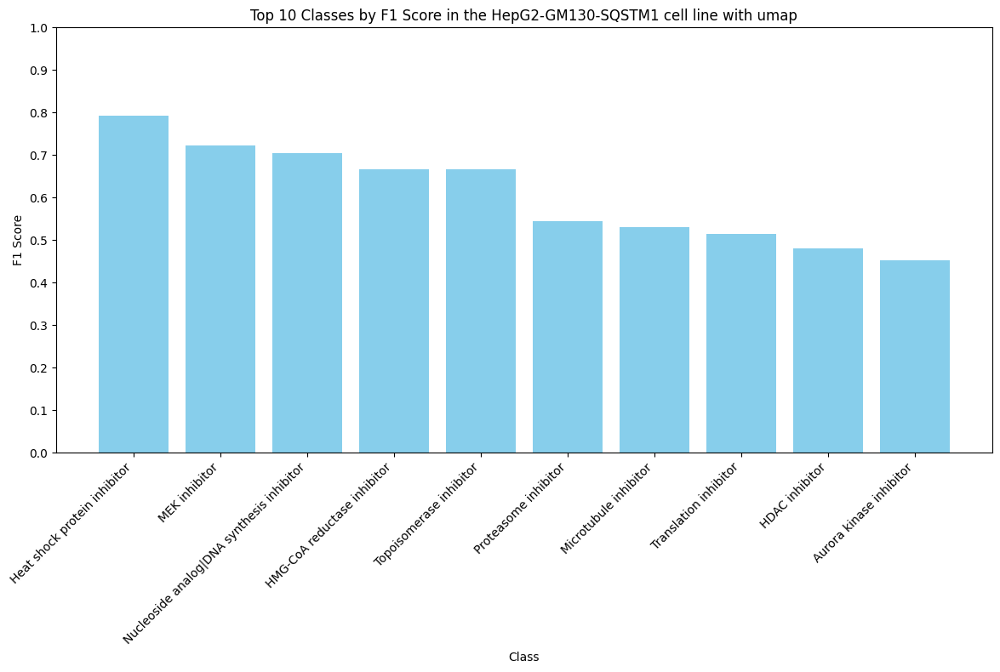

k = 50, training score = 0.2458495231367008, test score = 0.24064045208382387, cell line = WPMY1-CANX-COX4I1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


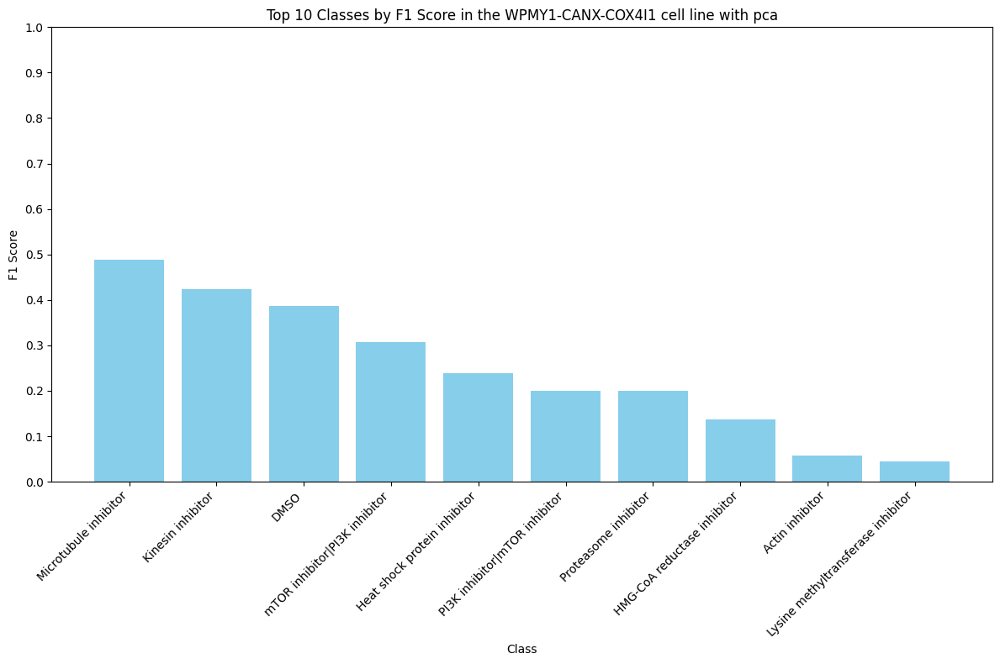

k = 50, training score = 0.2713999764511951, test score = 0.262538262302802, cell line = WPMY1-CANX-COX4I1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


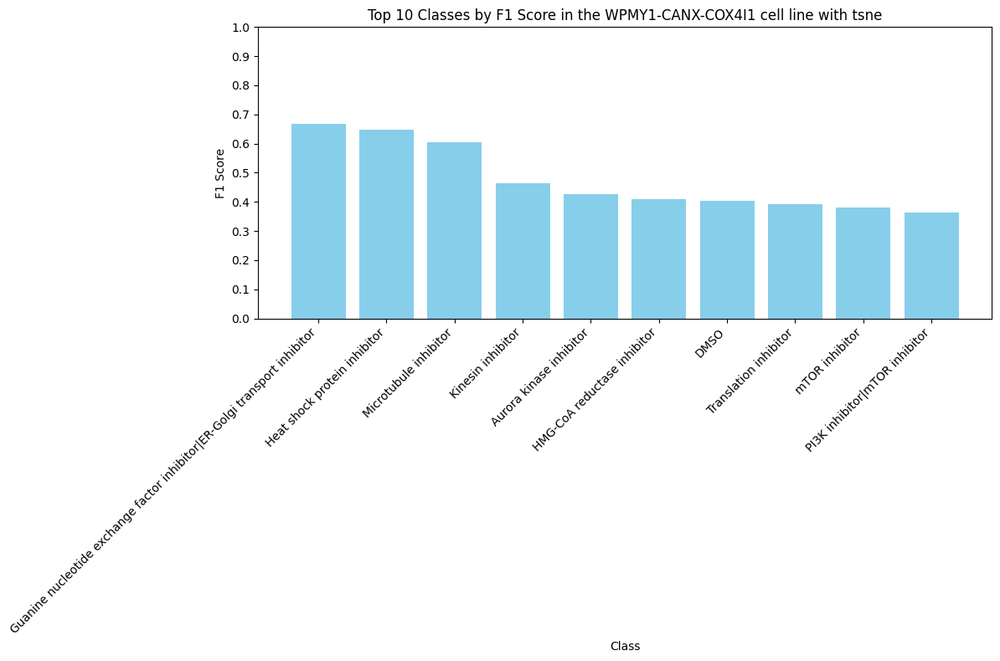

k = 50, training score = 0.2719298245614035, test score = 0.2632446432776077, cell line = WPMY1-CANX-COX4I1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


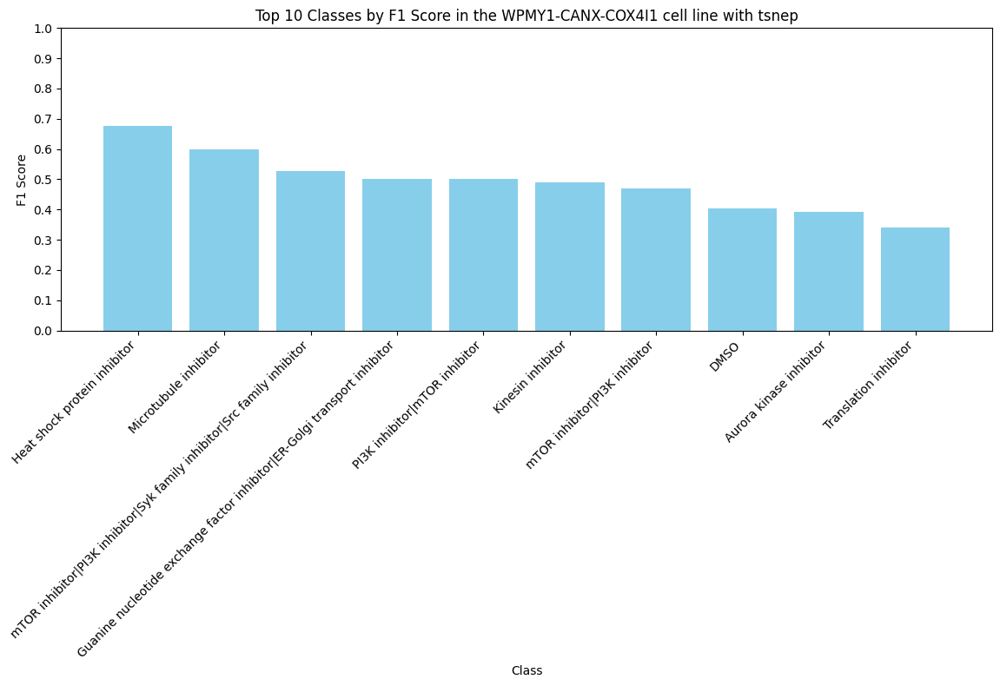

k = 50, training score = 0.27510891322265396, test score = 0.26512832587708973, cell line = WPMY1-CANX-COX4I1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


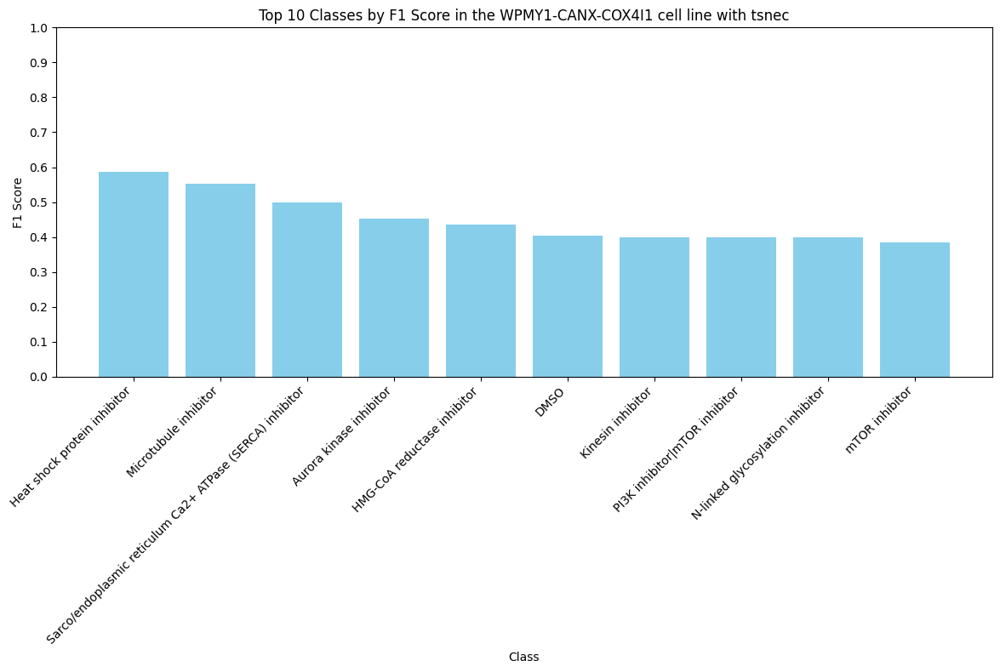

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.2692805840103615, test score = 0.26159642100306096, cell line = WPMY1-CANX-COX4I1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


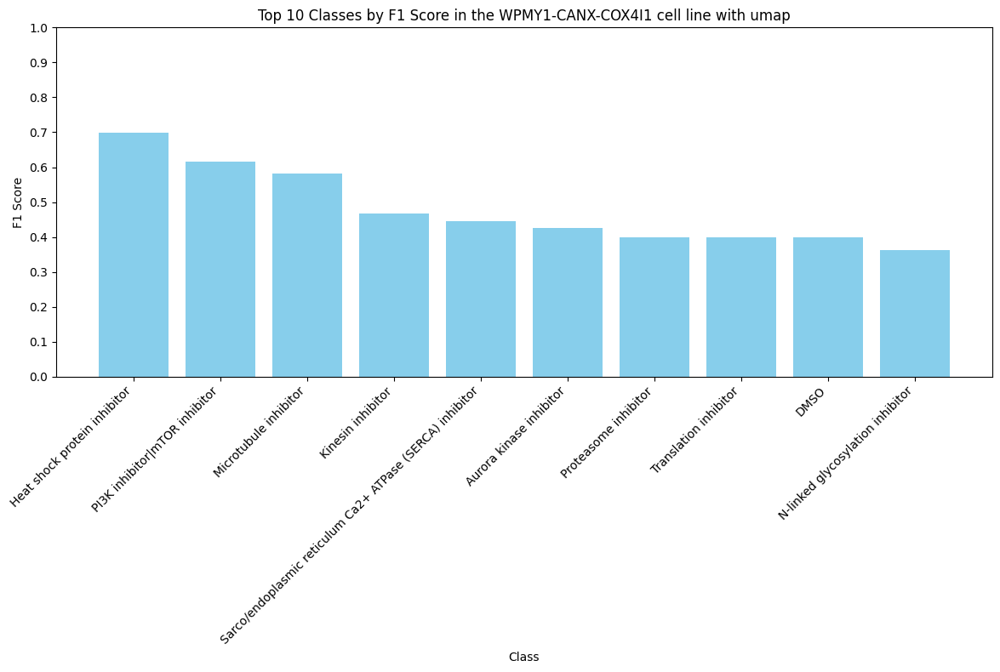

k = 50, training score = 0.24795607805693143, test score = 0.25250596658711216, cell line = WPMY1-ACTB-RAB5A, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


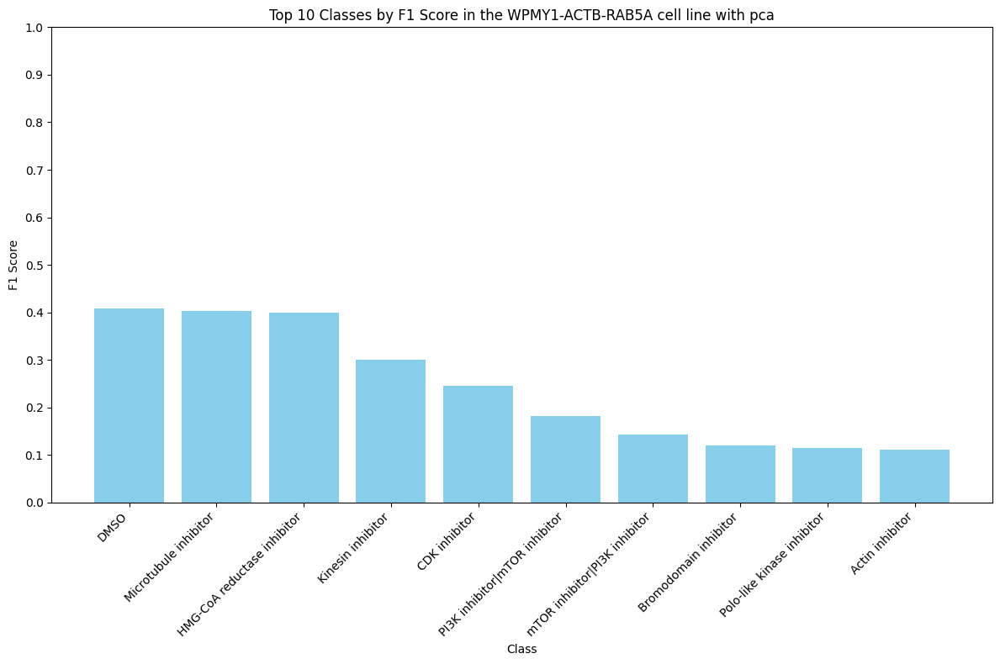

k = 50, training score = 0.28549262994569435, test score = 0.29331742243436754, cell line = WPMY1-ACTB-RAB5A, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


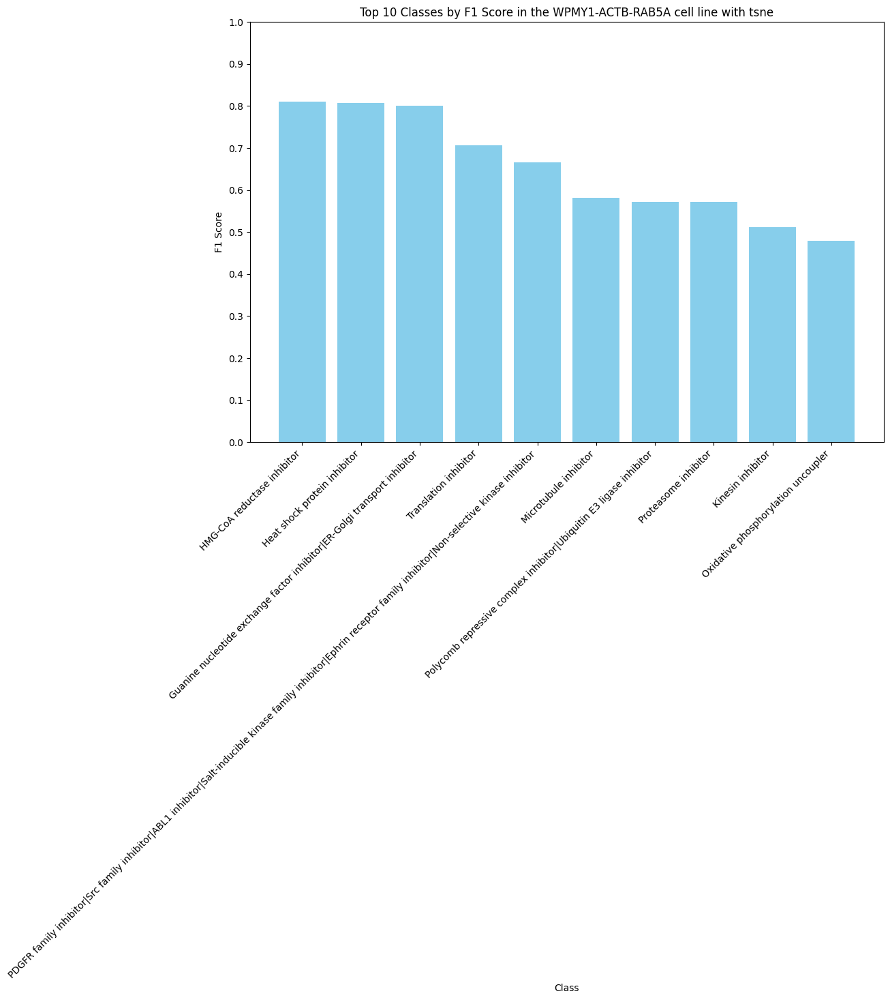

k = 50, training score = 0.2820313898669213, test score = 0.2890214797136038, cell line = WPMY1-ACTB-RAB5A, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


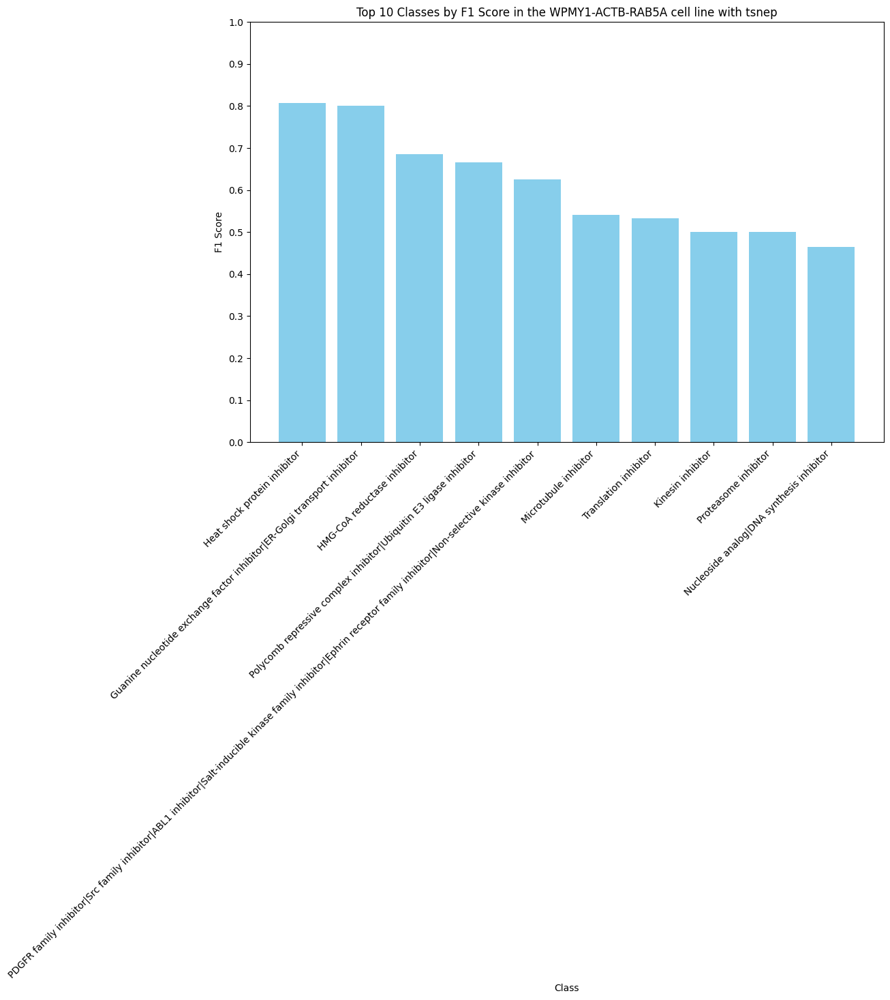

k = 50, training score = 0.2890135465775497, test score = 0.2909307875894988, cell line = WPMY1-ACTB-RAB5A, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


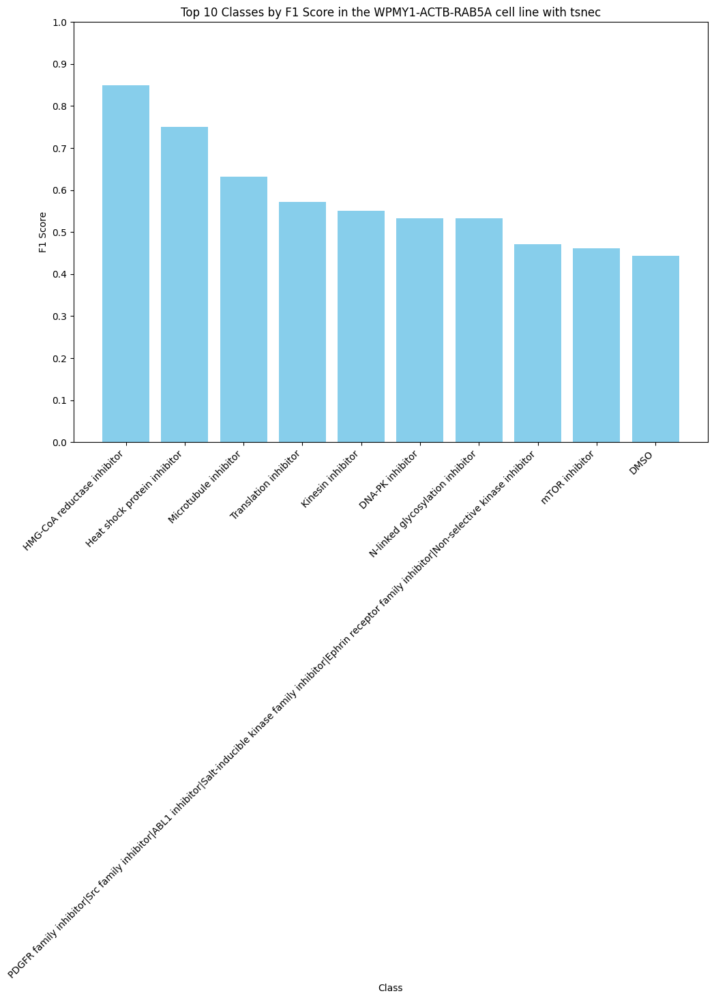

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.28119591812376915, test score = 0.2878281622911695, cell line = WPMY1-ACTB-RAB5A, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


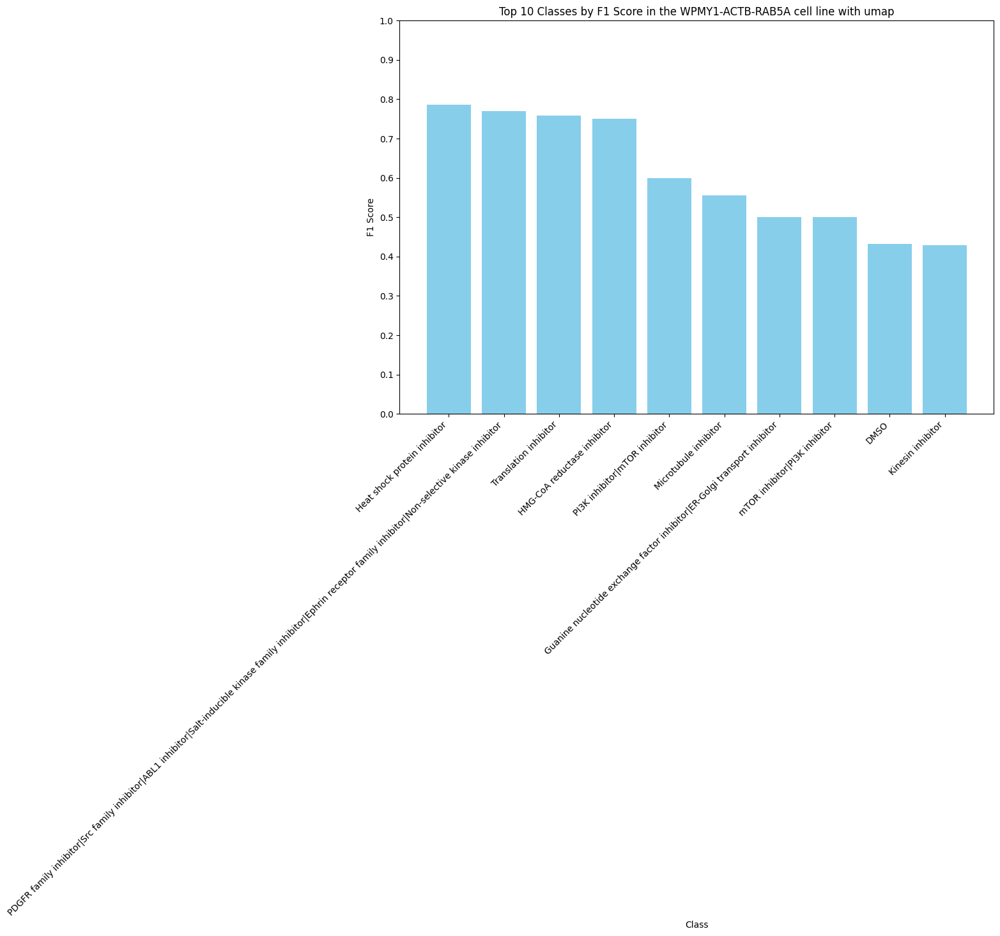

k = 50, training score = 0.2517663683466792, test score = 0.2406971267074894, cell line = A549-CANX-COX4I1, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


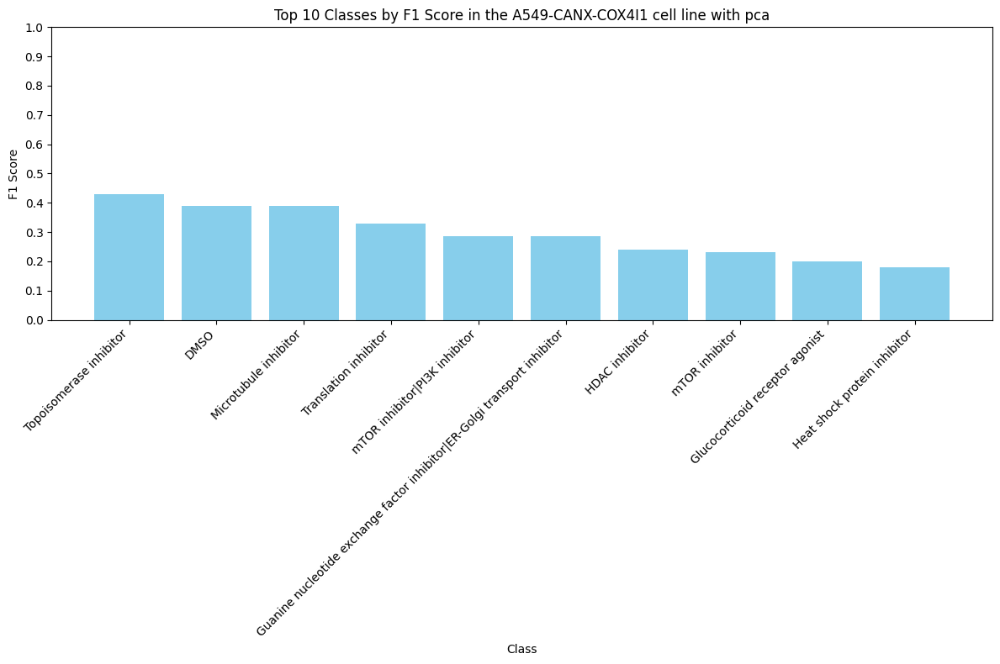

k = 50, training score = 0.2826189354686764, test score = 0.2675459255770137, cell line = A549-CANX-COX4I1, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


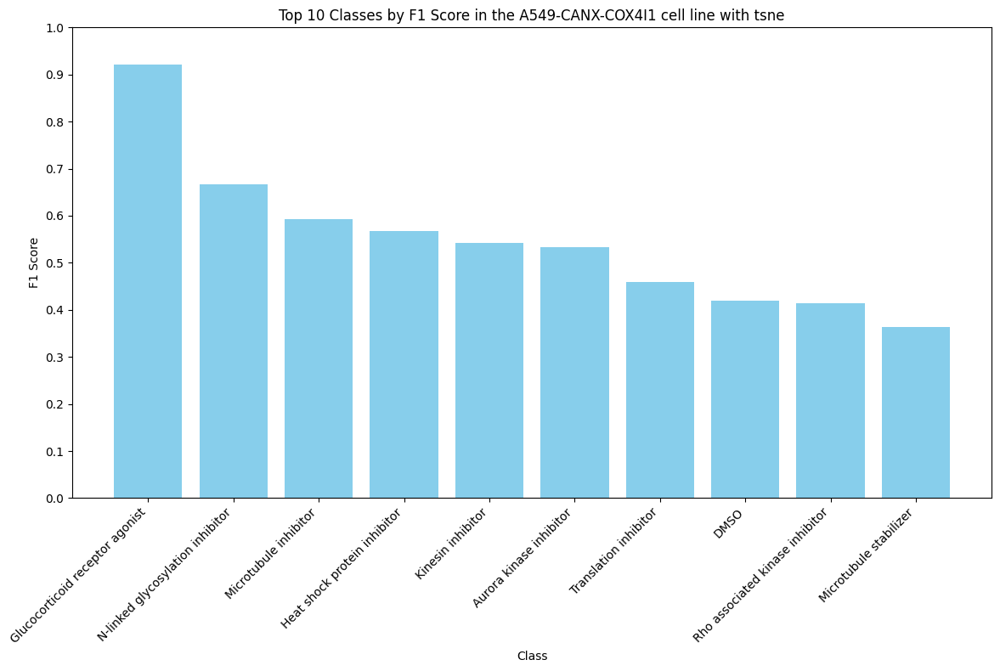

k = 50, training score = 0.2830899670277909, test score = 0.26990108337258595, cell line = A549-CANX-COX4I1, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


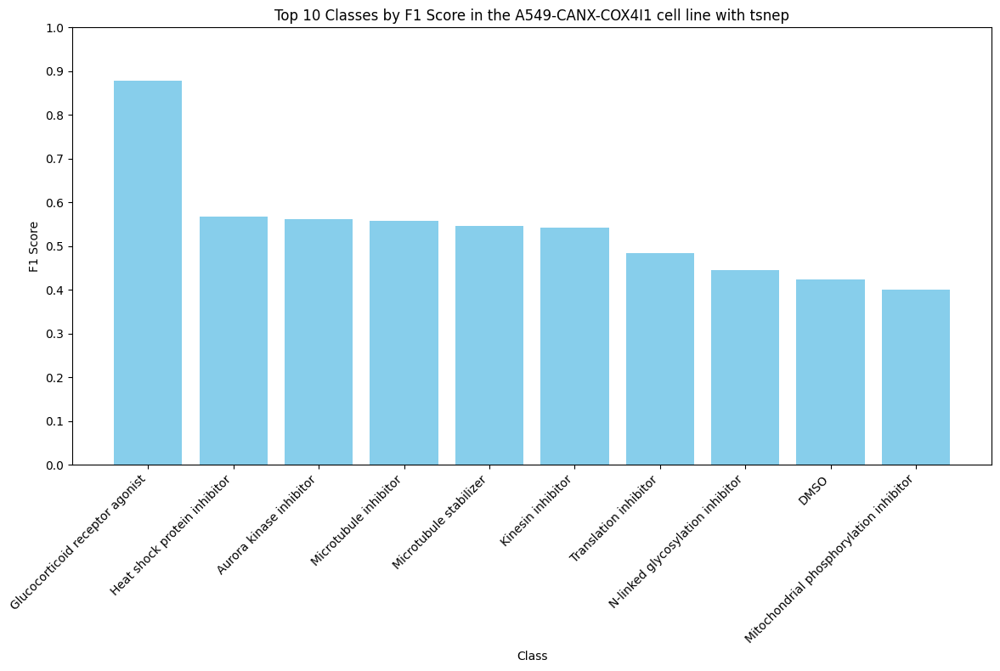

k = 50, training score = 0.2912741403674046, test score = 0.2739048516250589, cell line = A549-CANX-COX4I1, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


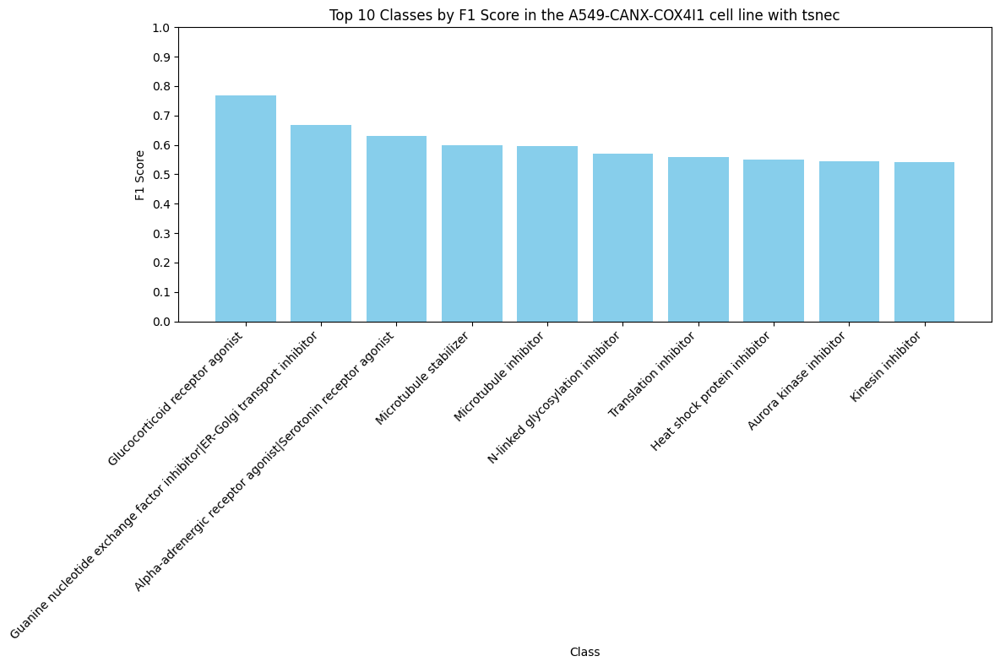

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.27991050400376827, test score = 0.2663683466792275, cell line = A549-CANX-COX4I1, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


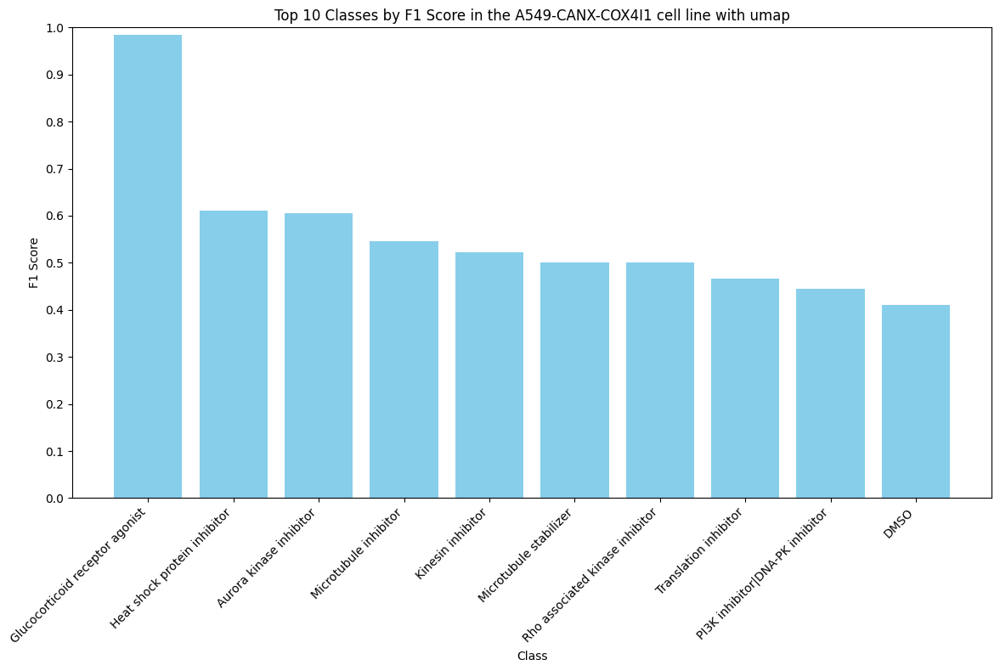

k = 50, training score = 0.25156121126428654, test score = 0.2561262959472196, cell line = A549-TP53BP1-CLTA, method = pca


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


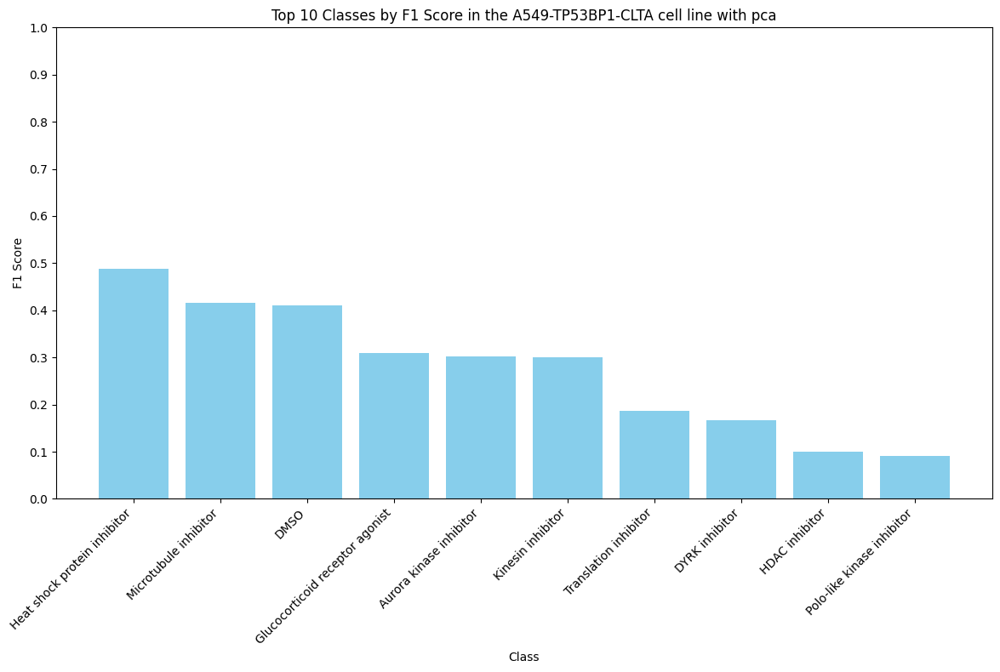

k = 50, training score = 0.2830800047130906, test score = 0.28157398680490103, cell line = A549-TP53BP1-CLTA, method = tsne


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


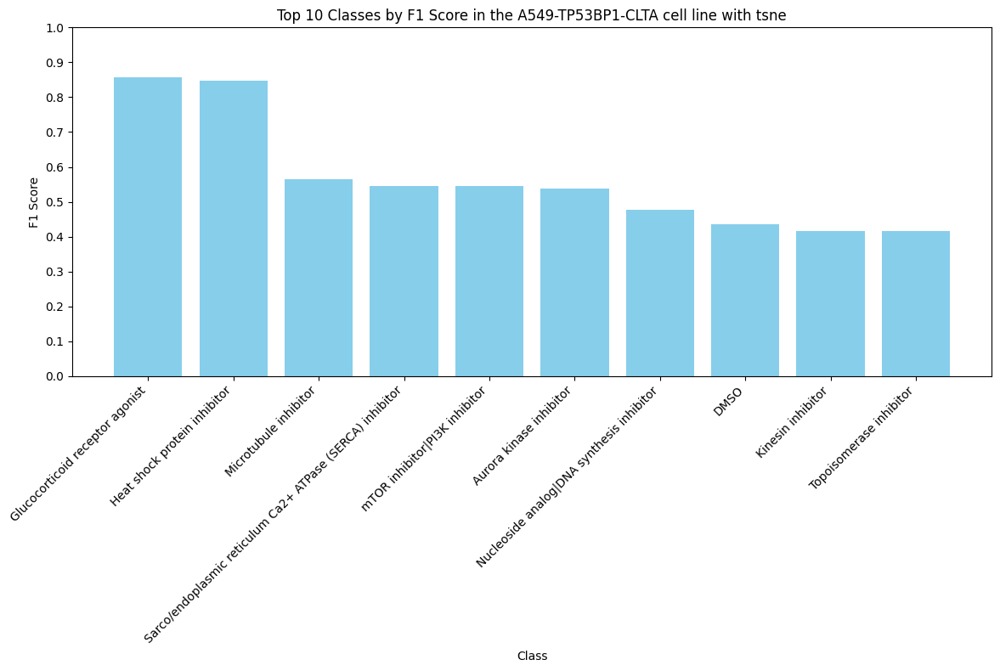

k = 50, training score = 0.28019323671497587, test score = 0.2770970782280867, cell line = A549-TP53BP1-CLTA, method = tsnep


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


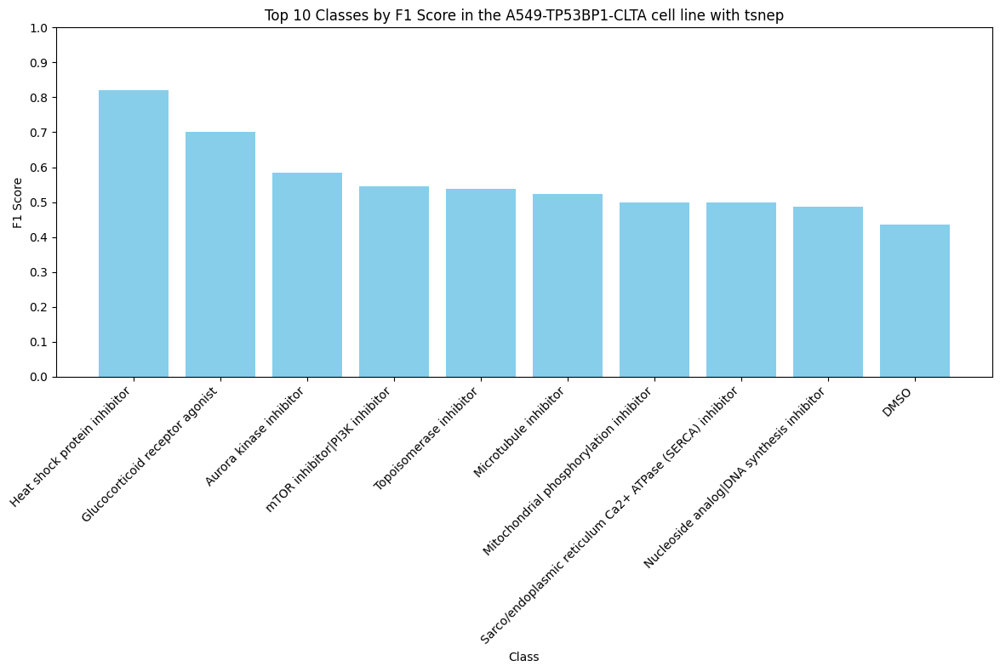

k = 50, training score = 0.29020855425945563, test score = 0.2853440150801131, cell line = A549-TP53BP1-CLTA, method = tsnec


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-132-595b55c3ec1f>:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


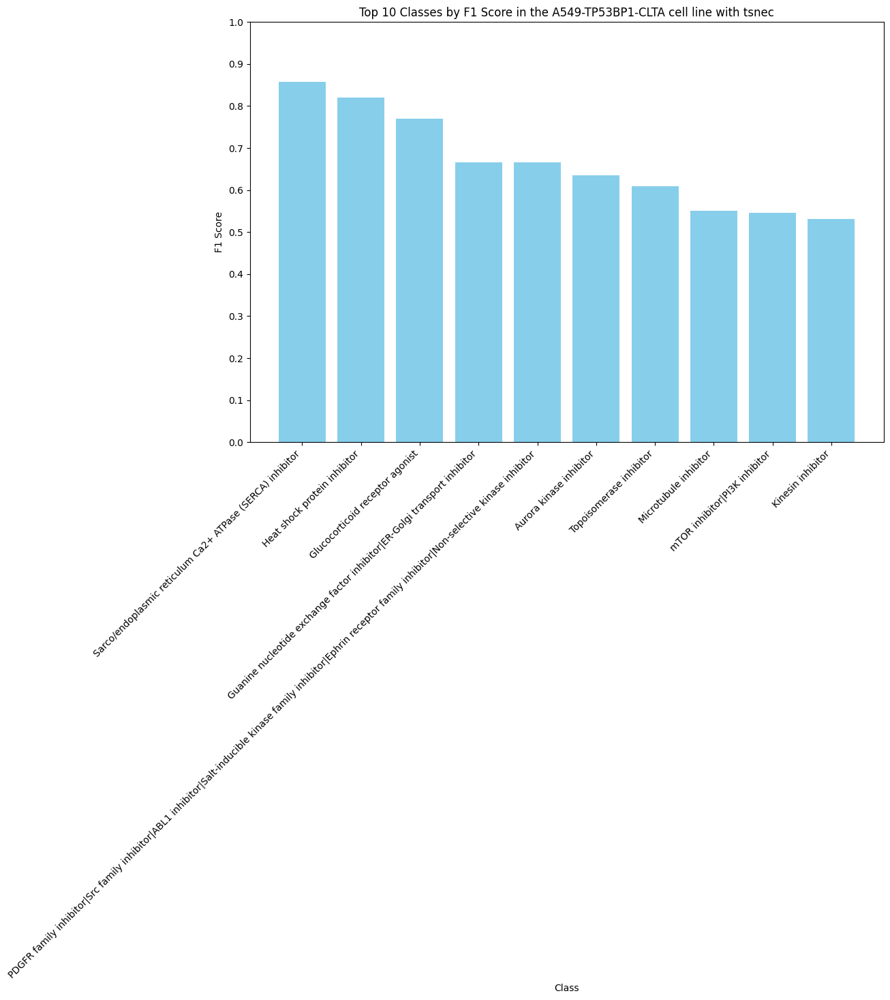

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


k = 50, training score = 0.28160716389772594, test score = 0.28039585296889724, cell line = A549-TP53BP1-CLTA, method = umap


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


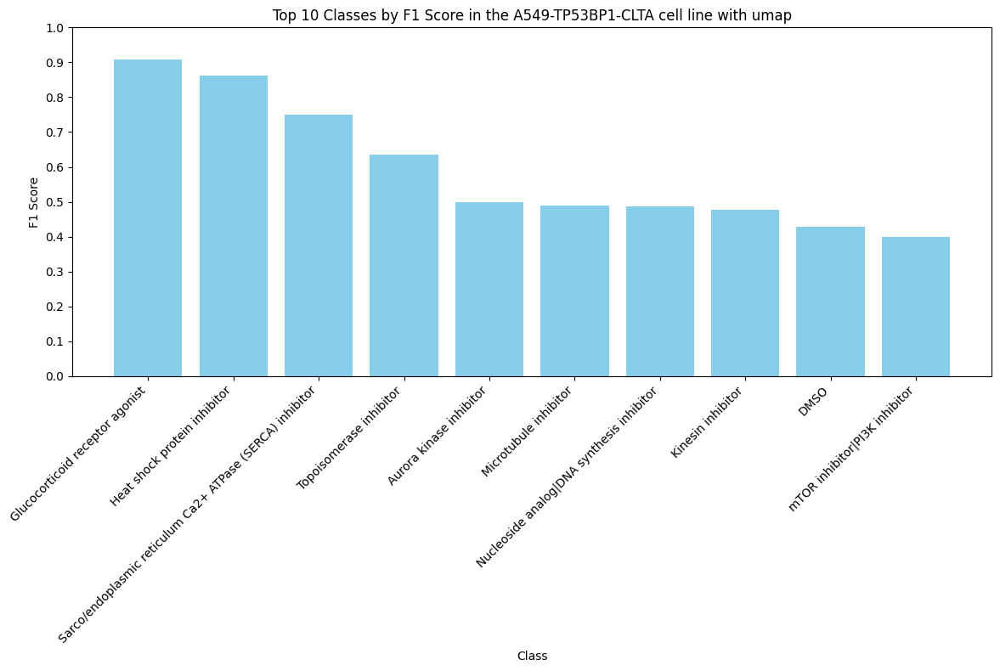

In [ ]:
for i in X['Comment [Cell Line with Markers]'].unique():
  for j in ['pca','tsne','tsnep','tsnec','umap']:
    df_A549 = X[X['Comment [Cell Line with Markers]']==i]
    scaler = StandardScaler()
    Xs = scaler.fit_transform(df_A549[df_A549.columns[4:979]])
    if(j=='pca'):
      pca = PCA(n_components=2)  # Specify the number of principal components to keep
      X_pca = pca.fit_transform(Xs)
      df = X_pca
    elif(j=='tsne'):
      tsne = TSNE(n_components=2, random_state=42)
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='tsnep'):
      tsne = TSNE(n_components=2, random_state=42, perplexity=50)
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='tsnec'):
      tsne = TSNE(n_components=2, random_state=42, metric='correlation')
      X_tsne = tsne.fit_transform(Xs)
      df = X_tsne
    elif(j=='umap'):
      umap = UMAP(n_components=2, random_state=42)
      X_umap = umap.fit_transform(Xs)
      df = X_umap
    df_A549.loc[:,'Compound MoA'] = df_A549['Compound MoA'].fillna('DMSO')
    y_train, y_test = train_test_split(df_A549['Compound MoA'], test_size=0.2, random_state=42)
    X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
    k=50
    clf = KNeighborsClassifier(n_neighbors = k)
    clf.fit(X_train, y_train)
    training_score = clf.score(X_train, y_train)
    test_score = clf.score(X_test, y_test)
    print(f'k = {k}, training score = {training_score}, test score = {test_score}, cell line = {i}, method = {j}')
    y_pred = clf.predict(X_test)
    # Calculate F1 scores for each class
    f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(df_A549['Compound MoA']))

    # Create a dictionary of class names and their F1 scores
    f1_scores_dict = {np.unique(df_A549['Compound MoA'])[i]: f1_scores[i] for i in range(len(np.unique(df_A549['Compound MoA'])))}

    # Sort the classes by their F1 score
    sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

    # Take the top 10 F1 scores (or fewer if there are not enough classes)
    top_10_f1_scores = sorted_f1_scores[:10]

    # Extract class labels and scores
    classes = [item[0] for item in top_10_f1_scores]
    scores = [item[1] for item in top_10_f1_scores]

    # Plot the bar graph
    plt.figure(figsize=(12, 8))
    plt.bar(classes, scores, color='skyblue')
    plt.xlabel('Class')
    plt.ylabel('F1 Score')
    plt.title('Top 10 Classes by F1 Score in the '+i+' cell line with ' + j)
    plt.xticks(classes)
    plt.yticks(np.arange(0, 1.1, 0.1))
    plt.xticks(classes, rotation=45, ha='right')
    plt.ylim(0, 1)  # F1 scores range from 0 to 1
    plt.tight_layout()
    plt.show()